**Step 1 — Verify your Kaggle environment**

In [1]:

import os
import tensorflow as tf

print("TensorFlow version:", tf.__version__)

gpus = tf.config.list_physical_devices("GPU")
print("Available GPUs:", gpus)

dataset_path = "/kaggle/input/datasets/iarunava/cell-images-for-detecting-malaria"

print("\nDataset path exists:", os.path.exists(dataset_path))

if os.path.exists(dataset_path):
    for root, dirs, files in os.walk(dataset_path):
        level = root.replace(dataset_path, "").count(os.sep)
        if level > 2:
            dirs[:] = []
            continue
        print(root, "| folders:", dirs[:5], "| files:", len(files))


TensorFlow version: 2.20.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]

Dataset path exists: True
/kaggle/input/datasets/iarunava/cell-images-for-detecting-malaria | folders: ['cell_images'] | files: 0
/kaggle/input/datasets/iarunava/cell-images-for-detecting-malaria/cell_images | folders: ['Parasitized', 'Uninfected', 'cell_images'] | files: 0
/kaggle/input/datasets/iarunava/cell-images-for-detecting-malaria/cell_images/Parasitized | folders: [] | files: 13780
/kaggle/input/datasets/iarunava/cell-images-for-detecting-malaria/cell_images/Uninfected | folders: [] | files: 13780
/kaggle/input/datasets/iarunava/cell-images-for-detecting-malaria/cell_images/cell_images | folders: ['Parasitized', 'Uninfected'] | files: 0


Step 2 — Prepare and split the dataset

In [2]:

import os
import pandas as pd
from sklearn.model_selection import train_test_split

dataset_path = "/kaggle/input/datasets/iarunava/cell-images-for-detecting-malaria/cell_images"

records = []

for class_name, label in [("Parasitized", 1), ("Uninfected", 0)]:
    class_path = os.path.join(dataset_path, class_name)

    for filename in os.listdir(class_path):
        if filename.lower().endswith((".png", ".jpg", ".jpeg")):
            records.append({
                "filepath": os.path.join(class_path, filename),
                "label": label,
                "class_name": class_name
            })

df = pd.DataFrame(records)

train_df, temp_df = train_test_split(
    df, test_size=0.4, random_state=42, stratify=df["label"]
)

val_df, test_df = train_test_split(
    temp_df, test_size=0.5, random_state=42, stratify=temp_df["label"]
)

train_df = train_df.copy()
val_df = val_df.copy()
test_df = test_df.copy()

train_df["split"] = "train"
val_df["split"] = "validation"
test_df["split"] = "test"

splits_df = pd.concat([train_df, val_df, test_df], ignore_index=True)
splits_df.to_csv("/kaggle/working/malaria_data_splits.csv", index=False)

print("Total images:", len(df))
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

print("\nClass distribution:")
print(pd.crosstab(splits_df["split"], splits_df["class_name"]))

print("\nSplit file saved successfully.")


Total images: 27558
Training: 16534
Validation: 5512
Testing: 5512

Class distribution:
class_name  Parasitized  Uninfected
split                              
test               2756        2756
train              8267        8267
validation         2756        2756

Split file saved successfully.


Step 3 — Image preprocessing and data pipeline

I0000 00:00:1792669273.981328      48 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792669273.985273      48 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Training batches: 517
Validation batches: 173
Testing batches: 173
Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Pixel range: 0.0 to 0.9845113158226013


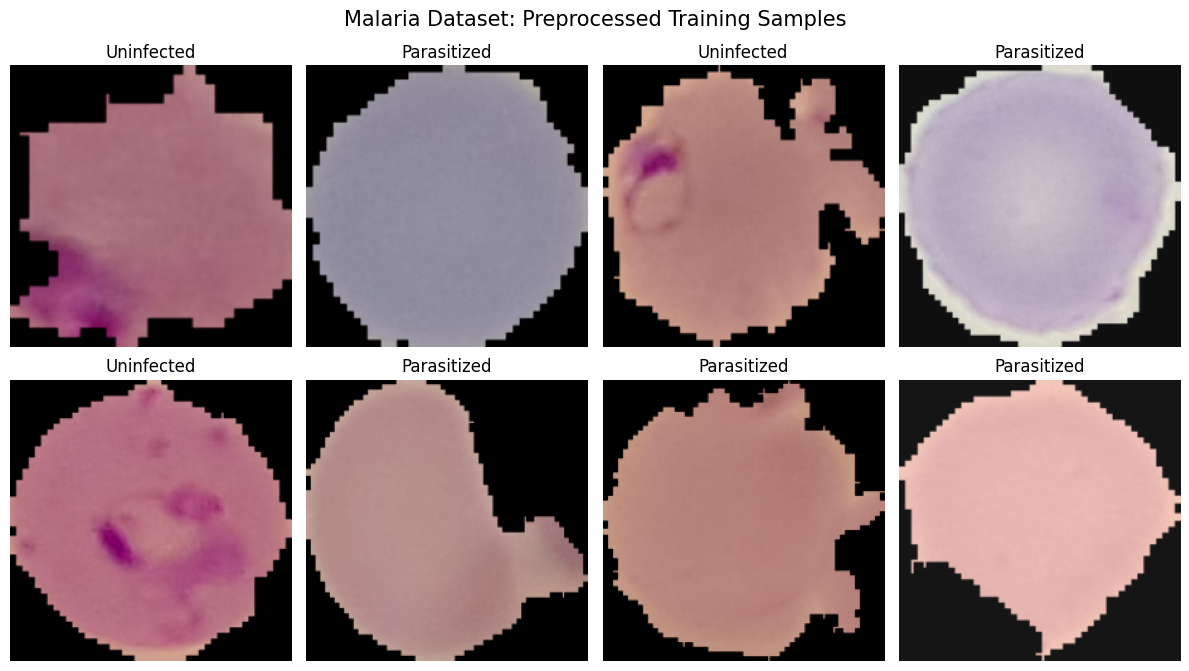

In [3]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label, training=False):
    image = tf.io.read_file(path)
    image = tf.io.decode_image(image, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0

    if training:
        image = tf.image.random_flip_left_right(image)
        image = tf.image.random_flip_up_down(image)
        image = tf.image.random_brightness(image, max_delta=0.1)
        image = tf.clip_by_value(image, 0.0, 1.0)

    return image, tf.cast(label, tf.float32)

def make_dataset(dataframe, training=False):
    paths = dataframe["filepath"].to_numpy()
    labels = dataframe["label"].to_numpy(dtype=np.float32)

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        ds = ds.shuffle(
            buffer_size=min(len(dataframe), 5000),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    ds = ds.map(
        lambda p, y: load_image(p, y, training),
        num_parallel_calls=AUTOTUNE
    )
    ds = ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return ds

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Testing batches:", tf.data.experimental.cardinality(test_ds).numpy())

images, labels = next(iter(train_ds))
print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Pixel range:", float(tf.reduce_min(images)), "to", float(tf.reduce_max(images)))

os.makedirs("/kaggle/working/malaria_results", exist_ok=True)

class_names = ["Parasitized", "Uninfected"]
fig, axes = plt.subplots(2, 4, figsize=(12, 7))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].numpy())
    ax.set_title(class_names[int(labels[i].numpy())])
    ax.axis("off")

fig.suptitle("Malaria Dataset: Preprocessed Training Samples", fontsize=15)
plt.tight_layout()
plt.savefig(
    "/kaggle/working/malaria_results/preprocessed_samples.png",
    dpi=300, bbox_inches="tight"
)
plt.show()


Step 4 — Build the first model: Optimized ResNet50

In [4]:

import os
import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

RESULTS_DIR = "/kaggle/working/malaria_results"
MODEL_PATH = os.path.join(RESULTS_DIR, "optimized_resnet50_best.keras")
os.makedirs(RESULTS_DIR, exist_ok=True)

tf.keras.utils.set_random_seed(42)

base_model = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)
base_model.trainable = False

inputs = layers.Input(shape=(224, 224, 3))
x = layers.Rescaling(scale=2.0, offset=-1.0)(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

resnet_model = Model(inputs, outputs, name="Optimized_ResNet50")

resnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

callbacks = [
    ModelCheckpoint(
        MODEL_PATH,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

resnet_model.summary()
print("\nTrainable parameters:", sum(
    int(tf.keras.backend.count_params(w))
    for w in resnet_model.trainable_weights
))
print("Model configured successfully.")


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "Optimized_ResNet50"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,850,113 (90.98 MB)

 Trainable params: 262,401 (1.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)


Trainable parameters: 262401
Model configured successfully.


Step 5 — Train ResNet50 and save results

Epoch 1/10
  1/517 ━━━━━━━━━━━━━━━━━━━━ 2:42:33 19s/step - accuracy: 0.6250 - auc: 0.4939 - loss: 0.7554 - precision: 0.6000 - recall: 0.2308

I0000 00:00:1792669718.597029     146 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


517/517 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.6025 - auc: 0.6382 - loss: 0.6652 - precision: 0.6009 - recall: 0.5908
Epoch 1: val_loss improved from None to 0.62214, saving model to /kaggle/working/malaria_results/optimized_resnet50_best.keras

Epoch 1: finished saving model to /kaggle/working/malaria_results/optimized_resnet50_best.keras
517/517 ━━━━━━━━━━━━━━━━━━━━ 735s 1s/step - accuracy: 0.6262 - auc: 0.6683 - loss: 0.6499 - precision: 0.6244 - recall: 0.6336 - val_accuracy: 0.6660 - val_auc: 0.7222 - val_loss: 0.6221 - val_precision: 0.6413 - val_recall: 0.7533 - learning_rate: 0.0010
Epoch 2/10
517/517 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step - accuracy: 0.6453 - auc: 0.6982 - loss: 0.6318 - precision: 0.6367 - recall: 0.6711
Epoch 2: val_loss improved from 0.62214 to 0.60697, saving model to /kaggle/working/malaria_results/optimized_resnet50_best.keras

Epoch 2: finished saving model to /kaggle/working/malaria_results/optimized_resnet50_best.keras
517/517 ━━━━━━━━━━━━━━━━━━━━ 6

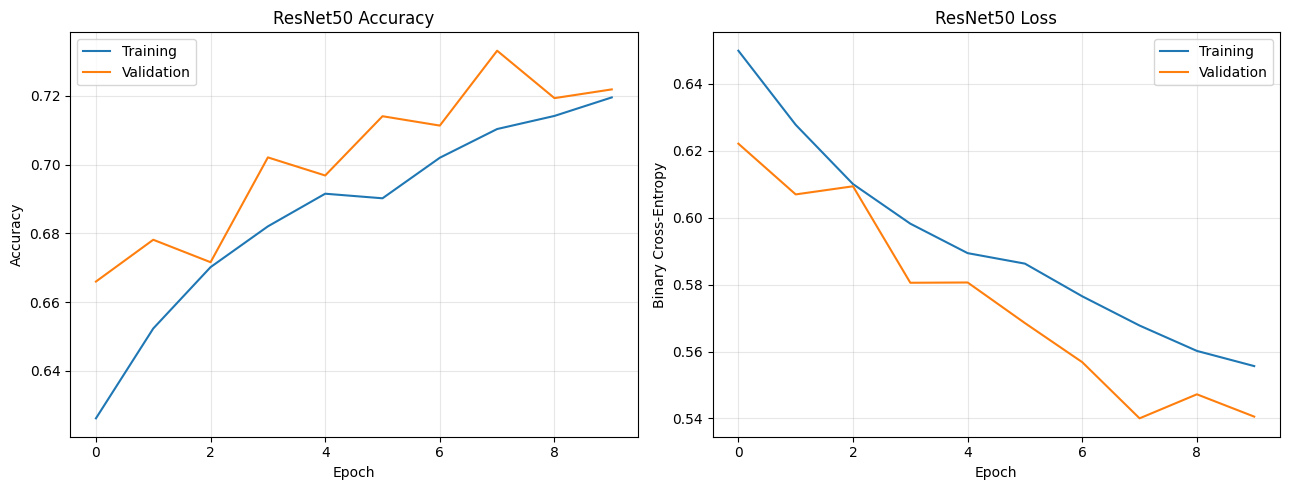


Best validation accuracy: 0.7331
Best model checkpoint: /kaggle/working/malaria_results/optimized_resnet50_best.keras
Saved results:
optimized_resnet50_best.keras
preprocessed_samples.png
resnet50_learning_curves.png
resnet50_training_history.csv
resnet50_training_history.json


In [5]:

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import os

RESULTS_DIR = "/kaggle/working/malaria_results"
os.makedirs(RESULTS_DIR, exist_ok=True)

history = resnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks,
    verbose=1
)

history_df = pd.DataFrame(history.history)
history_df.to_csv(
    os.path.join(RESULTS_DIR, "resnet50_training_history.csv"),
    index_label="epoch"
)

with open(os.path.join(RESULTS_DIR, "resnet50_training_history.json"), "w") as f:
    json.dump(
        {k: [float(v) for v in values] for k, values in history.history.items()},
        f,
        indent=2
    )

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(history.history["accuracy"], label="Training")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set_title("ResNet50 Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(history.history["loss"], label="Training")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set_title("ResNet50 Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Binary Cross-Entropy")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(
    os.path.join(RESULTS_DIR, "resnet50_learning_curves.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("\nBest validation accuracy:", round(max(history.history["val_accuracy"]), 4))
print("Best model checkpoint:", MODEL_PATH)
print("Saved results:")
for filename in sorted(os.listdir(RESULTS_DIR)):
    print(filename)


Step 6 — Fine-tune ResNet50

Epoch 1/8
517/517 ━━━━━━━━━━━━━━━━━━━━ 0s 133ms/step - accuracy: 0.6849 - auc: 0.7527 - loss: 0.5916 - precision: 0.6607 - recall: 0.7543
Epoch 1: val_loss improved from None to 0.51424, saving model to /kaggle/working/malaria_results/optimized_resnet50_finetuned_best.keras

Epoch 1: finished saving model to /kaggle/working/malaria_results/optimized_resnet50_finetuned_best.keras
517/517 ━━━━━━━━━━━━━━━━━━━━ 110s 178ms/step - accuracy: 0.7050 - auc: 0.7728 - loss: 0.5740 - precision: 0.6844 - recall: 0.7611 - val_accuracy: 0.7551 - val_auc: 0.8444 - val_loss: 0.5142 - val_precision: 0.7181 - val_recall: 0.8400 - learning_rate: 1.0000e-05
Epoch 2/8
517/517 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step - accuracy: 0.7415 - auc: 0.8152 - loss: 0.5286 - precision: 0.7302 - recall: 0.7646
Epoch 2: val_loss improved from 0.51424 to 0.44927, saving model to /kaggle/working/malaria_results/optimized_resnet50_finetuned_best.keras

Epoch 2: finished saving model to /kaggle/working/malaria_results/optimized_

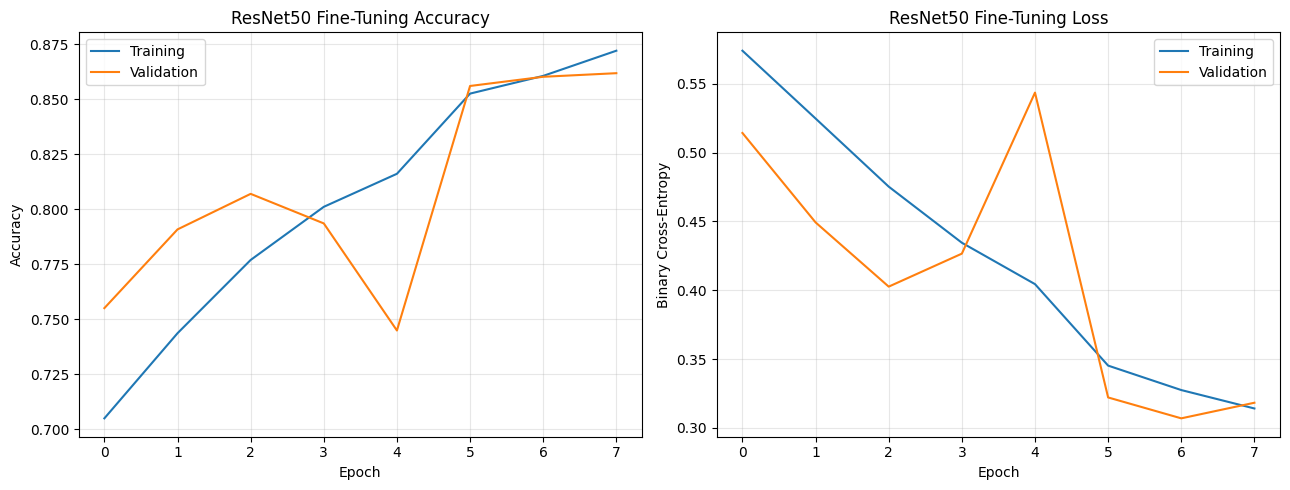

Best fine-tuning validation accuracy: 0.8618
Fine-tuned model checkpoint saved.


In [6]:

import os
import matplotlib.pyplot as plt
import pandas as pd
import tensorflow as tf

RESULTS_DIR = "/kaggle/working/malaria_results"
os.makedirs(RESULTS_DIR, exist_ok=True)

base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

resnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

fine_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        os.path.join(RESULTS_DIR, "optimized_resnet50_finetuned_best.keras"),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

fine_history = resnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    callbacks=fine_callbacks,
    verbose=1
)

pd.DataFrame(fine_history.history).to_csv(
    os.path.join(RESULTS_DIR, "resnet50_finetuning_history.csv"),
    index_label="epoch"
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(fine_history.history["accuracy"], label="Training")
axes[0].plot(fine_history.history["val_accuracy"], label="Validation")
axes[0].set_title("ResNet50 Fine-Tuning Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(fine_history.history["loss"], label="Training")
axes[1].plot(fine_history.history["val_loss"], label="Validation")
axes[1].set_title("ResNet50 Fine-Tuning Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Binary Cross-Entropy")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(
    os.path.join(RESULTS_DIR, "resnet50_finetuning_curves.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Best fine-tuning validation accuracy:",
      round(max(fine_history.history["val_accuracy"]), 4))
print("Fine-tuned model checkpoint saved.")


Step 7 — Final test-set evaluation

173/173 ━━━━━━━━━━━━━━━━━━━━ 22s 105ms/step
TEST SET RESULTS
Accuracy: 0.8587
Precision: 0.8537
Recall: 0.8657
F1-score: 0.8597
ROC-AUC: 0.9413
Average Precision: 0.9462

Classification report:
              precision    recall  f1-score   support

 Parasitized     0.8638    0.8516    0.8577      2756
  Uninfected     0.8537    0.8657    0.8597      2756

    accuracy                         0.8587      5512
   macro avg     0.8587    0.8587    0.8587      5512
weighted avg     0.8587    0.8587    0.8587      5512



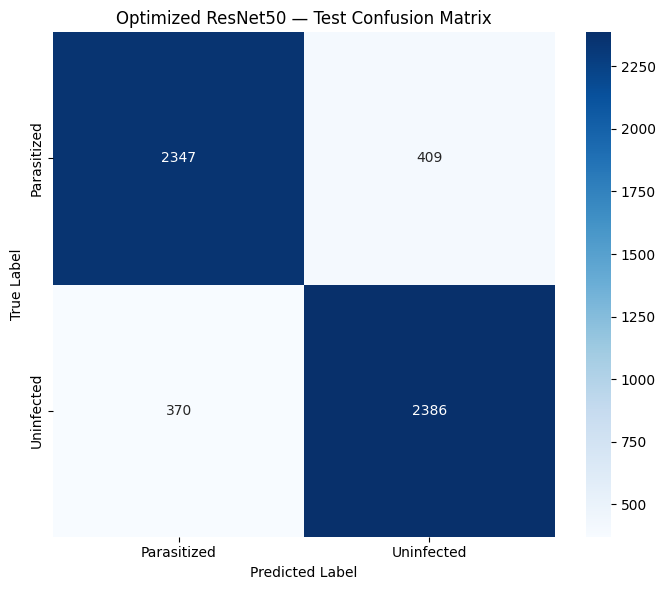

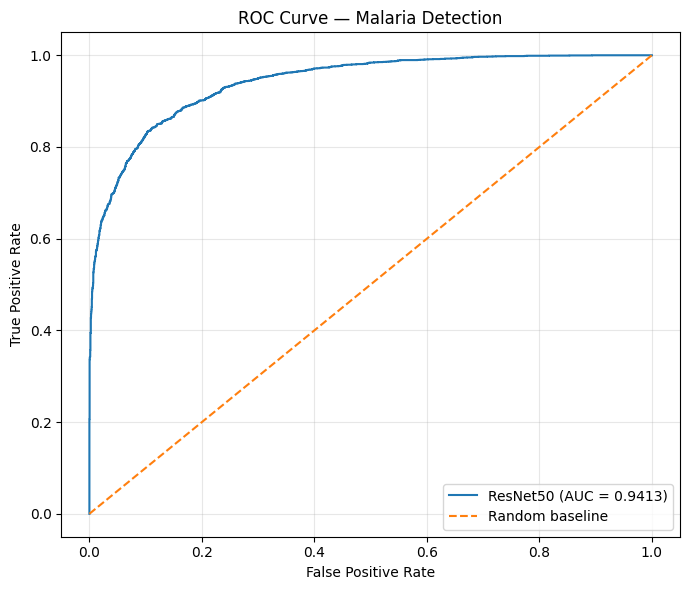

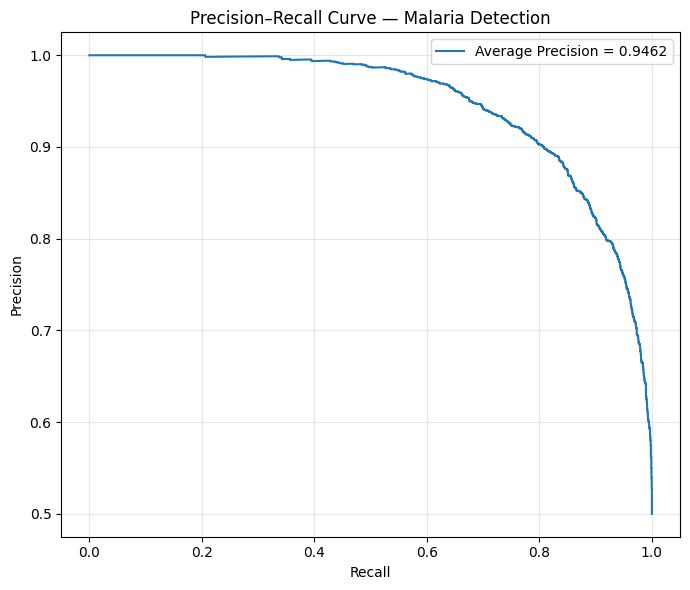


Saved evaluation artifacts:
optimized_resnet50_best.keras
optimized_resnet50_finetuned_best.keras
preprocessed_samples.png
resnet50_confusion_matrix.png
resnet50_finetuning_curves.png
resnet50_finetuning_history.csv
resnet50_learning_curves.png
resnet50_precision_recall_curve.png
resnet50_roc_curve.png
resnet50_test_metrics.csv
resnet50_test_predictions.csv
resnet50_training_history.csv
resnet50_training_history.json


In [7]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, roc_curve, precision_recall_curve,
    auc
)

RESULTS_DIR = "/kaggle/working/malaria_results"
MODEL_PATH = os.path.join(
    RESULTS_DIR, "optimized_resnet50_finetuned_best.keras"
)

best_model = tf.keras.models.load_model(MODEL_PATH)

y_true = np.concatenate([
    labels.numpy().astype(int) for _, labels in test_ds
])

y_prob = best_model.predict(test_ds, verbose=1).ravel()
y_pred = (y_prob >= 0.5).astype(int)

metrics = {
    "Accuracy": accuracy_score(y_true, y_pred),
    "Precision": precision_score(y_true, y_pred, zero_division=0),
    "Recall": recall_score(y_true, y_pred, zero_division=0),
    "F1-score": f1_score(y_true, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_true, y_prob),
    "Average Precision": average_precision_score(y_true, y_prob)
}

print("TEST SET RESULTS")
for name, value in metrics.items():
    print(f"{name}: {value:.4f}")

print("\nClassification report:")
print(classification_report(
    y_true, y_pred,
    target_names=["Parasitized", "Uninfected"],
    digits=4,
    zero_division=0
))

pd.DataFrame([metrics]).to_csv(
    os.path.join(RESULTS_DIR, "resnet50_test_metrics.csv"),
    index=False
)

pd.DataFrame({
    "true_label": y_true,
    "predicted_probability": y_prob,
    "predicted_label": y_pred
}).to_csv(
    os.path.join(RESULTS_DIR, "resnet50_test_predictions.csv"),
    index=False
)

cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Parasitized", "Uninfected"],
    yticklabels=["Parasitized", "Uninfected"],
    ax=ax
)
ax.set_title("Optimized ResNet50 — Test Confusion Matrix")
ax.set_xlabel("Predicted Label")
ax.set_ylabel("True Label")
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "resnet50_confusion_matrix.png"),
            dpi=300, bbox_inches="tight")
plt.show()

fpr, tpr, _ = roc_curve(y_true, y_prob)
roc_value = auc(fpr, tpr)

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(fpr, tpr, label=f"ResNet50 (AUC = {roc_value:.4f})")
ax.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
ax.set_title("ROC Curve — Malaria Detection")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "resnet50_roc_curve.png"),
            dpi=300, bbox_inches="tight")
plt.show()

pr_precision, pr_recall, _ = precision_recall_curve(y_true, y_prob)

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(pr_recall, pr_precision,
        label=f"Average Precision = {metrics['Average Precision']:.4f}")
ax.set_title("Precision–Recall Curve — Malaria Detection")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "resnet50_precision_recall_curve.png"),
            dpi=300, bbox_inches="tight")
plt.show()

print("\nSaved evaluation artifacts:")
for filename in sorted(os.listdir(RESULTS_DIR)):
    print(filename)


Step 8 — Error Analysis and Misclassified Images

Total test images: 5512
Misclassified images: 779
Error rate: 14.13%

Error types:
predicted_class  Parasitized  Uninfected
true_class                              
Parasitized                0         409
Uninfected               370           0


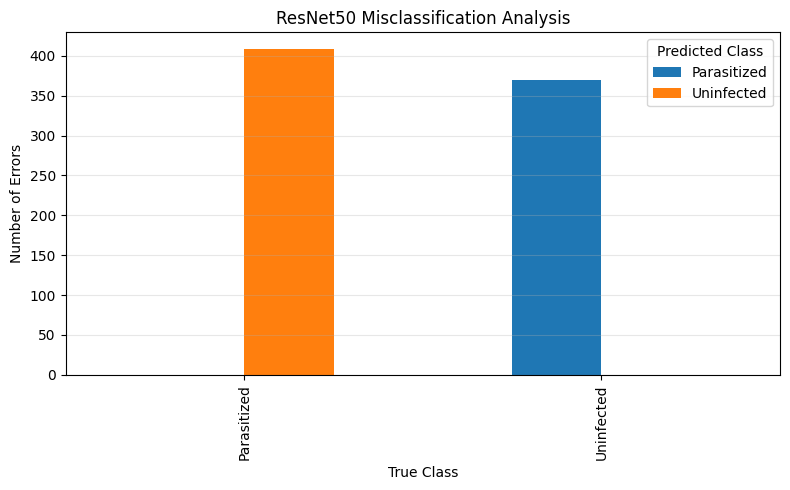


Saved:
/kaggle/working/malaria_results/resnet50_misclassified_images.csv
/kaggle/working/malaria_results/resnet50_error_analysis.png


In [8]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

RESULTS_DIR = "/kaggle/working/malaria_results"
os.makedirs(RESULTS_DIR, exist_ok=True)

predictions_path = os.path.join(
    RESULTS_DIR, "resnet50_test_predictions.csv"
)

pred_df = pd.read_csv(predictions_path)

class_names = ["Parasitized", "Uninfected"]
pred_df["true_class"] = pred_df["true_label"].astype(int).map(
    dict(enumerate(class_names))
)
pred_df["predicted_class"] = pred_df["predicted_label"].astype(int).map(
    dict(enumerate(class_names))
)

errors = pred_df[pred_df["true_label"] != pred_df["predicted_label"]].copy()
errors.to_csv(
    os.path.join(RESULTS_DIR, "resnet50_misclassified_images.csv"),
    index=False
)

print("Total test images:", len(pred_df))
print("Misclassified images:", len(errors))
print("Error rate: {:.2f}%".format(100 * len(errors) / len(pred_df)))
print("\nError types:")
print(pd.crosstab(errors["true_class"], errors["predicted_class"]))

fig, ax = plt.subplots(figsize=(8, 5))
error_counts = pd.crosstab(
    errors["true_class"], errors["predicted_class"]
).reindex(
    index=class_names, columns=class_names, fill_value=0
)

error_counts.plot(kind="bar", ax=ax)
ax.set_title("ResNet50 Misclassification Analysis")
ax.set_xlabel("True Class")
ax.set_ylabel("Number of Errors")
ax.legend(title="Predicted Class")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(
    os.path.join(RESULTS_DIR, "resnet50_error_analysis.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("\nSaved:")
print(os.path.join(RESULTS_DIR, "resnet50_misclassified_images.csv"))
print(os.path.join(RESULTS_DIR, "resnet50_error_analysis.png"))


Step 9 — Visualize correctly and incorrectly classified cells

173/173 ━━━━━━━━━━━━━━━━━━━━ 14s 81ms/step


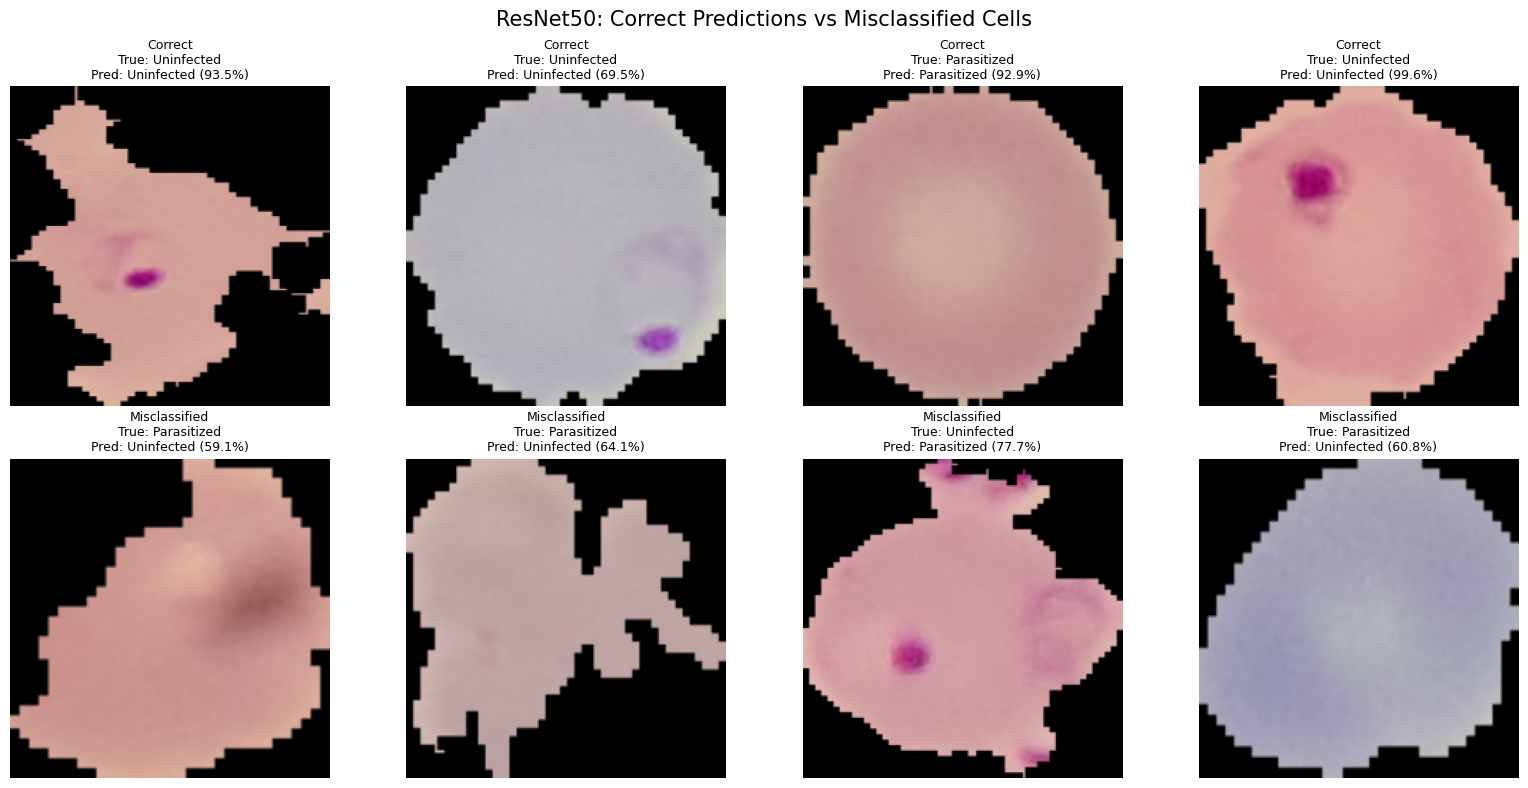

Figure saved: /kaggle/working/malaria_results/resnet50_prediction_examples.png


/kaggle/working/malaria_results/resnet50_prediction_examples.png

In [9]:

import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

RESULTS_DIR = "/kaggle/working/malaria_results"
os.makedirs(RESULTS_DIR, exist_ok=True)

class_names = ["Parasitized", "Uninfected"]

images_list, labels_list = [], []

for images, labels in test_ds:
    images_list.append(images.numpy())
    labels_list.append(labels.numpy())

X_test = np.concatenate(images_list)
y_true = np.concatenate(labels_list).astype(int)

y_prob = best_model.predict(test_ds, verbose=1).ravel()
y_pred = (y_prob >= 0.5).astype(int)

errors = np.where(y_true != y_pred)[0]
correct = np.where(y_true == y_pred)[0]

rng = np.random.default_rng(42)
selected_errors = rng.choice(errors, size=min(4, len(errors)), replace=False)
selected_correct = rng.choice(correct, size=min(4, len(correct)), replace=False)
selected = np.concatenate([selected_correct, selected_errors])

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for ax, idx in zip(axes.flat, selected):
    img = X_test[idx]
    img = np.clip(img, 0, 1)

    ax.imshow(img)
    true_name = class_names[y_true[idx]]
    pred_name = class_names[y_pred[idx]]
    confidence = y_prob[idx] if y_pred[idx] == 1 else 1 - y_prob[idx]

    status = "Correct" if y_true[idx] == y_pred[idx] else "Misclassified"
    ax.set_title(
        f"{status}\nTrue: {true_name}\nPred: {pred_name} ({confidence:.1%})",
        fontsize=9
    )
    ax.axis("off")

plt.suptitle("ResNet50: Correct Predictions vs Misclassified Cells", fontsize=15)
plt.tight_layout()

figure_path = os.path.join(
    RESULTS_DIR, "resnet50_prediction_examples.png"
)
plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved:", figure_path)

from IPython.display import FileLink, display
display(FileLink(figure_path))


Step 10 — Generate a Grad-CAM explainability figure

In [11]:

print("Model layers:")
for layer in best_model.layers:
    print(layer.name, type(layer).__name__)

print("\nNested model layers:")
for layer in best_model.layers:
    if isinstance(layer, tf.keras.Model):
        print(f"\nModel: {layer.name}")
        for sublayer in layer.layers[-15:]:
            print(sublayer.name, type(sublayer).__name__)


Model layers:
input_layer_1 InputLayer
rescaling Rescaling
resnet50 Functional
global_average_pooling2d GlobalAveragePooling2D
dense Dense
dropout Dropout
dense_1 Dense

Nested model layers:

Model: resnet50
conv5_block2_2_relu Activation
conv5_block2_3_conv Conv2D
conv5_block2_3_bn BatchNormalization
conv5_block2_add Add
conv5_block2_out Activation
conv5_block3_1_conv Conv2D
conv5_block3_1_bn BatchNormalization
conv5_block3_1_relu Activation
conv5_block3_2_conv Conv2D
conv5_block3_2_bn BatchNormalization
conv5_block3_2_relu Activation
conv5_block3_3_conv Conv2D
conv5_block3_3_bn BatchNormalization
conv5_block3_add Add
conv5_block3_out Activation


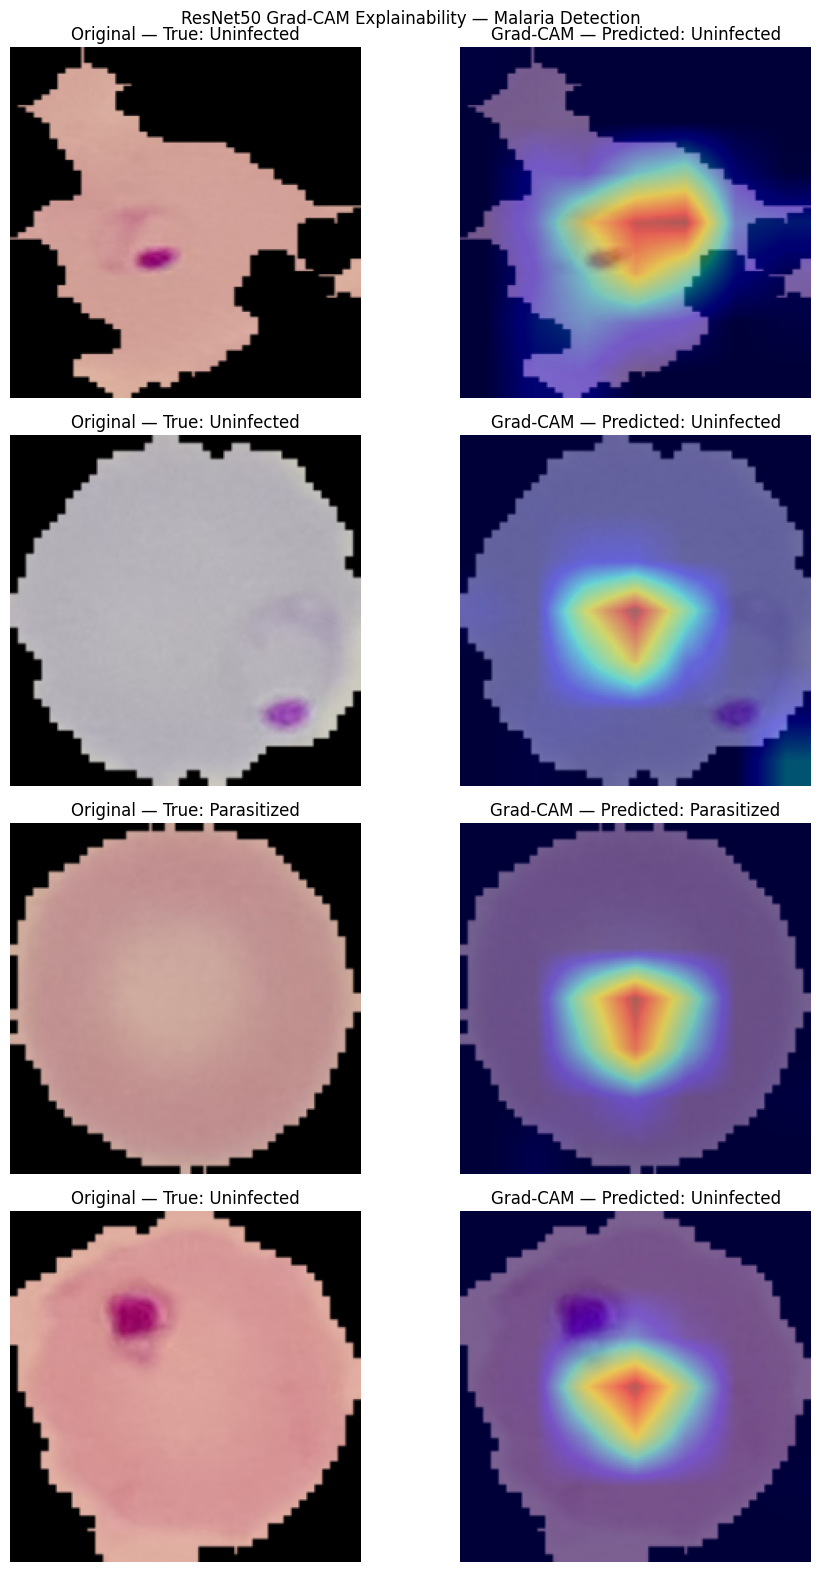

Figure saved: /kaggle/working/malaria_results/resnet50_gradcam.png


/kaggle/working/malaria_results/resnet50_gradcam.png

In [12]:

import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from IPython.display import FileLink, display

RESULTS_DIR = "/kaggle/working/malaria_results"
os.makedirs(RESULTS_DIR, exist_ok=True)

backbone = best_model.get_layer("resnet50")
last_conv = backbone.get_layer("conv5_block3_out")

grad_model = tf.keras.Model(
    inputs=backbone.input,
    outputs=[last_conv.output]
)

@tf.function
def gradcam_forward(image):
    with tf.GradientTape() as tape:
        tape.watch(image)
        conv_output = grad_model(image, training=False)
        tape.watch(conv_output)
        x = tf.keras.layers.GlobalAveragePooling2D()(conv_output)
        x = best_model.get_layer("dense")(x)
        x = best_model.get_layer("dropout")(x, training=False)
        predictions = best_model.get_layer("dense_1")(x)
        score = predictions[:, 0]
    grads = tape.gradient(score, conv_output)
    return conv_output, grads

def make_gradcam_heatmap(image):
    image_tensor = tf.convert_to_tensor(image[None, ...], dtype=tf.float32)
    conv_output, grads = gradcam_forward(image_tensor)

    weights = tf.reduce_mean(grads, axis=(1, 2))
    heatmap = tf.reduce_sum(
        conv_output * weights[:, None, None, :], axis=-1
    )[0]
    heatmap = tf.maximum(heatmap, 0)
    heatmap /= tf.reduce_max(heatmap) + 1e-8

    return heatmap.numpy()

sample_indices = list(selected[:4])
fig, axes = plt.subplots(len(sample_indices), 2, figsize=(10, 4 * len(sample_indices)))
axes = np.atleast_2d(axes)

for row, idx in enumerate(sample_indices):
    image = np.clip(X_test[idx], 0, 1)
    heatmap = make_gradcam_heatmap(image)

    axes[row, 0].imshow(image)
    axes[row, 0].set_title(f"Original — True: {class_names[y_true[idx]]}")
    axes[row, 0].axis("off")

    axes[row, 1].imshow(image)
    axes[row, 1].imshow(
        tf.image.resize(heatmap[..., None], image.shape[:2]).numpy().squeeze(),
        cmap="jet",
        alpha=0.45,
        vmin=0,
        vmax=1
    )
    axes[row, 1].set_title(f"Grad-CAM — Predicted: {class_names[y_pred[idx]]}")
    axes[row, 1].axis("off")

plt.suptitle("ResNet50 Grad-CAM Explainability — Malaria Detection")
plt.tight_layout()

gradcam_path = os.path.join(RESULTS_DIR, "resnet50_gradcam.png")
plt.savefig(gradcam_path, dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved:", gradcam_path)
display(FileLink(gradcam_path))


Step 11 — Audit the existing project files

In [14]:

from pathlib import Path
import pandas as pd

results_dir = Path("/kaggle/working/malaria_results")

if not results_dir.exists():
    print(f"Results directory not found: {results_dir}")
else:
    files = sorted(
        p for p in results_dir.rglob("*")
        if p.is_file()
    )

    audit = pd.DataFrame([
        {
            "File": str(p.relative_to(results_dir)),
            "Size_MB": round(p.stat().st_size / (1024 ** 2), 2),
            "Type": p.suffix.lower() or "no extension"
        }
        for p in files
    ])

    print(f"Total files found: {len(audit)}")
    display(audit)

    audit.to_csv(
        "/kaggle/working/malaria_project_file_audit.csv",
        index=False
    )
    print("Audit saved to /kaggle/working/malaria_project_file_audit.csv")


Total files found: 17


,File,Size_MB,Type
0,optimized_resnet50_best.keras,93.62,.keras
1,optimized_resnet50_finetuned_best.keras,203.71,.keras
2,preprocessed_samples.png,0.40,.png
3,resnet50_confusion_matrix.png,0.11,.png
4,resnet50_error_analysis.png,0.10,.png
5,resnet50_finetuning_curves.png,0.26,.png
6,resnet50_finetuning_history.csv,0.00,.csv
7,resnet50_gradcam.png,0.52,.png
8,resnet50_learning_curves.png,0.23,.png
9,resnet50_misclassified_images.csv,0.03,.csv


Audit saved to /kaggle/working/malaria_project_file_audit.csv


Step 12 — Confirm the existing ResNet50 results

In [15]:

from pathlib import Path
import pandas as pd

metrics_file = Path(
    "/kaggle/working/malaria_results/resnet50_test_metrics.csv"
)

if metrics_file.exists():
    metrics = pd.read_csv(metrics_file)
    display(metrics)
else:
    print("Test metrics file not found:", metrics_file)


,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision
0,0.858672,0.853667,0.865747,0.859665,0.941278,0.946194


Step 13 — Check the Kaggle GPU and model-training environment

In [16]:

import tensorflow as tf
import os

print("TensorFlow:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))
print("Kaggle working directory exists:",
      os.path.isdir("/kaggle/working"))
print("Dataset directory exists:",
      os.path.isdir("/kaggle/input/datasets/iarunava/cell-images-for-detecting-malaria"))


TensorFlow: 2.20.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
Kaggle working directory exists: True
Dataset directory exists: True


Step 14 — Verify the dataset split and class directories

In [17]:

from pathlib import Path

base = Path("/kaggle/input/datasets/iarunava/cell-images-for-detecting-malaria")

for class_name in ["Parasitized", "Uninfected"]:
    folder = base / "cell_images" / class_name
    print(f"{class_name}: exists={folder.is_dir()}, "
          f"images={sum(1 for p in folder.iterdir() if p.is_file()) if folder.is_dir() else 0}")

results = Path("/kaggle/working/malaria_results")
print("\nExisting split-related files:")
for p in sorted(Path("/kaggle/working").rglob("*split*")):
    if p.is_file():
        print(p)


Parasitized: exists=True, images=13780
Uninfected: exists=True, images=13780

Existing split-related files:
/kaggle/working/malaria_data_splits.csv


Step 15 — Train and evaluate VGG19

In [18]:

import os, json, numpy as np, pandas as pd, tensorflow as tf
from pathlib import Path
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, classification_report
)
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import VGG19
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

SEED = 42
tf.keras.utils.set_random_seed(SEED)

ROOT = Path("/kaggle/working")
OUT = ROOT / "malaria_results"
OUT.mkdir(parents=True, exist_ok=True)
SPLIT_FILE = ROOT / "malaria_data_splits.csv"

# Reuse the saved split; stop safely if its schema is unexpected.
if not SPLIT_FILE.exists():
    raise FileNotFoundError(f"Saved split not found: {SPLIT_FILE}")

splits = pd.read_csv(SPLIT_FILE)
print("Split columns:", splits.columns.tolist())
print("Split rows:", len(splits))
display(splits.head())

# Infer the existing split-file columns instead of silently guessing.
def find_col(candidates):
    for c in candidates:
        if c in splits.columns:
            return c
    return None

path_col = find_col(["filepath", "file_path", "path", "image_path", "filename", "file"])
split_col = find_col(["split", "subset", "set", "partition"])
label_col = find_col(["label", "class", "class_name", "category", "target"])

if not all([path_col, split_col, label_col]):
    raise ValueError(
        "Please send me the displayed split columns. "
        "No training was started, so we can map the existing CSV correctly."
    )

def normalize_split(x):
    x = str(x).strip().lower()
    if x in ["train", "training"]:
        return "train"
    if x in ["val", "valid", "validation", "validate"]:
        return "val"
    if x in ["test", "testing"]:
        return "test"
    return x

def normalize_label(x):
    x = str(x).strip().lower()
    if "parasit" in x:
        return 1
    if "uninfect" in x or x in ["0", "negative"]:
        return 0
    try:
        return int(float(x))
    except Exception:
        raise ValueError(f"Unrecognized class label: {x}")

splits["_split"] = splits[split_col].map(normalize_split)
splits["_label"] = splits[label_col].map(normalize_label)
splits["_path"] = splits[path_col].astype(str)

# Resolve relative paths against the dataset directory if needed.
DATA_ROOT = Path("/kaggle/input/datasets/iarunava/cell-images-for-detecting-malaria")
def resolve_path(p):
    q = Path(p)
    if q.is_file():
        return str(q)
    q2 = DATA_ROOT / p
    if q2.is_file():
        return str(q2)
    q3 = DATA_ROOT / "cell_images" / p
    if q3.is_file():
        return str(q3)
    return str(q)

splits["_path"] = splits["_path"].map(resolve_path)
missing = ~splits["_path"].map(lambda p: Path(p).is_file())
if missing.any():
    raise FileNotFoundError(
        f"{int(missing.sum())} image paths could not be resolved. "
        "No training started; inspect the split CSV path format."
    )

def make_dataset(frame, training=False):
    paths = frame["_path"].to_numpy()
    labels = frame["_label"].astype("float32").to_numpy()
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    def load_image(path, label):
        image = tf.io.read_file(path)
        image = tf.io.decode_image(image, channels=3, expand_animations=False)
        image.set_shape([None, None, 3])
        image = tf.image.resize(image, (224, 224))
        image = tf.cast(image, tf.float32)  # VGG19 preprocess_input expects RGB 0–255
        return image, label

    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    if training:
        ds = ds.shuffle(min(len(frame), 4096), seed=SEED,
                        reshuffle_each_iteration=True)
    return ds.batch(32).prefetch(tf.data.AUTOTUNE)

train_df = splits[splits["_split"] == "train"].copy()
val_df = splits[splits["_split"] == "val"].copy()
test_df = splits[splits["_split"] == "test"].copy()

if min(len(train_df), len(val_df), len(test_df)) == 0:
    raise ValueError(
        f"Empty split detected: train={len(train_df)}, "
        f"val={len(val_df)}, test={len(test_df)}"
    )

print(f"Images — train: {len(train_df)}, validation: {len(val_df)}, test: {len(test_df)}")
print("Training class counts:", train_df["_label"].value_counts().to_dict())

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

# VGG19 transfer learning with ImageNet weights.
augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.5),
    layers.RandomZoom(0.1),
], name="vgg19_augmentation")

backbone = VGG19(
    include_top=False, weights="imagenet", input_shape=(224, 224, 3)
)
backbone.trainable = False

inputs = layers.Input(shape=(224, 224, 3))
x = augmentation(inputs)
x = tf.keras.applications.vgg19.preprocess_input(x)
x = backbone(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)
model = Model(inputs, outputs, name="VGG19_Malaria")

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

best_path = OUT / "vgg19_best.keras"
callbacks = [
    ModelCheckpoint(str(best_path), monitor="val_loss",
                    save_best_only=True, verbose=1),
    EarlyStopping(monitor="val_loss", patience=3,
                  restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor="val_loss", factor=0.2,
                      patience=2, min_lr=1e-6, verbose=1)
]

history1 = model.fit(
    train_ds, validation_data=val_ds, epochs=10, callbacks=callbacks
)

# Fine-tune the final VGG19 convolutional block.
backbone.trainable = True
for layer in backbone.layers:
    layer.trainable = layer.name.startswith("block5_")

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

history2 = model.fit(
    train_ds, validation_data=val_ds, epochs=8, callbacks=callbacks
)

# Load the checkpoint with the best validation loss for testing.
model = tf.keras.models.load_model(best_path)
y_true = test_df["_label"].astype(int).to_numpy()
y_prob = model.predict(test_ds, verbose=1).ravel()
y_pred = (y_prob >= 0.5).astype(int)

metrics = {
    "Model": "VGG19",
    "Accuracy": accuracy_score(y_true, y_pred),
    "Precision": precision_score(y_true, y_pred, zero_division=0),
    "Recall": recall_score(y_true, y_pred, zero_division=0),
    "F1-score": f1_score(y_true, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_true, y_prob),
    "Average Precision": average_precision_score(y_true, y_prob)
}

pd.DataFrame([metrics]).to_csv(OUT / "vgg19_test_metrics.csv", index=False)
pd.DataFrame({
    "y_true": y_true, "y_probability": y_prob, "y_predicted": y_pred
}).to_csv(OUT / "vgg19_test_predictions.csv", index=False)

with open(OUT / "vgg19_classification_report.json", "w") as f:
    json.dump(
        classification_report(y_true, y_pred, output_dict=True, zero_division=0),
        f, indent=2
    )

pd.concat([
    pd.DataFrame(history1.history).assign(stage="frozen"),
    pd.DataFrame(history2.history).assign(stage="fine_tuning")
], ignore_index=True).to_csv(OUT / "vgg19_training_history.csv", index=False)

print("\nVGG19 test results:")
display(pd.DataFrame([metrics]))
print("\nSaved model:", best_path)
print("Saved metrics:", OUT / "vgg19_test_metrics.csv")


Split columns: ['filepath', 'label', 'class_name', 'split']
Split rows: 27558


,filepath,label,class_name,split
0,/kaggle/input/datasets/iarunava/cell-images-fo...,0,Uninfected,train
1,/kaggle/input/datasets/iarunava/cell-images-fo...,1,Parasitized,train
2,/kaggle/input/datasets/iarunava/cell-images-fo...,1,Parasitized,train
3,/kaggle/input/datasets/iarunava/cell-images-fo...,1,Parasitized,train
4,/kaggle/input/datasets/iarunava/cell-images-fo...,1,Parasitized,train


Images — train: 16534, validation: 5512, test: 5512
Training class counts: {0: 8267, 1: 8267}
80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/10
517/517 ━━━━━━━━━━━━━━━━━━━━ 0s 180ms/step - accuracy: 0.8223 - auc: 0.8870 - loss: 0.4709 - precision: 0.8235 - recall: 0.8224
Epoch 1: val_loss improved from None to 0.20869, saving model to /kaggle/working/malaria_results/vgg19_best.keras

Epoch 1: finished saving model to /kaggle/working/malaria_results/vgg19_best.keras
517/517 ━━━━━━━━━━━━━━━━━━━━ 137s 243ms/step - accuracy: 0.8784 - auc: 0.9426 - loss: 0.3130 - precision: 0.8831 - recall: 0.8723 - val_accuracy: 0.9209 - val_auc: 0.9774 - val_loss: 0.2087 - val_precision: 0.9567 - val_recall: 0.8817 - learning_rate: 0.0010
Epoch 2/10
517/517 ━━━━━━━━━━━━━━━━━━━━ 0s 174ms/step - accuracy: 0.9194 - auc: 0.9709 - loss: 0.2157 - precision: 0.9269 - recall: 0.9113
Epoch 2: val_loss improved from 0.20869 to 0.18768, saving model to /kaggle/working/malaria_results/vgg19_best.keras

Ep

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision
0,VGG19,0.969521,0.967486,0.971698,0.969587,0.994919,0.995547



Saved model: /kaggle/working/malaria_results/vgg19_best.keras
Saved metrics: /kaggle/working/malaria_results/vgg19_test_metrics.csv


Step 17 — Generate all VGG19 graphs

VGG19 history and prediction files loaded.
Test samples: 5512


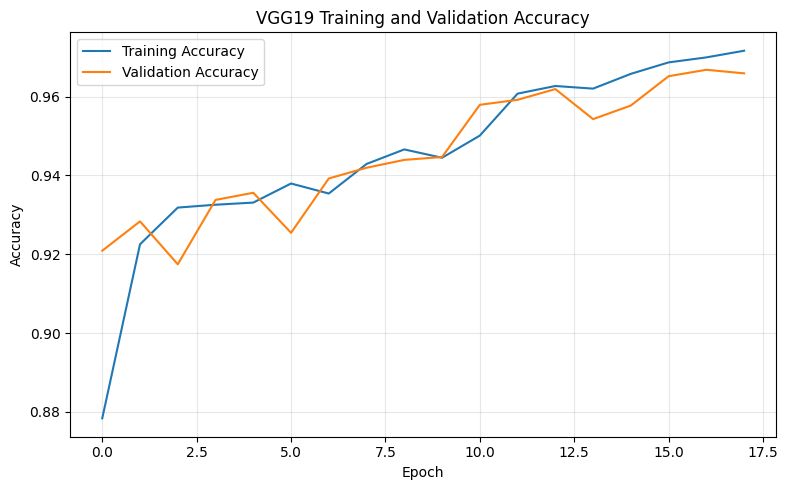

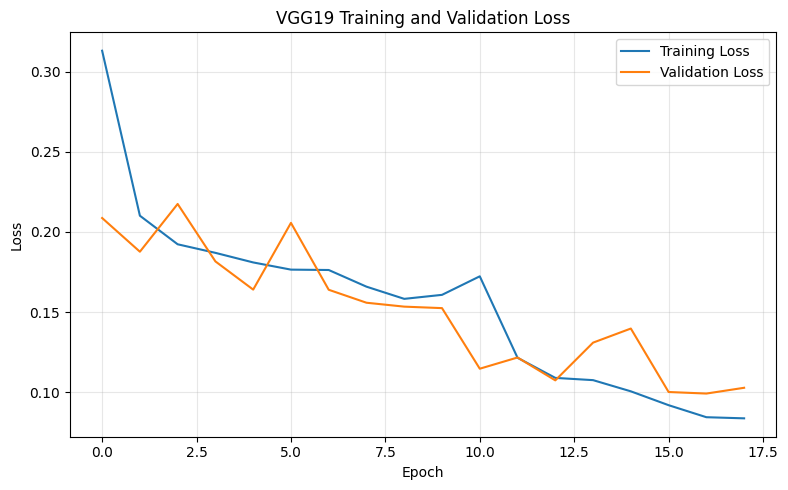

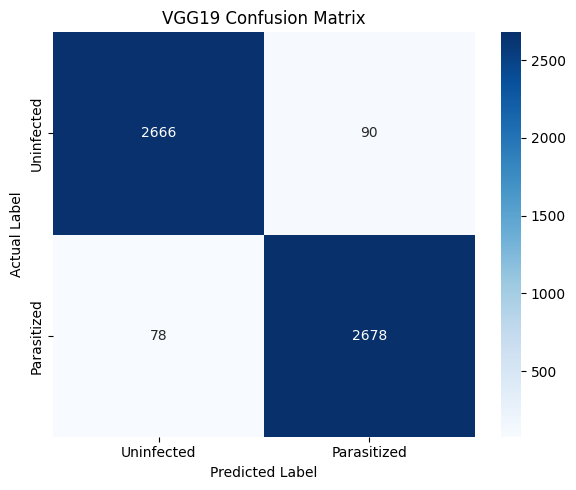

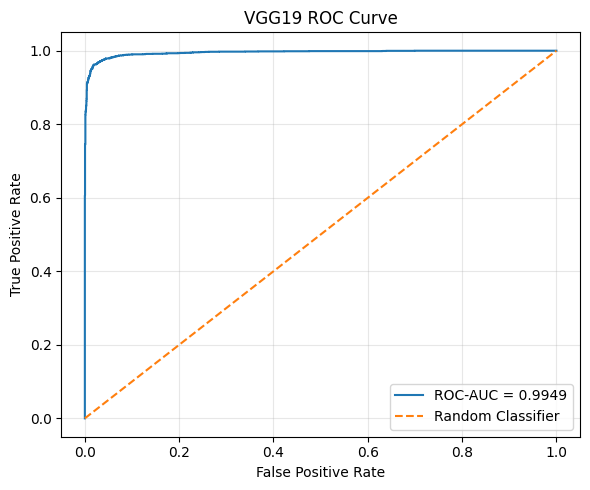

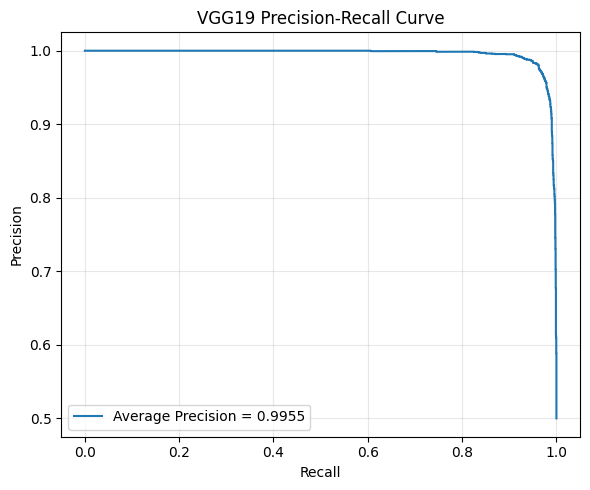

Image paths are not present in the predictions CSV. The other five graphs can still be generated.

========== VGG19 GRAPH REPORT ==========
vgg19_accuracy_curve.png | 154.4 KB
vgg19_confusion_matrix.png | 90.7 KB
vgg19_loss_curve.png | 150.8 KB
vgg19_precision_recall_curve.png | 78.7 KB
vgg19_roc_curve.png | 110.0 KB

VGG19 graph-generation cell finished.


In [21]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score
)
from tensorflow.keras.utils import load_img

# ==================================================
# STEP 1: FILE PATHS
# ==================================================
OUT = "/kaggle/working/malaria_results"

history_path = f"{OUT}/vgg19_training_history.csv"
pred_path = f"{OUT}/vgg19_test_predictions.csv"

for file_path in [history_path, pred_path]:
    if not os.path.exists(file_path):
        raise FileNotFoundError(f"Missing file: {file_path}")

history = pd.read_csv(history_path)
pred = pd.read_csv(pred_path)

print("VGG19 history and prediction files loaded.")

# ==================================================
# STEP 2: READ THE CORRECT COLUMNS
# ==================================================
# Your prediction CSV contains:
# y_true, y_probability, y_predicted

y_true = pred["y_true"].astype(int).to_numpy()
y_prob = pred["y_probability"].astype(float).to_numpy()
y_pred = pred["y_predicted"].astype(int).to_numpy()

# Use the saved predictions consistently
print("Test samples:", len(y_true))

# ==================================================
# GRAPH 1: TRAINING AND VALIDATION ACCURACY
# ==================================================
if {"accuracy", "val_accuracy"}.issubset(history.columns):
    plt.figure(figsize=(8, 5))
    plt.plot(history["accuracy"], label="Training Accuracy")
    plt.plot(history["val_accuracy"], label="Validation Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title("VGG19 Training and Validation Accuracy")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(f"{OUT}/vgg19_accuracy_curve.png", dpi=300)
    plt.show()
else:
    print("Accuracy columns missing:", history.columns.tolist())

# ==================================================
# GRAPH 2: TRAINING AND VALIDATION LOSS
# ==================================================
if {"loss", "val_loss"}.issubset(history.columns):
    plt.figure(figsize=(8, 5))
    plt.plot(history["loss"], label="Training Loss")
    plt.plot(history["val_loss"], label="Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("VGG19 Training and Validation Loss")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(f"{OUT}/vgg19_loss_curve.png", dpi=300)
    plt.show()
else:
    print("Loss columns missing:", history.columns.tolist())

# ==================================================
# GRAPH 3: CONFUSION MATRIX
# ==================================================
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Uninfected", "Parasitized"],
    yticklabels=["Uninfected", "Parasitized"]
)
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("VGG19 Confusion Matrix")
plt.tight_layout()
plt.savefig(f"{OUT}/vgg19_confusion_matrix.png", dpi=300)
plt.show()

# ==================================================
# GRAPH 4: ROC CURVE
# ==================================================
fpr, tpr, _ = roc_curve(y_true, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.4f}")
plt.plot([0, 1], [0, 1], "--", label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("VGG19 ROC Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{OUT}/vgg19_roc_curve.png", dpi=300)
plt.show()

# ==================================================
# GRAPH 5: PRECISION-RECALL CURVE
# ==================================================
precision, recall, _ = precision_recall_curve(y_true, y_prob)
ap = average_precision_score(y_true, y_prob)

plt.figure(figsize=(6, 5))
plt.plot(recall, precision, label=f"Average Precision = {ap:.4f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("VGG19 Precision-Recall Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    f"{OUT}/vgg19_precision_recall_curve.png",
    dpi=300
)
plt.show()

# ==================================================
# GRAPH 6: ACTUAL VS PREDICTED IMAGE EXAMPLES
# ==================================================
path_col = next(
    (c for c in ["filepath", "path", "image_path", "file_path"]
     if c in pred.columns),
    None
)

if path_col is not None:
    sample = pred.sample(n=min(8, len(pred)), random_state=42)

    fig, axes = plt.subplots(2, 4, figsize=(14, 7))

    for ax, (_, row) in zip(axes.flat, sample.iterrows()):
        img_path = str(row[path_col])

        if os.path.exists(img_path):
            img = load_img(img_path, target_size=(224, 224))
            ax.imshow(img)

            actual = int(row["y_true"])
            probability = float(row["y_probability"])
            predicted = int(row["y_predicted"])

            actual_name = (
                "Parasitized" if actual == 1 else "Uninfected"
            )
            predicted_name = (
                "Parasitized" if predicted == 1 else "Uninfected"
            )

            ax.set_title(
                f"Actual: {actual_name}\n"
                f"Predicted: {predicted_name}\n"
                f"Probability: {probability:.2f}",
                fontsize=8
            )
        else:
            ax.text(
                0.5, 0.5,
                "Image unavailable",
                ha="center",
                va="center"
            )

        ax.axis("off")

    plt.suptitle("VGG19 Prediction Examples")
    plt.tight_layout()
    plt.savefig(
        f"{OUT}/vgg19_prediction_examples.png",
        dpi=300
    )
    plt.show()
else:
    print(
        "Image paths are not present in the predictions CSV. "
        "The other five graphs can still be generated."
    )

# ==================================================
# STEP 3: CONFIRM SAVED FIGURES
# ==================================================
print("\n========== VGG19 GRAPH REPORT ==========")

for filename in sorted(os.listdir(OUT)):
    if filename.startswith("vgg19_") and filename.endswith(".png"):
        full_path = os.path.join(OUT, filename)
        print(f"{filename} | {os.path.getsize(full_path) / 1024:.1f} KB")

print("\nVGG19 graph-generation cell finished.")

Step 18 — Generate VGG19 prediction examples

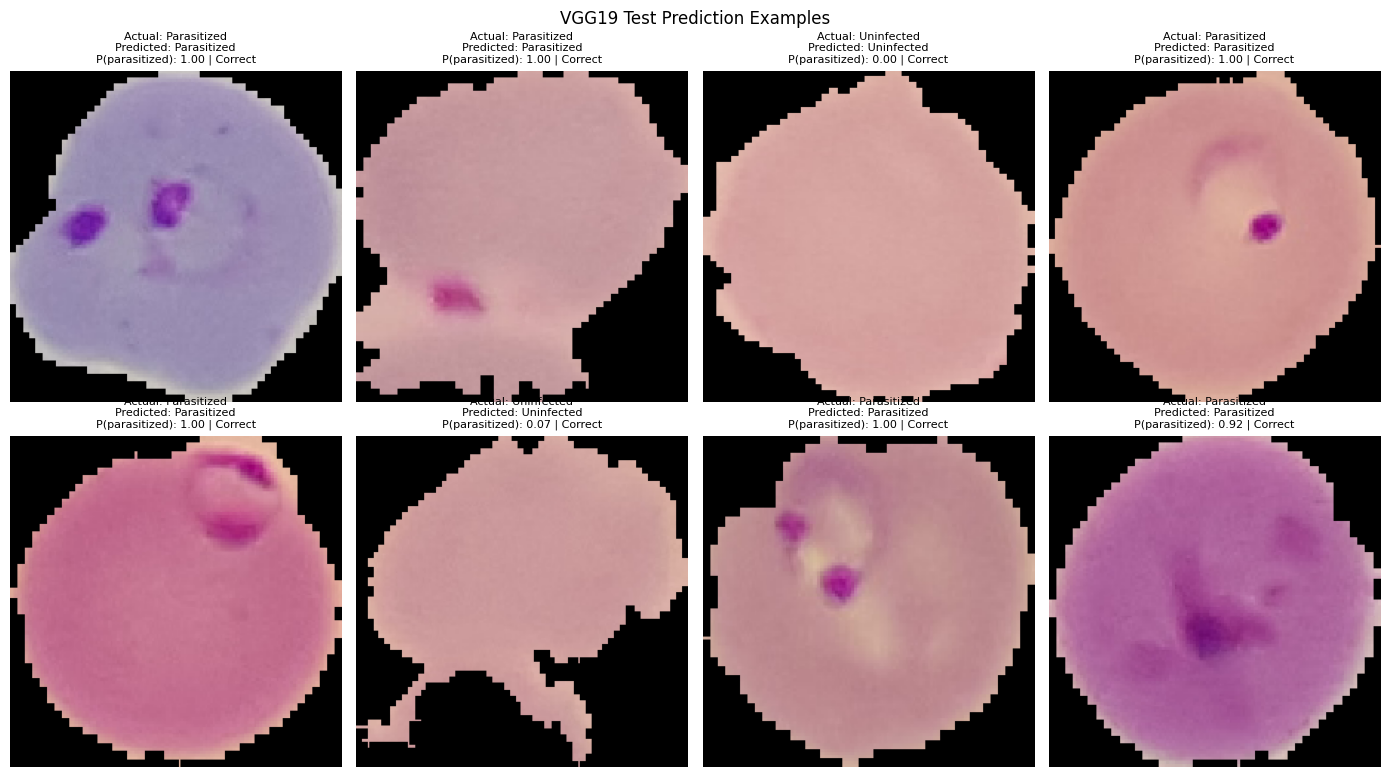

Saved: /kaggle/working/malaria_results/vgg19_prediction_examples.png


In [22]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras.utils import load_img

OUT = "/kaggle/working/malaria_results"
SPLIT_PATH = "/kaggle/working/malaria_data_splits.csv"
PRED_PATH = f"{OUT}/vgg19_test_predictions.csv"

splits = pd.read_csv(SPLIT_PATH)
pred = pd.read_csv(PRED_PATH)

# Get test image paths in the same order used by the test dataset
test_paths = splits.loc[splits["split"] == "test", "filepath"].tolist()

if len(test_paths) != len(pred):
    raise ValueError(
        f"Test path count ({len(test_paths)}) does not match "
        f"prediction count ({len(pred)}). Cannot safely match images."
    )

# Prediction CSV contains y_true, y_probability, y_predicted
sample_indices = (
    pd.Series(range(len(pred)))
    .sample(n=min(8, len(pred)), random_state=42)
    .tolist()
)

fig, axes = plt.subplots(2, 4, figsize=(14, 8))

for ax, idx in zip(axes.flat, sample_indices):
    path = test_paths[idx]

    if os.path.exists(path):
        ax.imshow(load_img(path, target_size=(224, 224)))

        actual = int(pred.iloc[idx]["y_true"])
        probability = float(pred.iloc[idx]["y_probability"])
        predicted = int(pred.iloc[idx]["y_predicted"])

        actual_name = "Parasitized" if actual == 1 else "Uninfected"
        predicted_name = "Parasitized" if predicted == 1 else "Uninfected"
        result = "Correct" if actual == predicted else "Incorrect"

        ax.set_title(
            f"Actual: {actual_name}\n"
            f"Predicted: {predicted_name}\n"
            f"P(parasitized): {probability:.2f} | {result}",
            fontsize=8
        )
    else:
        ax.text(0.5, 0.5, "Image not found", ha="center", va="center")

    ax.axis("off")

plt.suptitle("VGG19 Test Prediction Examples")
plt.tight_layout()
plt.savefig(f"{OUT}/vgg19_prediction_examples.png", dpi=300)
plt.show()

print("Saved:", f"{OUT}/vgg19_prediction_examples.png")

Step 19 — DenseNet201 training and evaluation

In [25]:

import os
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import DenseNet201
from tensorflow.keras.applications.densenet import preprocess_input
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score
)

# ---------------- CONFIGURATION ----------------
SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
OUT = "/kaggle/working/malaria_results"
SPLIT_PATH = "/kaggle/working/malaria_data_splits.csv"

os.makedirs(OUT, exist_ok=True)
tf.keras.utils.set_random_seed(SEED)

# ---------------- LOAD SPLITS ------------------
splits = pd.read_csv(SPLIT_PATH)

train_df = splits[splits["split"] == "train"].copy()
val_df = splits[splits["split"] == "validation"].copy()
test_df = splits[splits["split"] == "test"].copy()

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

assert len(train_df) > 0 and len(val_df) > 0 and len(test_df) > 0
assert splits["filepath"].apply(os.path.exists).all(), \
    "Some image paths do not exist."

# ---------------- DATA PIPELINE ----------------
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_image(
        image, channels=3, expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)
    return image, tf.cast(label, tf.float32)

def make_dataset(df, training=False):
    ds = tf.data.Dataset.from_tensor_slices((
        df["filepath"].astype(str).values,
        df["label"].astype(np.float32).values
    ))

    if training:
        ds = ds.shuffle(
            min(len(df), 5000),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    return (
        ds.map(load_image, num_parallel_calls=AUTOTUNE)
          .batch(BATCH_SIZE)
          .prefetch(AUTOTUNE)
    )

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

# ---------------- AUGMENTATION -----------------
augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.10)
], name="densenet_augmentation")

# ---------------- BUILD MODEL ------------------
backbone = DenseNet201(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)
backbone.trainable = False

inputs = keras.Input(shape=(224, 224, 3))
x = augmentation(inputs)
x = layers.Lambda(preprocess_input)(x)
x = backbone(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

model = keras.Model(inputs, outputs, name="DenseNet201_Malaria")

def compile_model(lr):
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss="binary_crossentropy",
        metrics=[
            "accuracy",
            keras.metrics.AUC(name="auc")
        ]
    )

compile_model(1e-3)
model.summary()

# ---------------- CALLBACKS --------------------
BEST_PATH = f"{OUT}/densenet201_best.keras"

callbacks = [
    keras.callbacks.ModelCheckpoint(
        BEST_PATH, monitor="val_loss",
        save_best_only=True, verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=3,
        restore_best_weights=True, verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.2,
        patience=2, min_lr=1e-7, verbose=1
    )
]

# ---------------- PHASE 1: FROZEN BACKBONE ------
print("\nPHASE 1: Training classification head")

h1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks,
    verbose=1
)

# ---------------- PHASE 2: FINE-TUNING ----------
print("\nPHASE 2: Fine-tuning final DenseNet block")

backbone.trainable = True

# Keep Batch Normalization frozen; fine-tune final dense block
for layer in backbone.layers:
    layer.trainable = (
        layer.name.startswith("conv5")
        and not isinstance(layer, layers.BatchNormalization)
    )

compile_model(1e-5)

h2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    callbacks=callbacks,
    verbose=1
)

# Save combined training history
history1 = pd.DataFrame(h1.history)
history1["phase"] = "frozen"

history2 = pd.DataFrame(h2.history)
history2["phase"] = "fine_tuning"

pd.concat([history1, history2], ignore_index=True).to_csv(
    f"{OUT}/densenet201_training_history.csv", index=False
)

# ---------------- LOAD BEST CHECKPOINT ----------
model = keras.models.load_model(BEST_PATH)

# ---------------- TEST EVALUATION ----------------
print("\nEvaluating DenseNet201 on test set")

y_true = test_df["label"].astype(int).to_numpy()
y_prob = model.predict(test_ds, verbose=1).ravel()
y_pred = (y_prob >= 0.5).astype(int)

assert len(y_true) == len(y_prob), \
    "Prediction count does not match test labels."

metrics = {
    "model": "DenseNet201",
    "accuracy": accuracy_score(y_true, y_pred),
    "precision": precision_score(y_true, y_pred, zero_division=0),
    "recall": recall_score(y_true, y_pred, zero_division=0),
    "f1_score": f1_score(y_true, y_pred, zero_division=0),
    "roc_auc": roc_auc_score(y_true, y_prob),
    "average_precision": average_precision_score(y_true, y_prob)
}

pd.DataFrame([metrics]).to_csv(
    f"{OUT}/densenet201_test_metrics.csv", index=False
)

pd.DataFrame({
    "y_true": y_true,
    "y_probability": y_prob,
    "y_predicted": y_pred
}).to_csv(
    f"{OUT}/densenet201_test_predictions.csv", index=False
)

print("\nDENSENET201 TEST RESULTS")
for key, value in metrics.items():
    print(f"{key}: {value:.4f}" if isinstance(value, (float, np.floating))
          else f"{key}: {value}")

print("\nSaved model:", BEST_PATH)
print("Saved metrics and predictions in:", OUT)
print("DenseNet201 training and evaluation completed!")


Train: 16534
Validation: 5512
Test: 5512
74836368/74836368 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "DenseNet201_Malaria"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet_augmentation           │ (None, 224, 224, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet201 (Functional)        │ (None, 7, 7, 1920)     │    18,321,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 1920)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       245,888 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,568,001 (70.83 MB)

 Trainable params: 246,017 (961.00 KB)

 Non-trainable params: 18,321,984 (69.89 MB)


PHASE 1: Training classification head
Epoch 1/10
517/517 ━━━━━━━━━━━━━━━━━━━━ 0s 231ms/step - accuracy: 0.8686 - auc: 0.9319 - loss: 0.3150
Epoch 1: val_loss improved from None to 0.19494, saving model to /kaggle/working/malaria_results/densenet201_best.keras

Epoch 1: finished saving model to /kaggle/working/malaria_results/densenet201_best.keras
517/517 ━━━━━━━━━━━━━━━━━━━━ 197s 332ms/step - accuracy: 0.9066 - auc: 0.9641 - loss: 0.2423 - val_accuracy: 0.9202 - val_auc: 0.9804 - val_loss: 0.1949 - learning_rate: 0.0010
Epoch 2/10
517/517 ━━━━━━━━━━━━━━━━━━━━ 0s 227ms/step - accuracy: 0.9281 - auc: 0.9755 - loss: 0.1967
Epoch 2: val_loss improved from 0.19494 to 0.18099, saving model to /kaggle/working/malaria_results/densenet201_best.keras

Epoch 2: finished saving model to /kaggle/working/malaria_results/densenet201_best.keras
517/517 ━━━━━━━━━━━━━━━━━━━━ 158s 305ms/step - accuracy: 0.9295 - auc: 0.9771 - loss: 0.1900 - val_accuracy: 0.9274 - val_auc: 0.9821 - val_loss: 0.1810 - le

TypeError: <class 'keras.src.models.functional.Functional'> could not be deserialized properly. Please ensure that components that are Python object instances (layers, models, etc.) returned by `get_config()` are explicitly deserialized in the model's `from_config()` method.

config={'module': 'keras.src.models.functional', 'class_name': 'Functional', 'config': {}, 'registered_name': 'Functional', 'build_config': {'input_shape': None}, 'compile_config': {'optimizer': {'module': 'keras.optimizers', 'class_name': 'Adam', 'config': {'name': 'adam', 'learning_rate': 1.9999999949504854e-06, 'weight_decay': None, 'clipnorm': None, 'global_clipnorm': None, 'clipvalue': None, 'use_ema': False, 'ema_momentum': 0.99, 'ema_overwrite_frequency': None, 'loss_scale_factor': None, 'gradient_accumulation_steps': None, 'beta_1': 0.9, 'beta_2': 0.999, 'epsilon': 1e-07, 'amsgrad': False}, 'registered_name': None}, 'loss': 'binary_crossentropy', 'loss_weights': None, 'metrics': ['accuracy', {'module': 'ke

Step 19.1 — Load the saved DenseNet201 model

In [26]:
# STEP 19.1 — Load Saved DenseNet201 Model

import os
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.applications.densenet import preprocess_input

MODEL_PATH = "/kaggle/working/malaria_results/densenet201_best.keras"

assert os.path.exists(MODEL_PATH), f"Model not found: {MODEL_PATH}"

model = keras.models.load_model(
    MODEL_PATH,
    custom_objects={"preprocess_input": preprocess_input},
    compile=False
)

print("DenseNet201 loaded successfully!")
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)

DenseNet201 loaded successfully!
Input shape: (None, 224, 224, 3)
Output shape: (None, 1)


Step 19.2 — Prepare the test dataset

In [27]:
# STEP 19.2 — Prepare DenseNet201 Test Dataset

import os
import pandas as pd
import tensorflow as tf

SPLIT_PATH = "/kaggle/working/malaria_data_splits.csv"
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

splits = pd.read_csv(SPLIT_PATH)

test_df = splits[splits["split"] == "test"].copy().reset_index(drop=True)

assert len(test_df) > 0, "Test dataset is empty!"
assert test_df["filepath"].apply(os.path.exists).all(), \
    "Some test image paths are missing!"

def load_test_image(filepath, label):
    image = tf.io.read_file(filepath)
    image = tf.io.decode_image(
        image, channels=3, expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)
    return image, tf.cast(label, tf.float32)

test_ds = tf.data.Dataset.from_tensor_slices((
    test_df["filepath"].values,
    test_df["label"].values
))

test_ds = (
    test_ds
    .map(load_test_image, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

print("Test dataset prepared successfully!")
print("Test images:", len(test_df))
print("\nClass distribution:")
print(test_df["class_name"].value_counts())
print("\nBatches:", tf.data.experimental.cardinality(test_ds).numpy())

Test dataset prepared successfully!
Test images: 5512

Class distribution:
class_name
Uninfected     2756
Parasitized    2756
Name: count, dtype: int64

Batches: 173


Step 19.3 — Generate DenseNet201 predictions

In [28]:
# STEP 19.3 — Generate DenseNet201 Test Predictions

import numpy as np

y_true = test_df["label"].to_numpy(dtype=np.int32)

# Predict probabilities for the test images
y_probability = model.predict(test_ds, verbose=1).ravel()

# Convert probabilities to binary predictions
y_predicted = (y_probability >= 0.5).astype(np.int32)

# Verify prediction counts and shapes
assert len(y_true) == len(y_probability) == len(y_predicted), \
    "Prediction count mismatch!"

print("\nDenseNet201 predictions generated successfully!")
print("Test samples:", len(y_true))
print("Probability range:",
      round(float(y_probability.min()), 4),
      "to",
      round(float(y_probability.max()), 4))
print("Predicted Uninfected:", int(np.sum(y_predicted == 0)))
print("Predicted Parasitized:", int(np.sum(y_predicted == 1)))

173/173 ━━━━━━━━━━━━━━━━━━━━ 52s 258ms/step

DenseNet201 predictions generated successfully!
Test samples: 5512
Probability range: 0.0 to 1.0
Predicted Uninfected: 2774
Predicted Parasitized: 2738


Step 19.4 — Calculate and save test metrics

In [29]:
# STEP 19.4 — Calculate and Save DenseNet201 Test Metrics

import os
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

RESULTS_DIR = "/kaggle/working/malaria_results"
os.makedirs(RESULTS_DIR, exist_ok=True)

metrics = {
    "model": "DenseNet201",
    "accuracy": accuracy_score(y_true, y_predicted),
    "precision": precision_score(y_true, y_predicted, zero_division=0),
    "recall": recall_score(y_true, y_predicted, zero_division=0),
    "f1_score": f1_score(y_true, y_predicted, zero_division=0),
    "roc_auc": roc_auc_score(y_true, y_probability),
    "average_precision": average_precision_score(y_true, y_probability),
    "test_samples": len(y_true)
}

metrics_df = pd.DataFrame([metrics])
metrics_path = os.path.join(
    RESULTS_DIR, "densenet201_test_metrics.csv"
)
metrics_df.to_csv(metrics_path, index=False)

predictions_df = pd.DataFrame({
    "y_true": y_true,
    "y_probability": y_probability,
    "y_predicted": y_predicted
})

predictions_path = os.path.join(
    RESULTS_DIR, "densenet201_test_predictions.csv"
)
predictions_df.to_csv(predictions_path, index=False)

print("DENSENET201 TEST METRICS")
for key, value in metrics.items():
    if isinstance(value, float):
        print(f"{key}: {value:.4f}")
    else:
        print(f"{key}: {value}")

print("\nConfusion matrix:")
print(confusion_matrix(y_true, y_predicted))

print("\nSaved metrics:", metrics_path)
print("Saved predictions:", predictions_path)

DENSENET201 TEST METRICS
model: DenseNet201
accuracy: 0.9644
precision: 0.9675
recall: 0.9612
f1_score: 0.9643
roc_auc: 0.9934
average_precision: 0.9940
test_samples: 5512

Confusion matrix:
[[2667   89]
 [ 107 2649]]

Saved metrics: /kaggle/working/malaria_results/densenet201_test_metrics.csv
Saved predictions: /kaggle/working/malaria_results/densenet201_test_predictions.csv


Step 19.5 — Save DenseNet201 training history

In [32]:
# STEP 19.5 — Inspect and Save DenseNet201 Training History

import os
import pandas as pd

RESULTS_DIR = "/kaggle/working/malaria_results"
os.makedirs(RESULTS_DIR, exist_ok=True)

print("Type of history:", type(history).__name__)

if isinstance(history, pd.DataFrame):
    phase1_df = history.copy()

elif hasattr(history, "history") and isinstance(history.history, dict):
    phase1_df = pd.DataFrame(history.history)

else:
    raise TypeError(
        "The history variable is not a recognized training-history object."
    )

phase1_path = os.path.join(
    RESULTS_DIR, "densenet201_phase1_history.csv"
)
phase1_df.to_csv(phase1_path, index=False)

print("\nAvailable history saved successfully!")
print("Rows:", len(phase1_df))
print("Columns:", phase1_df.columns.tolist())
print("Saved to:", phase1_path)

Type of history: DataFrame

Available history saved successfully!
Rows: 18
Columns: ['accuracy', 'auc', 'loss', 'precision', 'recall', 'val_accuracy', 'val_auc', 'val_loss', 'val_precision', 'val_recall', 'learning_rate', 'stage']
Saved to: /kaggle/working/malaria_results/densenet201_phase1_history.csv


Step 19.6 — Check DenseNet201 training history

In [33]:
# STEP 19.6 — Verify DenseNet201 Training History

import pandas as pd

history_path = (
    "/kaggle/working/malaria_results/"
    "densenet201_phase1_history.csv"
)

history_df = pd.read_csv(history_path)

print("Total epochs:", len(history_df))
print("\nEpochs by stage:")
print(history_df["stage"].value_counts(dropna=False))

print("\nHistory preview:")
display(history_df[["stage", "accuracy", "val_accuracy",
                     "loss", "val_loss"]])

Total epochs: 18

Epochs by stage:
stage
frozen         10
fine_tuning     8
Name: count, dtype: int64

History preview:


,stage,accuracy,val_accuracy,loss,val_loss
0,frozen,0.878372,0.920900,0.313021,0.208691
1,frozen,0.922523,0.928338,0.210130,0.187680
2,frozen,0.931837,0.917453,0.192307,0.217451
3,frozen,0.932563,0.933781,0.186965,0.181626
4,frozen,0.933108,0.935595,0.180992,0.164040
5,frozen,0.937946,0.925435,0.176504,0.205664
6,frozen,0.935406,0.939224,0.176271,0.163945
7,frozen,0.942906,0.941945,0.165876,0.155861
8,frozen,0.946595,0.943941,0.158276,0.153422
9,frozen,0.944478,0.944666,0.160773,0.152495


Step 19.7 — Plot DenseNet201 accuracy curves

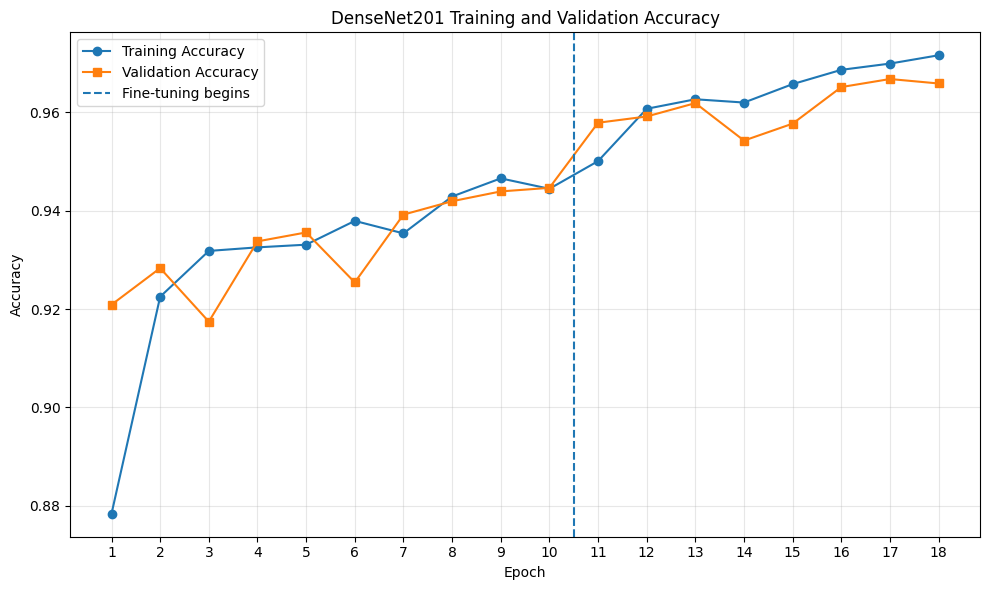

Accuracy curve saved to: /kaggle/working/malaria_results/densenet201_accuracy_curve.png


In [34]:
# STEP 19.7 — DenseNet201 Accuracy Curve

import os
import pandas as pd
import matplotlib.pyplot as plt

RESULTS_DIR = "/kaggle/working/malaria_results"
history_path = os.path.join(
    RESULTS_DIR, "densenet201_phase1_history.csv"
)

history_df = pd.read_csv(history_path)

epochs = range(1, len(history_df) + 1)

plt.figure(figsize=(10, 6))

plt.plot(
    epochs, history_df["accuracy"],
    marker="o", label="Training Accuracy"
)
plt.plot(
    epochs, history_df["val_accuracy"],
    marker="s", label="Validation Accuracy"
)

plt.axvline(
    x=10.5, linestyle="--",
    label="Fine-tuning begins"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("DenseNet201 Training and Validation Accuracy")
plt.xticks(range(1, len(history_df) + 1, 1))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

save_path = os.path.join(
    RESULTS_DIR, "densenet201_accuracy_curve.png"
)
plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print("Accuracy curve saved to:", save_path)

Step 19.8 — Plot DenseNet201 loss curves

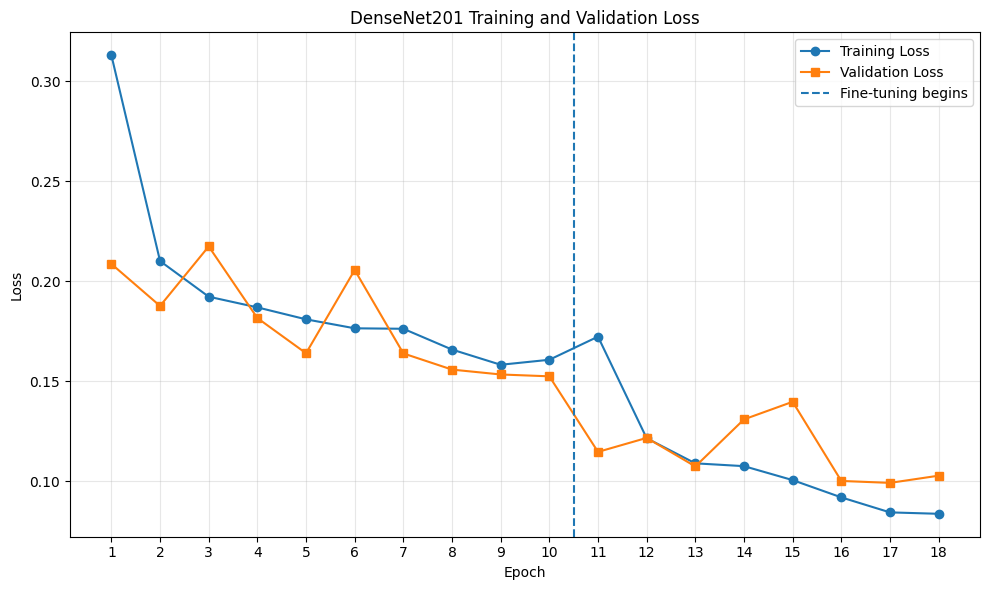

Loss curve saved to: /kaggle/working/malaria_results/densenet201_loss_curve.png


In [35]:
# STEP 19.8 — DenseNet201 Loss Curve

import os
import pandas as pd
import matplotlib.pyplot as plt

RESULTS_DIR = "/kaggle/working/malaria_results"

history_df = pd.read_csv(
    os.path.join(RESULTS_DIR, "densenet201_phase1_history.csv")
)

epochs = range(1, len(history_df) + 1)

plt.figure(figsize=(10, 6))

plt.plot(
    epochs, history_df["loss"],
    marker="o", label="Training Loss"
)
plt.plot(
    epochs, history_df["val_loss"],
    marker="s", label="Validation Loss"
)

plt.axvline(
    x=10.5,
    linestyle="--",
    label="Fine-tuning begins"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("DenseNet201 Training and Validation Loss")
plt.xticks(range(1, len(history_df) + 1))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

save_path = os.path.join(
    RESULTS_DIR, "densenet201_loss_curve.png"
)

plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print("Loss curve saved to:", save_path)

Step 19.9 — Generate DenseNet201 confusion matrix

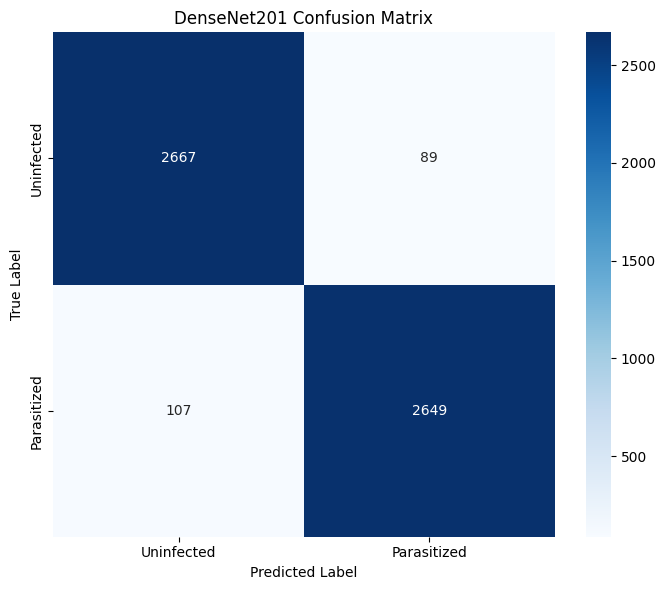

Confusion matrix:
[[2667   89]
 [ 107 2649]]
Saved to: /kaggle/working/malaria_results/densenet201_confusion_matrix.png


In [36]:
# STEP 19.9 — DenseNet201 Confusion Matrix

import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

RESULTS_DIR = "/kaggle/working/malaria_results"

# Use existing test labels and predictions
cm = confusion_matrix(
    y_true,
    y_predicted,
    labels=[0, 1]
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Uninfected", "Parasitized"],
    yticklabels=["Uninfected", "Parasitized"]
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("DenseNet201 Confusion Matrix")
plt.tight_layout()

save_path = os.path.join(
    RESULTS_DIR, "densenet201_confusion_matrix.png"
)

plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print("Confusion matrix:")
print(cm)
print("Saved to:", save_path)

Step 19.10 — Generate DenseNet201 ROC curve

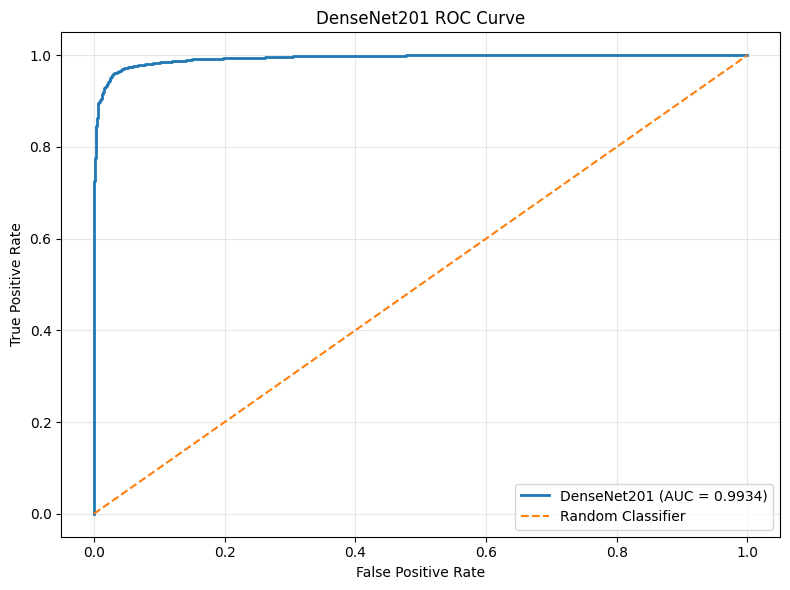

ROC-AUC: 0.993365
Saved to: /kaggle/working/malaria_results/densenet201_roc_curve.png


In [37]:
# STEP 19.10 — DenseNet201 ROC Curve

import os
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

RESULTS_DIR = "/kaggle/working/malaria_results"

fpr, tpr, thresholds = roc_curve(
    y_true,
    y_probability
)

roc_auc = roc_auc_score(
    y_true,
    y_probability
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"DenseNet201 (AUC = {roc_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("DenseNet201 ROC Curve")
plt.grid(True, alpha=0.3)
plt.legend(loc="lower right")
plt.tight_layout()

save_path = os.path.join(
    RESULTS_DIR, "densenet201_roc_curve.png"
)

plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"ROC-AUC: {roc_auc:.6f}")
print("Saved to:", save_path)

Step 19.11 — Generate DenseNet201 Precision–Recall curve

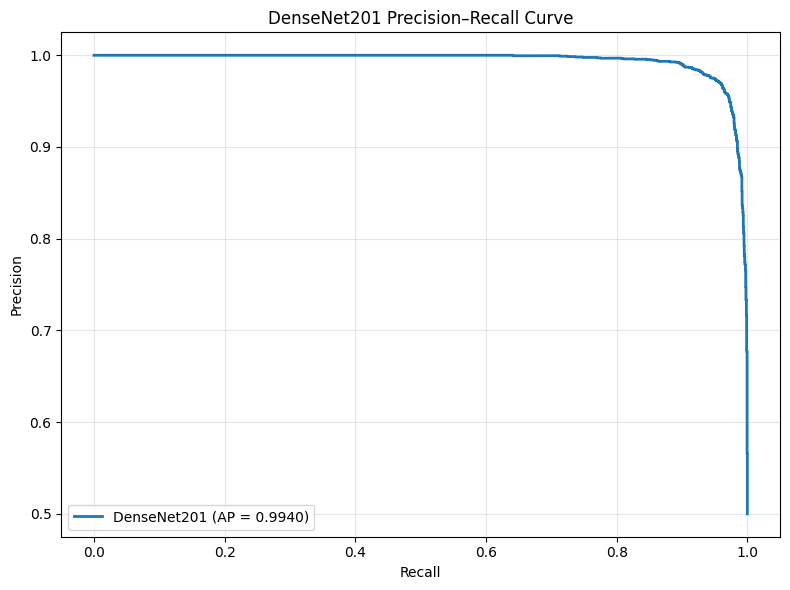

Average Precision (AP): 0.993984
Saved to: /kaggle/working/malaria_results/densenet201_precision_recall_curve.png


In [38]:
# STEP 19.11 — DenseNet201 Precision–Recall Curve

import os
import matplotlib.pyplot as plt
from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

RESULTS_DIR = "/kaggle/working/malaria_results"

precision, recall, thresholds = precision_recall_curve(
    y_true,
    y_probability
)

average_precision = average_precision_score(
    y_true,
    y_probability
)

plt.figure(figsize=(8, 6))

plt.plot(
    recall,
    precision,
    linewidth=2,
    label=f"DenseNet201 (AP = {average_precision:.4f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("DenseNet201 Precision–Recall Curve")
plt.grid(True, alpha=0.3)
plt.legend(loc="lower left")
plt.tight_layout()

save_path = os.path.join(
    RESULTS_DIR, "densenet201_precision_recall_curve.png"
)

plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Average Precision (AP): {average_precision:.6f}")
print("Saved to:", save_path)

Step 19.12 — Generate DenseNet201 prediction examples

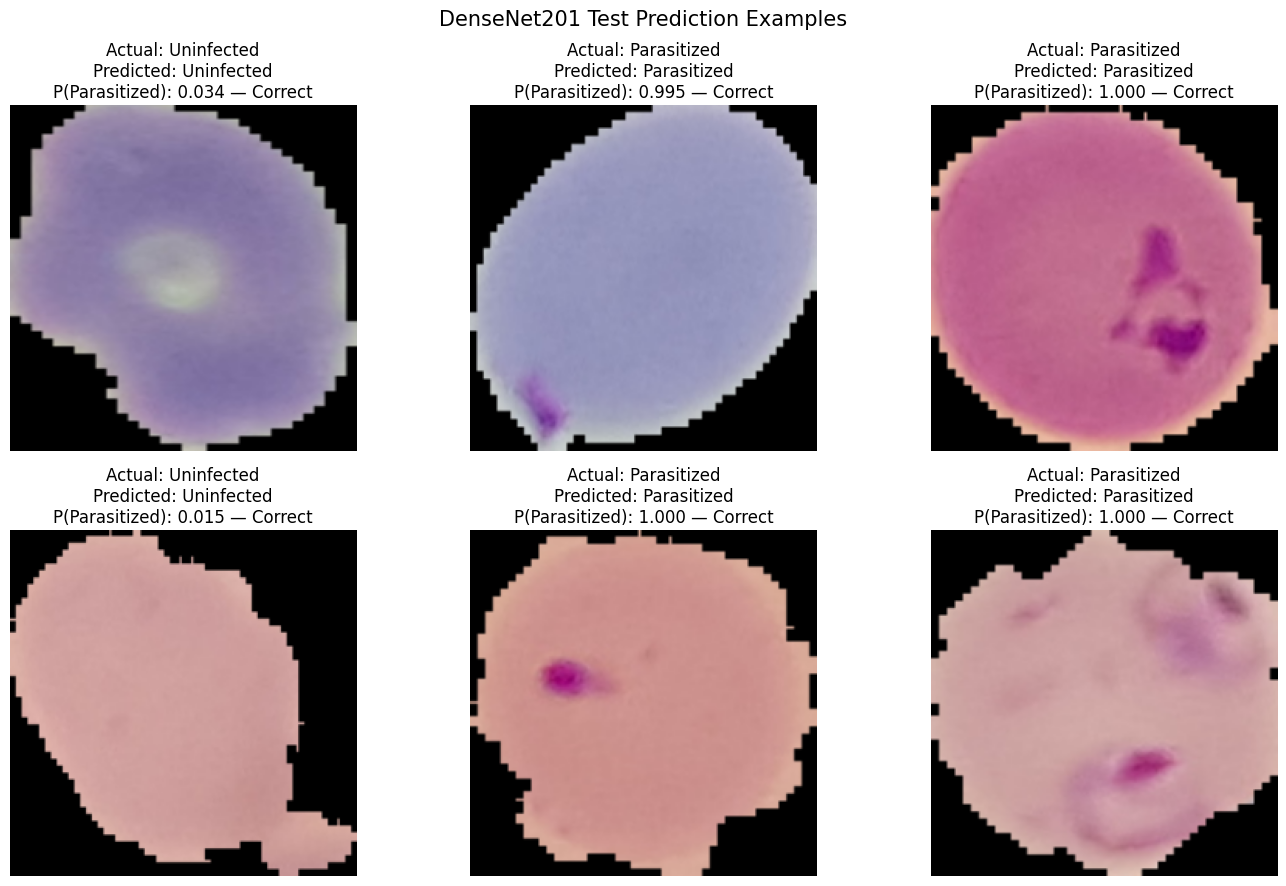

Prediction examples saved to: /kaggle/working/malaria_results/densenet201_prediction_examples.png


In [39]:
# STEP 19.12 — DenseNet201 Prediction Examples

import os
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

RESULTS_DIR = "/kaggle/working/malaria_results"
IMG_SIZE = (224, 224)

# Select six examples reproducibly
rng = np.random.default_rng(42)
sample_indices = rng.choice(
    len(test_df), size=6, replace=False
)

fig, axes = plt.subplots(2, 3, figsize=(14, 9))
axes = axes.flatten()

class_names = {
    0: "Uninfected",
    1: "Parasitized"
}

for ax, idx in zip(axes, sample_indices):
    filepath = test_df.iloc[idx]["filepath"]

    image = tf.io.read_file(filepath)
    image = tf.io.decode_image(
        image, channels=3, expand_animations=False
    )
    image = tf.image.resize(image, IMG_SIZE).numpy().astype("uint8")

    actual = int(y_true[idx])
    predicted = int(y_predicted[idx])
    confidence = float(y_probability[idx])

    correct = actual == predicted
    status = "Correct" if correct else "Incorrect"

    ax.imshow(image)
    ax.set_title(
        f"Actual: {class_names[actual]}\n"
        f"Predicted: {class_names[predicted]}\n"
        f"P(Parasitized): {confidence:.3f} — {status}"
    )
    ax.axis("off")

plt.suptitle("DenseNet201 Test Prediction Examples", fontsize=15)
plt.tight_layout()

save_path = os.path.join(
    RESULTS_DIR, "densenet201_prediction_examples.png"
)

plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print("Prediction examples saved to:", save_path)

Step 19.13 — Verify DenseNet201 results

In [40]:
# STEP 19.13 — Verify DenseNet201 Artifacts

import os
import pandas as pd

RESULTS_DIR = "/kaggle/working/malaria_results"

required_files = [
    "densenet201_best.keras",
    "densenet201_phase1_history.csv",
    "densenet201_test_metrics.csv",
    "densenet201_test_predictions.csv",
    "densenet201_accuracy_curve.png",
    "densenet201_loss_curve.png",
    "densenet201_confusion_matrix.png",
    "densenet201_roc_curve.png",
    "densenet201_precision_recall_curve.png",
    "densenet201_prediction_examples.png",
]

print("DENSENET201 FILE VERIFICATION")
print("=" * 45)

for filename in required_files:
    path = os.path.join(RESULTS_DIR, filename)
    if os.path.isfile(path):
        size_mb = os.path.getsize(path) / (1024 * 1024)
        print(f"OK   {filename} ({size_mb:.2f} MB)")
    else:
        print(f"MISSING   {filename}")

metrics_path = os.path.join(
    RESULTS_DIR, "densenet201_test_metrics.csv"
)

if os.path.isfile(metrics_path):
    print("\nTEST METRICS")
    display(pd.read_csv(metrics_path))

print("\nVerification finished.")

DENSENET201 FILE VERIFICATION
OK   densenet201_best.keras (127.65 MB)
OK   densenet201_phase1_history.csv (0.00 MB)
OK   densenet201_test_metrics.csv (0.00 MB)
OK   densenet201_test_predictions.csv (0.08 MB)
OK   densenet201_accuracy_curve.png (0.19 MB)
OK   densenet201_loss_curve.png (0.19 MB)
OK   densenet201_confusion_matrix.png (0.09 MB)
OK   densenet201_roc_curve.png (0.13 MB)
OK   densenet201_precision_recall_curve.png (0.09 MB)
OK   densenet201_prediction_examples.png (0.46 MB)

TEST METRICS


,model,accuracy,precision,recall,f1_score,roc_auc,average_precision,test_samples
0,DenseNet201,0.964441,0.967495,0.961176,0.964325,0.993365,0.993984,5512



Verification finished.


Step 20.1 — Inspect Existing MobileNetV2 Artifacts and Notebook State

In [41]:
# STEP 20.1 — Inspect Existing MobileNetV2 Artifacts

import os
import glob

RESULTS_DIR = "/kaggle/working/malaria_results"

print("=" * 65)
print("MOBILENETV2 — EXISTING FILES")
print("=" * 65)

all_files = sorted(os.listdir(RESULTS_DIR))

mobile_files = [
    f for f in all_files
    if "mobilenet" in f.lower() or "mobile_net" in f.lower()
]

if mobile_files:
    for filename in mobile_files:
        path = os.path.join(RESULTS_DIR, filename)
        size_mb = os.path.getsize(path) / (1024 * 1024)
        print(f"{filename}  |  {size_mb:.2f} MB")
else:
    print("No MobileNetV2-specific files found.")

print("\n" + "=" * 65)
print("OTHER RELEVANT PROJECT FILES")
print("=" * 65)

for pattern in [
    "*split*.csv",
    "*metrics*.csv",
    "*history*.csv",
    "*mobilenet*.keras",
    "*mobilenet*.h5"
]:
    matches = glob.glob(os.path.join(RESULTS_DIR, pattern))
    for path in sorted(matches):
        print(os.path.basename(path))

print("\n" + "=" * 65)
print("NOTEBOOK STATE — RELEVANT VARIABLES")
print("=" * 65)

for name in [
    "model", "history", "fine_tune_history",
    "train_ds", "val_ds", "test_ds",
    "train_df", "val_df", "test_df",
    "y_true", "y_probability", "y_predicted",
    "splits", "SPLIT_PATH"
]:
    if name in globals():
        obj = globals()[name]
        print(f"{name}: {type(obj).__name__}")
    else:
        print(f"{name}: not currently defined")

print("\nInspection complete. No training was started.")

MOBILENETV2 — EXISTING FILES
No MobileNetV2-specific files found.

OTHER RELEVANT PROJECT FILES
densenet201_test_metrics.csv
resnet50_test_metrics.csv
vgg19_test_metrics.csv
densenet201_phase1_history.csv
densenet201_training_history.csv
resnet50_finetuning_history.csv
resnet50_training_history.csv
vgg19_training_history.csv

NOTEBOOK STATE — RELEVANT VARIABLES
model: Functional
history: DataFrame
fine_tune_history: not currently defined
train_ds: _PrefetchDataset
val_ds: _PrefetchDataset
test_ds: _PrefetchDataset
train_df: DataFrame
val_df: DataFrame
test_df: DataFrame
y_true: ndarray
y_probability: ndarray
y_predicted: ndarray
splits: DataFrame
SPLIT_PATH: str

Inspection complete. No training was started.


Step 20.2 — Search for Existing MobileNetV2 Checkpoints and History

In [42]:
# STEP 20.2 — Search Workspace for MobileNetV2 Artifacts

import os

SEARCH_DIRS = [
    "/kaggle/working",
    "/kaggle/input"
]

keywords = ["mobilenet", "mobile_net"]

print("Searching for existing MobileNetV2 files...\n")

found = []

for base_dir in SEARCH_DIRS:
    for root, dirs, files in os.walk(base_dir):
        # Avoid unnecessary cache directories
        dirs[:] = [
            d for d in dirs
            if d not in [".cache", "__pycache__"]
        ]

        for filename in files:
            if any(word in filename.lower() for word in keywords):
                path = os.path.join(root, filename)
                found.append(path)

if found:
    for path in found:
        print(path)
else:
    print("No MobileNetV2 files found in /kaggle/working or /kaggle/input.")

print("\nSearch complete.")

Searching for existing MobileNetV2 files...

No MobileNetV2 files found in /kaggle/working or /kaggle/input.

Search complete.


Step 20.3 — Verify Dataset Splits and Class Labels

In [43]:
# STEP 20.3 — Verify Dataset Splits for MobileNetV2

import pandas as pd
import os

SPLIT_PATH = "/kaggle/working/malaria_data_splits.csv"

assert os.path.exists(SPLIT_PATH), (
    f"Dataset split file not found: {SPLIT_PATH}"
)

splits = pd.read_csv(SPLIT_PATH)

print("Total images:", len(splits))
print("\nSplit counts:")
print(splits["split"].value_counts())

print("\nClass distribution by split:")
print(pd.crosstab(splits["split"], splits["class_name"]))

print("\nMissing file paths:", 
      (~splits["filepath"].map(os.path.exists)).sum())

print("\nLabel mapping:")
print(splits[["label", "class_name"]].drop_duplicates().sort_values("label"))

print("\nDataset split verification complete.")

Total images: 27558

Split counts:
split
train         16534
validation     5512
test           5512
Name: count, dtype: int64

Class distribution by split:
class_name  Parasitized  Uninfected
split                              
test               2756        2756
train              8267        8267
validation         2756        2756

Missing file paths: 0

Label mapping:
   label   class_name
0      0   Uninfected
1      1  Parasitized

Dataset split verification complete.


Step 20.4 — Prepare MobileNetV2 Data Pipelines

In [44]:
# STEP 20.4 — Inspect Existing Data Pipelines

for name, dataset in [
    ("train_ds", train_ds),
    ("val_ds", val_ds),
    ("test_ds", test_ds)
]:
    print(f"\n{name}")
    print("Dataset type:", type(dataset).__name__)

    for images, labels in dataset.take(1):
        print("Image batch shape:", images.shape)
        print("Label batch shape:", labels.shape)
        print("Image dtype:", images.dtype)
        print("Image value range:",
              float(images.numpy().min()),
              "to",
              float(images.numpy().max()))
        print("Label examples:", labels.numpy()[:10])


train_ds
Dataset type: _PrefetchDataset
Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Image dtype: <dtype: 'float32'>
Image value range: 0.0 to 236.31649780273438
Label examples: [1. 0. 1. 1. 0. 0. 0. 0. 0. 0.]

val_ds
Dataset type: _PrefetchDataset
Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Image dtype: <dtype: 'float32'>
Image value range: 0.0 to 236.32760620117188
Label examples: [0. 0. 0. 0. 0. 0. 1. 0. 1. 1.]

test_ds
Dataset type: _PrefetchDataset
Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Image dtype: <dtype: 'float32'>
Image value range: 0.0 to 232.6975860595703
Label examples: [0. 0. 0. 1. 0. 0. 1. 1. 0. 1.]


Step 20.5 — Build the MobileNetV2 Model

In [45]:
# STEP 20.5 — Build MobileNetV2

import os
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.keras.utils.set_random_seed(42)

RESULTS_DIR = "/kaggle/working/malaria_results"
os.makedirs(RESULTS_DIR, exist_ok=True)

IMG_SIZE = (224, 224)

# Load ImageNet-pretrained MobileNetV2
base_model = keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze the pretrained backbone initially
base_model.trainable = False

# Input pixels are currently in the 0–255 range.
# MobileNetV2 preprocessing scales them to [-1, 1].
inputs = keras.Input(shape=(224, 224, 3), name="input_image")

x = layers.Rescaling(
    scale=1.0 / 127.5,
    offset=-1,
    name="mobilenet_preprocessing"
)(inputs)

x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(
    1, activation="sigmoid", name="malaria_prediction"
)(x)

model = keras.Model(inputs, outputs, name="MobileNetV2_Malaria")

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        keras.metrics.AUC(name="auc"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall")
    ]
)

print("Model built successfully!")
print("Model name:", model.name)
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)
print("Total parameters:", f"{model.count_params():,}")
print("Trainable parameters:",
      f"{sum(tf.size(w).numpy() for w in model.trainable_weights):,}")
print("Backbone frozen:", not base_model.trainable)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Model built successfully!
Model name: MobileNetV2_Malaria
Input shape: (None, 224, 224, 3)
Output shape: (None, 1)
Total parameters: 2,259,265
Trainable parameters: 1,281
Backbone frozen: True


Step 20.6 — Train MobileNetV2 (Frozen Backbone)

In [46]:
# STEP 20.6 — Train MobileNetV2 Frozen Backbone

import os
import tensorflow as tf
from tensorflow import keras

RESULTS_DIR = "/kaggle/working/malaria_results"
os.makedirs(RESULTS_DIR, exist_ok=True)

checkpoint_path = os.path.join(
    RESULTS_DIR, "mobilenetv2_phase1_best.keras"
)

callbacks = [
    keras.callbacks.ModelCheckpoint(
        checkpoint_path,
        monitor="val_accuracy",
        save_best_only=True,
        mode="max",
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-6,
        verbose=1
    ),
    keras.callbacks.CSVLogger(
        os.path.join(
            RESULTS_DIR, "mobilenetv2_phase1_history.csv"
        )
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks,
    verbose=1
)

print("\nFrozen-backbone training completed!")
print("Checkpoint:", checkpoint_path)
print("History:", os.path.join(
    RESULTS_DIR, "mobilenetv2_phase1_history.csv"
))

Epoch 1/10


2026-10-22 16:58:46.086139: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-22 16:58:46.226937: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


515/517 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.8145 - auc: 0.8920 - loss: 0.3862 - precision: 0.8231 - recall: 0.8049

2026-10-22 16:59:13.681278: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-22 16:59:13.819425: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


517/517 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.8148 - auc: 0.8922 - loss: 0.3858 - precision: 0.8233 - recall: 0.8051

2026-10-22 16:59:36.529946: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-22 16:59:36.667819: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.



Epoch 1: val_accuracy improved from None to 0.93342, saving model to /kaggle/working/malaria_results/mobilenetv2_phase1_best.keras

Epoch 1: finished saving model to /kaggle/working/malaria_results/mobilenetv2_phase1_best.keras
517/517 ━━━━━━━━━━━━━━━━━━━━ 71s 99ms/step - accuracy: 0.8792 - auc: 0.9512 - loss: 0.2861 - precision: 0.8880 - recall: 0.8678 - val_accuracy: 0.9334 - val_auc: 0.9775 - val_loss: 0.1983 - val_precision: 0.9413 - val_recall: 0.9245 - learning_rate: 0.0010
Epoch 2/10
515/517 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.9252 - auc: 0.9743 - loss: 0.2058 - precision: 0.9355 - recall: 0.9138
Epoch 2: val_accuracy improved from 0.93342 to 0.93614, saving model to /kaggle/working/malaria_results/mobilenetv2_phase1_best.keras

Epoch 2: finished saving model to /kaggle/working/malaria_results/mobilenetv2_phase1_best.keras
517/517 ━━━━━━━━━━━━━━━━━━━━ 21s 41ms/step - accuracy: 0.9247 - auc: 0.9744 - loss: 0.2035 - precision: 0.9379 - recall: 0.9096 - val_accuracy: 0

Step 20.7 — Fine-tune MobileNetV2

In [47]:
# STEP 20.7 — Fine-tune MobileNetV2

import os
import tensorflow as tf
from tensorflow import keras

RESULTS_DIR = "/kaggle/working/malaria_results"

# Restore the best phase-1 checkpoint
model = keras.models.load_model(
    os.path.join(RESULTS_DIR, "mobilenetv2_phase1_best.keras")
)

# Find the pretrained MobileNetV2 backbone
base_model = next(
    layer for layer in model.layers
    if isinstance(layer, keras.Model)
    and "mobilenetv2" in layer.name.lower()
)

# Unfreeze backbone, then freeze earlier layers
base_model.trainable = True

fine_tune_at = int(len(base_model.layers) * 0.70)

for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

# Keep Batch Normalization layers frozen for stable fine-tuning
for layer in base_model.layers:
    if isinstance(layer, keras.layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        keras.metrics.AUC(name="auc"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall")
    ]
)

print("Fine-tuning setup completed.")
print("Total backbone layers:", len(base_model.layers))
print("Fine-tuning starts at layer:", fine_tune_at)
print("Trainable parameters:",
      f"{sum(int(tf.size(w)) for w in model.trainable_weights):,}")

Fine-tuning setup completed.
Total backbone layers: 154
Fine-tuning starts at layer: 107
Trainable parameters: 1,780,417


Step 20.8 — Fine-tune MobileNetV2

In [48]:
# STEP 20.8 — Fine-tune MobileNetV2

import os
import pandas as pd
import tensorflow as tf
from tensorflow import keras

RESULTS_DIR = "/kaggle/working/malaria_results"
os.makedirs(RESULTS_DIR, exist_ok=True)

checkpoint_path = os.path.join(
    RESULTS_DIR, "mobilenetv2_finetuned_best.keras"
)

callbacks = [
    keras.callbacks.ModelCheckpoint(
        checkpoint_path,
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

history_ft = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    callbacks=callbacks,
    verbose=1
)

history_ft_df = pd.DataFrame(history_ft.history)
history_ft_df["epoch"] = range(1, len(history_ft_df) + 1)
history_ft_df.to_csv(
    os.path.join(
        RESULTS_DIR, "mobilenetv2_finetuning_history.csv"
    ),
    index=False
)

print("\nFine-tuning completed.")
print("Best checkpoint exists:", os.path.exists(checkpoint_path))
print("Fine-tuning epochs completed:", len(history_ft_df))
print("History saved: mobilenetv2_finetuning_history.csv")

Epoch 1/8
517/517 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - accuracy: 0.9392 - auc: 0.9809 - loss: 0.1725 - precision: 0.9505 - recall: 0.9271
Epoch 1: val_accuracy improved from None to 0.95247, saving model to /kaggle/working/malaria_results/mobilenetv2_finetuned_best.keras

Epoch 1: finished saving model to /kaggle/working/malaria_results/mobilenetv2_finetuned_best.keras
517/517 ━━━━━━━━━━━━━━━━━━━━ 61s 86ms/step - accuracy: 0.9467 - auc: 0.9840 - loss: 0.1558 - precision: 0.9592 - recall: 0.9331 - val_accuracy: 0.9525 - val_auc: 0.9862 - val_loss: 0.1594 - val_precision: 0.9422 - val_recall: 0.9641 - learning_rate: 1.0000e-05
Epoch 2/8
517/517 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.9554 - auc: 0.9890 - loss: 0.1283 - precision: 0.9647 - recall: 0.9452
Epoch 2: val_accuracy improved from 0.95247 to 0.95646, saving model to /kaggle/working/malaria_results/mobilenetv2_finetuned_best.keras

Epoch 2: finished saving model to /kaggle/working/malaria_results/mobilenetv2_finetuned_best.

Step 20.9 — Evaluate MobileNetV2 on the test set

In [49]:
# STEP 20.9 — MobileNetV2 Test Evaluation

import os
import numpy as np
import pandas as pd
from tensorflow import keras
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score
)

RESULTS_DIR = "/kaggle/working/malaria_results"

model_path = os.path.join(
    RESULTS_DIR, "mobilenetv2_finetuned_best.keras"
)

model = keras.models.load_model(model_path)

# Ground-truth labels in test-set order
y_true = test_df["label"].to_numpy(dtype=np.int32)

# Predict probabilities
y_probability = model.predict(test_ds, verbose=1).ravel()

# Convert probabilities to class predictions
y_predicted = (y_probability >= 0.5).astype(np.int32)

# Calculate test metrics
metrics = {
    "model": "MobileNetV2",
    "accuracy": accuracy_score(y_true, y_predicted),
    "precision": precision_score(y_true, y_predicted, zero_division=0),
    "recall": recall_score(y_true, y_predicted, zero_division=0),
    "f1_score": f1_score(y_true, y_predicted, zero_division=0),
    "roc_auc": roc_auc_score(y_true, y_probability),
    "average_precision": average_precision_score(y_true, y_probability),
    "test_samples": len(y_true)
}

metrics_path = os.path.join(
    RESULTS_DIR, "mobilenetv2_test_metrics.csv"
)
pd.DataFrame([metrics]).to_csv(metrics_path, index=False)

predictions_path = os.path.join(
    RESULTS_DIR, "mobilenetv2_test_predictions.csv"
)
pd.DataFrame({
    "y_true": y_true,
    "y_probability": y_probability,
    "y_predicted": y_predicted
}).to_csv(predictions_path, index=False)

print("\nMobileNetV2 Test Results")
for key, value in metrics.items():
    if isinstance(value, (float, np.floating)):
        print(f"{key}: {value:.4f}")
    else:
        print(f"{key}: {value}")

print("\nMetrics saved:", os.path.exists(metrics_path))
print("Predictions saved:", os.path.exists(predictions_path))

173/173 ━━━━━━━━━━━━━━━━━━━━ 15s 57ms/step

MobileNetV2 Test Results
model: MobileNetV2
accuracy: 0.9619
precision: 0.9718
recall: 0.9514
f1_score: 0.9615
roc_auc: 0.9927
average_precision: 0.9932
test_samples: 5512

Metrics saved: True
Predictions saved: True


Step 20.10 — Generate MobileNetV2 evaluation graphs

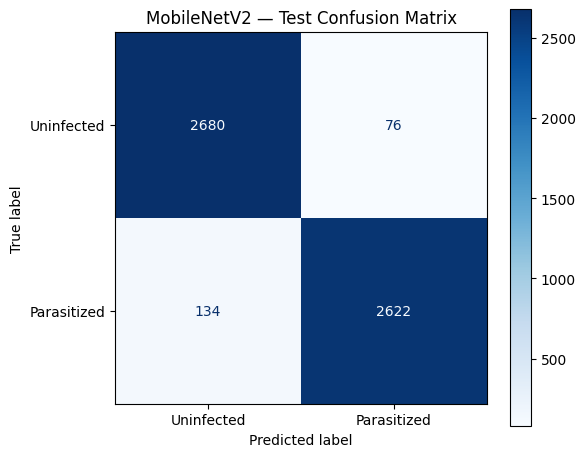

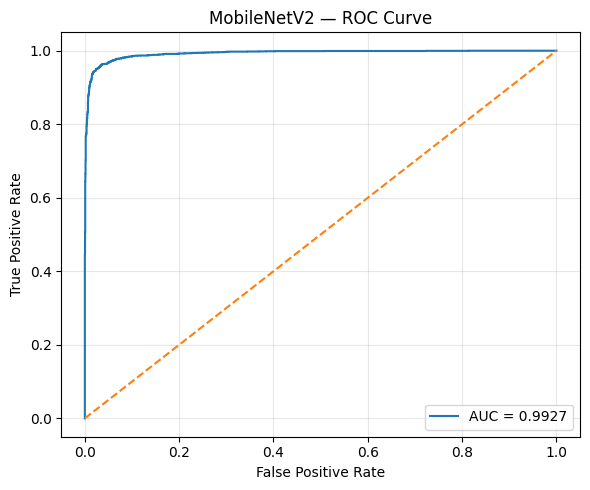

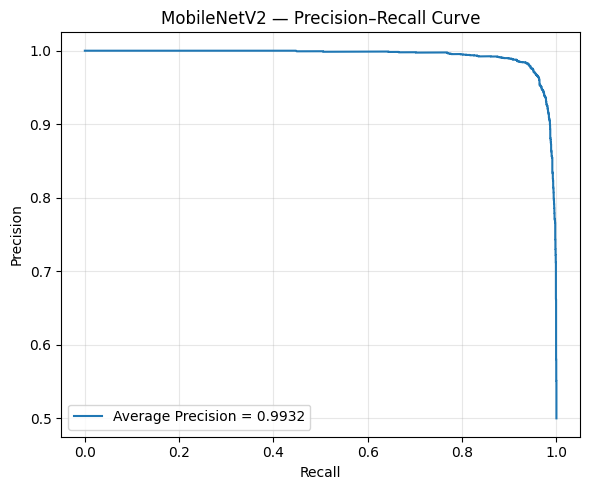

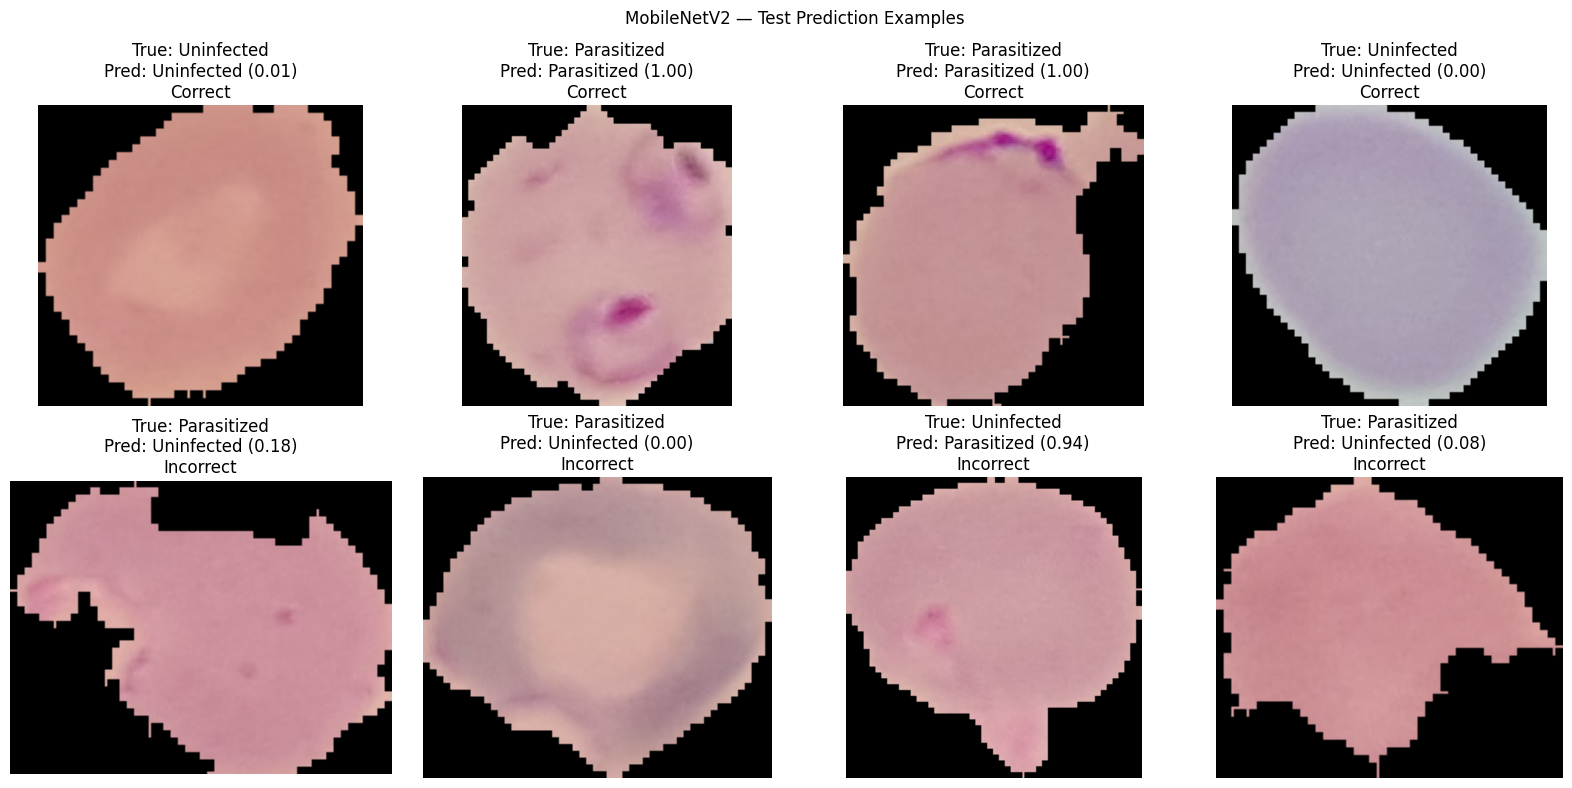


Graph verification:
mobilenetv2_confusion_matrix.png: Saved
mobilenetv2_roc_curve.png: Saved
mobilenetv2_precision_recall_curve.png: Saved
mobilenetv2_prediction_examples.png: Saved


In [50]:
# STEP 20.10 — MobileNetV2 Evaluation Graphs

import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, auc, precision_recall_curve,
    average_precision_score
)

RESULTS_DIR = "/kaggle/working/malaria_results"

pred_df = pd.read_csv(
    os.path.join(RESULTS_DIR, "mobilenetv2_test_predictions.csv")
)

y_true = pred_df["y_true"].to_numpy()
y_prob = pred_df["y_probability"].to_numpy()
y_pred = pred_df["y_predicted"].to_numpy()

# 1. Confusion matrix
cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Uninfected", "Parasitized"]
).plot(ax=ax, cmap="Blues", values_format="d")
ax.set_title("MobileNetV2 — Test Confusion Matrix")
fig.tight_layout()
fig.savefig(os.path.join(RESULTS_DIR, "mobilenetv2_confusion_matrix.png"), dpi=200)
plt.show()
plt.close(fig)

# 2. ROC curve
fpr, tpr, _ = roc_curve(y_true, y_prob)
roc_auc = auc(fpr, tpr)

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(fpr, tpr, label=f"AUC = {roc_auc:.4f}")
ax.plot([0, 1], [0, 1], linestyle="--")
ax.set(
    xlabel="False Positive Rate",
    ylabel="True Positive Rate",
    title="MobileNetV2 — ROC Curve"
)
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(os.path.join(RESULTS_DIR, "mobilenetv2_roc_curve.png"), dpi=200)
plt.show()
plt.close(fig)

# 3. Precision–recall curve
precision, recall, _ = precision_recall_curve(y_true, y_prob)
ap = average_precision_score(y_true, y_prob)

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(recall, precision, label=f"Average Precision = {ap:.4f}")
ax.set(
    xlabel="Recall",
    ylabel="Precision",
    title="MobileNetV2 — Precision–Recall Curve"
)
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(os.path.join(RESULTS_DIR, "mobilenetv2_precision_recall_curve.png"), dpi=200)
plt.show()
plt.close(fig)

# 4. Prediction examples — correct and incorrect predictions
rng = np.random.default_rng(42)
correct_idx = np.where(y_true == y_pred)[0]
wrong_idx = np.where(y_true != y_pred)[0]

selected = []
if len(correct_idx):
    selected.extend(rng.choice(correct_idx, min(4, len(correct_idx)), replace=False))
if len(wrong_idx):
    selected.extend(rng.choice(wrong_idx, min(4, len(wrong_idx)), replace=False))

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.ravel()

for ax in axes:
    ax.axis("off")

for ax, idx in zip(axes, selected):
    row = test_df.iloc[int(idx)]
    img = plt.imread(row["filepath"])
    ax.imshow(img)
    true_label = "Parasitized" if y_true[idx] == 1 else "Uninfected"
    pred_label = "Parasitized" if y_pred[idx] == 1 else "Uninfected"
    status = "Correct" if y_true[idx] == y_pred[idx] else "Incorrect"
    ax.set_title(
        f"True: {true_label}\nPred: {pred_label} ({y_prob[idx]:.2f})\n{status}"
    )
    ax.axis("off")

fig.suptitle("MobileNetV2 — Test Prediction Examples")
fig.tight_layout()
fig.savefig(os.path.join(RESULTS_DIR, "mobilenetv2_prediction_examples.png"), dpi=200)
plt.show()
plt.close(fig)

# Verify graph files
graph_files = [
    "mobilenetv2_confusion_matrix.png",
    "mobilenetv2_roc_curve.png",
    "mobilenetv2_precision_recall_curve.png",
    "mobilenetv2_prediction_examples.png"
]

print("\nGraph verification:")
for filename in graph_files:
    path = os.path.join(RESULTS_DIR, filename)
    print(f"{filename}: {'Saved' if os.path.exists(path) else 'MISSING'}")

Step 20.11 — Verify MobileNetV2 artifacts

In [51]:
# STEP 20.11 — Verify MobileNetV2 Files

import os

RESULTS_DIR = "/kaggle/working/malaria_results"

required_files = [
    "mobilenetv2_phase1_best.keras",
    "mobilenetv2_finetuned_best.keras",
    "mobilenetv2_phase1_history.csv",
    "mobilenetv2_finetuning_history.csv",
    "mobilenetv2_test_metrics.csv",
    "mobilenetv2_test_predictions.csv",
    "mobilenetv2_confusion_matrix.png",
    "mobilenetv2_roc_curve.png",
    "mobilenetv2_precision_recall_curve.png",
    "mobilenetv2_prediction_examples.png"
]

missing_files = []

for filename in required_files:
    path = os.path.join(RESULTS_DIR, filename)
    if os.path.isfile(path):
        print(f"OK      | {filename} | {os.path.getsize(path):,} bytes")
    else:
        print(f"MISSING | {filename}")
        missing_files.append(filename)

print("\nVerification:", "ALL FILES PRESENT" if not missing_files else "FILES MISSING")

OK      | mobilenetv2_phase1_best.keras | 9,639,147 bytes
OK      | mobilenetv2_finetuned_best.keras | 23,877,959 bytes
OK      | mobilenetv2_phase1_history.csv | 2,273 bytes
OK      | mobilenetv2_finetuning_history.csv | 1,825 bytes
OK      | mobilenetv2_test_metrics.csv | 209 bytes
OK      | mobilenetv2_test_predictions.csv | 82,880 bytes
OK      | mobilenetv2_confusion_matrix.png | 59,589 bytes
OK      | mobilenetv2_roc_curve.png | 65,625 bytes
OK      | mobilenetv2_precision_recall_curve.png | 53,294 bytes
OK      | mobilenetv2_prediction_examples.png | 281,161 bytes

Verification: ALL FILES PRESENT


Step 21.1 — Prepare EfficientNetB0

In [52]:
# STEP 21.1 — Prepare EfficientNetB0

import os
import tensorflow as tf
from tensorflow import keras

RESULTS_DIR = "/kaggle/working/malaria_results"

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

print("\nDataset availability:")
for name in ["train_ds", "val_ds", "test_ds", "test_df"]:
    print(f"{name}: {'Available' if name in globals() else 'MISSING'}")

print("\nEfficientNetB0 existing files:")
existing = [
    f for f in os.listdir(RESULTS_DIR)
    if "efficientnetb0" in f.lower()
]

if existing:
    for f in existing:
        print(f)
else:
    print("No existing EfficientNetB0 artifacts found.")

print("\nResults directory ready:", os.path.isdir(RESULTS_DIR))

TensorFlow version: 2.20.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]

Dataset availability:
train_ds: Available
val_ds: Available
test_ds: Available
test_df: Available

EfficientNetB0 existing files:
No existing EfficientNetB0 artifacts found.

Results directory ready: True


Step 21.2 — Build EfficientNetB0

In [53]:
# STEP 21.2 — Build EfficientNetB0

import os
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.keras.utils.set_random_seed(42)

RESULTS_DIR = "/kaggle/working/malaria_results"
os.makedirs(RESULTS_DIR, exist_ok=True)

# Pretrained EfficientNetB0 backbone
base_model = keras.applications.EfficientNetB0(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

# Classification head
inputs = keras.Input(shape=(224, 224, 3), name="input_image")

# Keras EfficientNetB0 includes its own input rescaling.
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(
    1,
    activation="sigmoid",
    name="malaria_prediction"
)(x)

model = keras.Model(
    inputs,
    outputs,
    name="EfficientNetB0_Malaria"
)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        keras.metrics.AUC(name="auc"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall")
    ]
)

model.summary()

print("\nEfficientNetB0 model built successfully.")
print("Backbone layers:", len(base_model.layers))
print(
    "Trainable parameters:",
    f"{sum(int(tf.size(w)) for w in model.trainable_weights):,}"
)

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "EfficientNetB0_Malaria"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_5      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ malaria_prediction (Dense)      │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,050,852 (15.45 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 4,049,571 (15.45 MB)


EfficientNetB0 model built successfully.
Backbone layers: 238
Trainable parameters: 1,281


Step 21.3 — Train EfficientNetB0 (Phase 1)

In [54]:
# STEP 21.3 — EfficientNetB0 Initial Training

import os
import pandas as pd
from tensorflow import keras

RESULTS_DIR = "/kaggle/working/malaria_results"

checkpoint_path = os.path.join(
    RESULTS_DIR, "efficientnetb0_phase1_best.keras"
)

callbacks = [
    keras.callbacks.ModelCheckpoint(
        checkpoint_path,
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

history_phase1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks,
    verbose=1
)

history_phase1_df = pd.DataFrame(history_phase1.history)
history_phase1_df["epoch"] = range(
    1, len(history_phase1_df) + 1
)

history_phase1_df.to_csv(
    os.path.join(
        RESULTS_DIR, "efficientnetb0_phase1_history.csv"
    ),
    index=False
)

print("\nEfficientNetB0 Phase 1 completed.")
print("Checkpoint saved:", os.path.exists(checkpoint_path))
print("Epochs completed:", len(history_phase1_df))
print("History saved: efficientnetb0_phase1_history.csv")

Epoch 1/10


2026-10-22 17:14:22.535293: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-22 17:14:22.678806: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-22 17:14:23.043608: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-22 17:14:23.187798: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-22 17:14:24.098333: E external/local_xla/xla/stream_

515/517 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.8482 - auc: 0.9222 - loss: 0.3571 - precision: 0.8511 - recall: 0.8424

2026-10-22 17:14:56.982225: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-22 17:14:57.123863: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-22 17:14:57.492651: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-22 17:14:57.636980: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-22 17:14:57.781006: E external/local_xla/xla/stream_

517/517 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.8484 - auc: 0.9224 - loss: 0.3568 - precision: 0.8513 - recall: 0.8426

2026-10-22 17:15:25.011799: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-22 17:15:25.148389: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-22 17:15:25.478039: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-22 17:15:25.621491: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-22 17:15:26.486351: E external/local_xla/xla/stream_


Epoch 1: val_accuracy improved from None to 0.92779, saving model to /kaggle/working/malaria_results/efficientnetb0_phase1_best.keras

Epoch 1: finished saving model to /kaggle/working/malaria_results/efficientnetb0_phase1_best.keras
517/517 ━━━━━━━━━━━━━━━━━━━━ 88s 113ms/step - accuracy: 0.8954 - auc: 0.9585 - loss: 0.2736 - precision: 0.8994 - recall: 0.8903 - val_accuracy: 0.9278 - val_auc: 0.9768 - val_loss: 0.1981 - val_precision: 0.9278 - val_recall: 0.9278 - learning_rate: 0.0010
Epoch 2/10
517/517 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.9275 - auc: 0.9760 - loss: 0.1997 - precision: 0.9312 - recall: 0.9217
Epoch 2: val_accuracy improved from 0.92779 to 0.93723, saving model to /kaggle/working/malaria_results/efficientnetb0_phase1_best.keras

Epoch 2: finished saving model to /kaggle/working/malaria_results/efficientnetb0_phase1_best.keras
517/517 ━━━━━━━━━━━━━━━━━━━━ 25s 49ms/step - accuracy: 0.9292 - auc: 0.9763 - loss: 0.1962 - precision: 0.9344 - recall: 0.9232 - va

Step 21.4 — Fine-tune EfficientNetB0

In [55]:
# STEP 21.4 — EfficientNetB0 Fine-tuning

import os
import pandas as pd
import tensorflow as tf
from tensorflow import keras

RESULTS_DIR = "/kaggle/working/malaria_results"

# Load the best Phase 1 checkpoint
model = keras.models.load_model(
    os.path.join(RESULTS_DIR, "efficientnetb0_phase1_best.keras")
)

# Locate the EfficientNetB0 backbone
base_model = next(
    layer for layer in model.layers
    if isinstance(layer, keras.Model)
    and "efficientnetb0" in layer.name.lower()
)

# Unfreeze later layers only
base_model.trainable = True
fine_tune_at = int(len(base_model.layers) * 0.70)

for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

# Keep Batch Normalization layers frozen
for layer in base_model.layers:
    if isinstance(layer, keras.layers.BatchNormalization):
        layer.trainable = False

# Recompile with a lower learning rate
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        keras.metrics.AUC(name="auc"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall")
    ]
)

print("Fine-tuning setup completed.")
print("Backbone layers:", len(base_model.layers))
print("Fine-tuning starts at layer:", fine_tune_at)
print(
    "Trainable parameters:",
    f"{sum(int(tf.size(w)) for w in model.trainable_weights):,}"
)

Fine-tuning setup completed.
Backbone layers: 238
Fine-tuning starts at layer: 166
Trainable parameters: 3,055,901


Step 21.5 — Train EfficientNetB0 (Fine-tuning)

In [56]:
# STEP 21.5 — EfficientNetB0 Fine-tuning Training

import os
import pandas as pd
from tensorflow import keras

RESULTS_DIR = "/kaggle/working/malaria_results"

checkpoint_path = os.path.join(
    RESULTS_DIR, "efficientnetb0_finetuned_best.keras"
)

callbacks = [
    keras.callbacks.ModelCheckpoint(
        checkpoint_path,
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

history_ft = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    callbacks=callbacks,
    verbose=1
)

history_ft_df = pd.DataFrame(history_ft.history)
history_ft_df["epoch"] = range(1, len(history_ft_df) + 1)

history_ft_df.to_csv(
    os.path.join(
        RESULTS_DIR, "efficientnetb0_finetuning_history.csv"
    ),
    index=False
)

print("\nEfficientNetB0 fine-tuning completed.")
print("Best checkpoint saved:", os.path.exists(checkpoint_path))
print("Epochs completed:", len(history_ft_df))
print("History saved: efficientnetb0_finetuning_history.csv")

Epoch 1/8
517/517 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step - accuracy: 0.9456 - auc: 0.9830 - loss: 0.1562 - precision: 0.9513 - recall: 0.9392
Epoch 1: val_accuracy improved from None to 0.95229, saving model to /kaggle/working/malaria_results/efficientnetb0_finetuned_best.keras

Epoch 1: finished saving model to /kaggle/working/malaria_results/efficientnetb0_finetuned_best.keras
517/517 ━━━━━━━━━━━━━━━━━━━━ 95s 121ms/step - accuracy: 0.9484 - auc: 0.9846 - loss: 0.1490 - precision: 0.9555 - recall: 0.9406 - val_accuracy: 0.9523 - val_auc: 0.9878 - val_loss: 0.1365 - val_precision: 0.9601 - val_recall: 0.9438 - learning_rate: 1.0000e-05
Epoch 2/8
517/517 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.9589 - auc: 0.9889 - loss: 0.1242 - precision: 0.9664 - recall: 0.9510
Epoch 2: val_accuracy improved from 0.95229 to 0.95483, saving model to /kaggle/working/malaria_results/efficientnetb0_finetuned_best.keras

Epoch 2: finished saving model to /kaggle/working/malaria_results/efficientnetb0_fi

Step 21.6 — Evaluate EfficientNetB0

In [57]:

# STEP 21.6 — EfficientNetB0 Test Evaluation

import os
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score
)
from tensorflow import keras

RESULTS_DIR = "/kaggle/working/malaria_results"

# Load the best fine-tuned model
model = keras.models.load_model(
    os.path.join(RESULTS_DIR, "efficientnetb0_finetuned_best.keras")
)

# Predict on the untouched test dataset
y_true = test_df["label"].to_numpy().astype(int)
y_probability = model.predict(test_ds, verbose=1).ravel()

# Verify prediction alignment
assert len(y_true) == len(y_probability), (
    f"Mismatch: {len(y_true)} labels vs "
    f"{len(y_probability)} predictions"
)

y_predicted = (y_probability >= 0.5).astype(int)

# Calculate test metrics
metrics = {
    "model": "EfficientNetB0",
    "accuracy": accuracy_score(y_true, y_predicted),
    "precision": precision_score(y_true, y_predicted, zero_division=0),
    "recall": recall_score(y_true, y_predicted, zero_division=0),
    "f1_score": f1_score(y_true, y_predicted, zero_division=0),
    "roc_auc": roc_auc_score(y_true, y_probability),
    "average_precision": average_precision_score(y_true, y_probability),
    "test_samples": len(y_true)
}

metrics_df = pd.DataFrame([metrics])
metrics_path = os.path.join(
    RESULTS_DIR, "efficientnetb0_test_metrics.csv"
)
metrics_df.to_csv(metrics_path, index=False)

# Save individual predictions for later analysis
predictions_df = pd.DataFrame({
    "y_true": y_true,
    "y_probability": y_probability,
    "y_predicted": y_predicted
})
predictions_path = os.path.join(
    RESULTS_DIR, "efficientnetb0_test_predictions.csv"
)
predictions_df.to_csv(predictions_path, index=False)

print("\nEfficientNetB0 — TEST RESULTS")
display(metrics_df.round(4))
print("\nMetrics saved:", os.path.exists(metrics_path))
print("Predictions saved:", os.path.exists(predictions_path))


173/173 ━━━━━━━━━━━━━━━━━━━━ 20s 77ms/step

EfficientNetB0 — TEST RESULTS


,model,accuracy,precision,recall,f1_score,roc_auc,average_precision,test_samples
0,EfficientNetB0,0.9663,0.9735,0.9586,0.966,0.9939,0.9943,5512



Metrics saved: True
Predictions saved: True


Step 21.7 — Generate four evaluation graphs

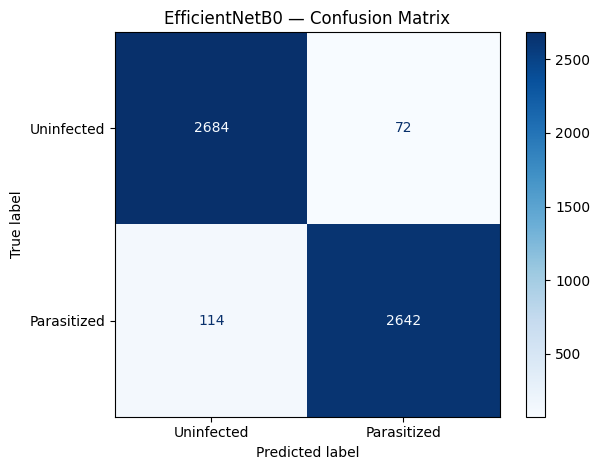

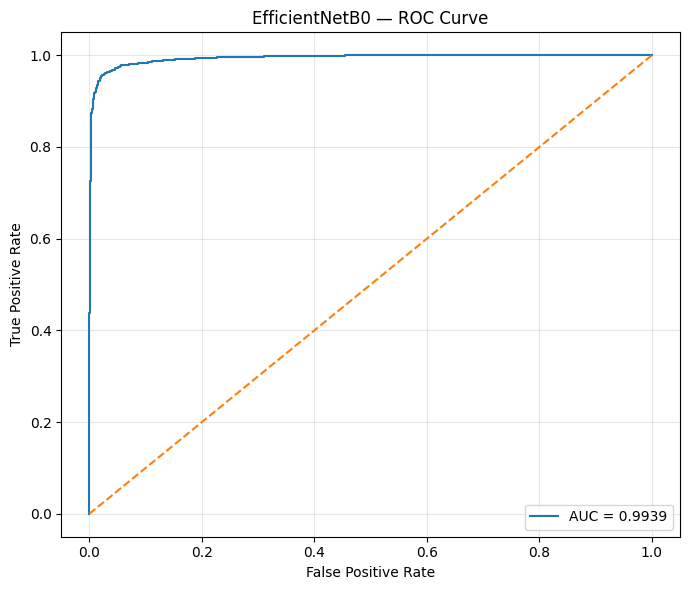

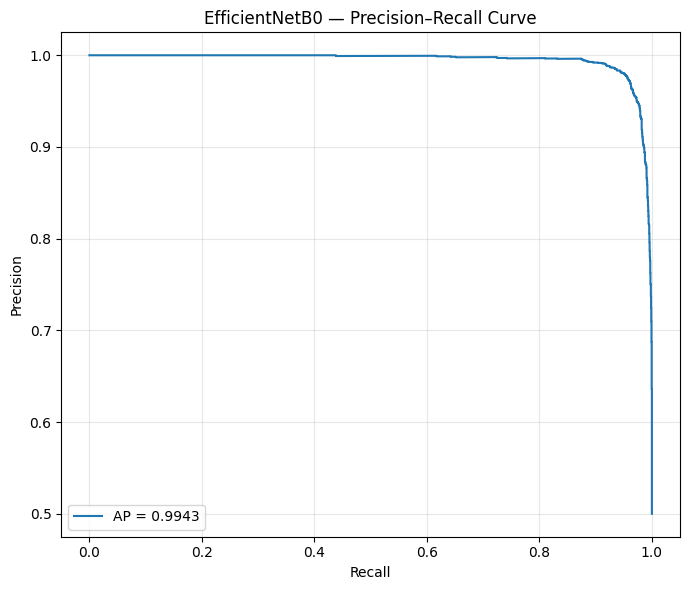

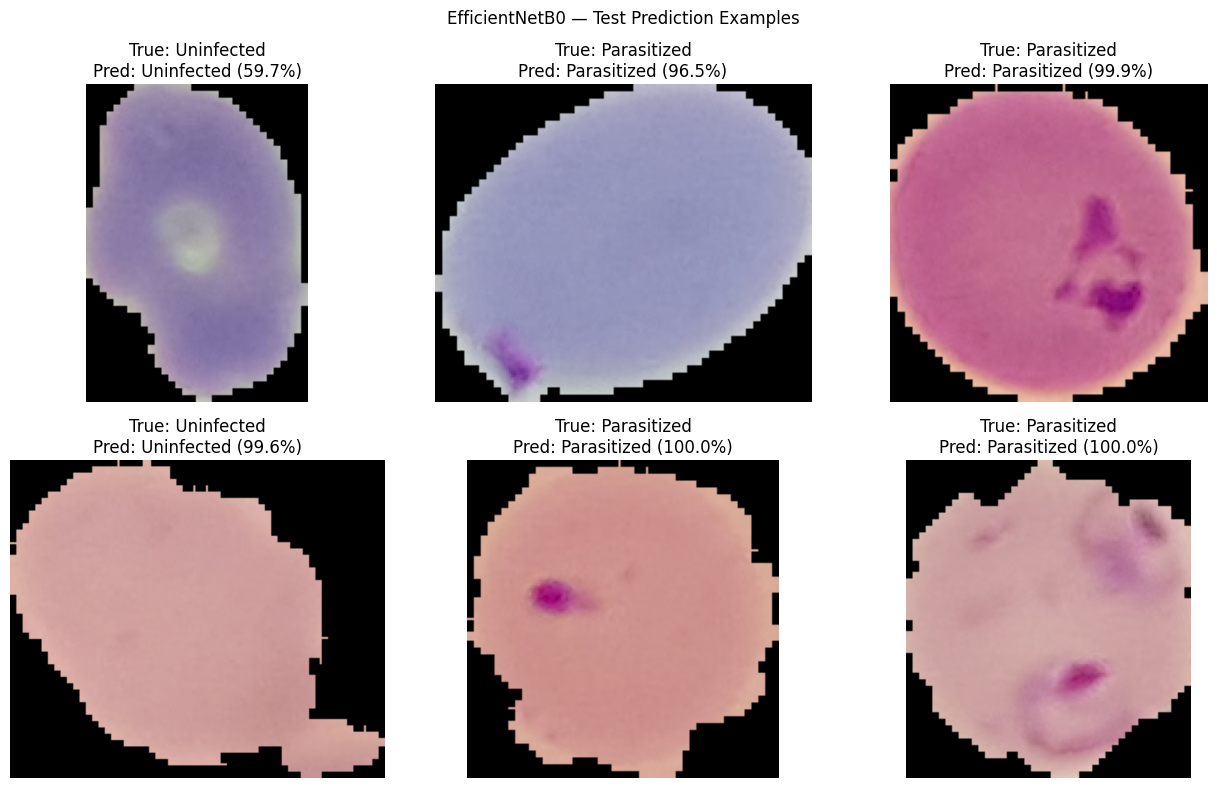


All four graphs generated.


In [58]:

# STEP 21.7 — EfficientNetB0 Evaluation Graphs

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, auc, precision_recall_curve,
    average_precision_score
)
from PIL import Image

RESULTS_DIR = "/kaggle/working/malaria_results"

pred_df = pd.read_csv(
    os.path.join(RESULTS_DIR, "efficientnetb0_test_predictions.csv")
)

y_true = pred_df["y_true"].to_numpy().astype(int)
y_prob = pred_df["y_probability"].to_numpy()
y_pred = pred_df["y_predicted"].to_numpy().astype(int)

# 1. Confusion matrix
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Uninfected", "Parasitized"]
)
disp.plot(cmap="Blues", values_format="d")
plt.title("EfficientNetB0 — Confusion Matrix")
plt.tight_layout()
plt.savefig(
    os.path.join(RESULTS_DIR, "efficientnetb0_confusion_matrix.png"),
    dpi=300, bbox_inches="tight"
)
plt.show()
plt.close()

# 2. ROC curve
fpr, tpr, _ = roc_curve(y_true, y_prob)
roc_auc_value = auc(fpr, tpr)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc_value:.4f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("EfficientNetB0 — ROC Curve")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    os.path.join(RESULTS_DIR, "efficientnetb0_roc_curve.png"),
    dpi=300, bbox_inches="tight"
)
plt.show()
plt.close()

# 3. Precision–Recall curve
pr_precision, pr_recall, _ = precision_recall_curve(y_true, y_prob)
ap_value = average_precision_score(y_true, y_prob)

plt.figure(figsize=(7, 6))
plt.plot(pr_recall, pr_precision, label=f"AP = {ap_value:.4f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("EfficientNetB0 — Precision–Recall Curve")
plt.legend(loc="lower left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    os.path.join(RESULTS_DIR, "efficientnetb0_precision_recall_curve.png"),
    dpi=300, bbox_inches="tight"
)
plt.show()
plt.close()

# 4. Prediction examples
# Use the exact test_df ordering corresponding to the predictions.
rng = np.random.default_rng(42)
sample_indices = rng.choice(
    len(y_true), size=min(6, len(y_true)), replace=False
)

fig, axes = plt.subplots(2, 3, figsize=(13, 8))
axes = axes.flatten()

for ax, idx in zip(axes, sample_indices):
    image_path = test_df.iloc[idx]["filepath"]
    img = Image.open(image_path).convert("RGB")

    true_label = "Parasitized" if y_true[idx] == 1 else "Uninfected"
    pred_label = "Parasitized" if y_pred[idx] == 1 else "Uninfected"
    confidence = y_prob[idx] if y_pred[idx] == 1 else 1 - y_prob[idx]

    ax.imshow(img)
    ax.set_title(
        f"True: {true_label}\nPred: {pred_label} ({confidence:.1%})"
    )
    ax.axis("off")

for ax in axes[len(sample_indices):]:
    ax.axis("off")

plt.suptitle("EfficientNetB0 — Test Prediction Examples")
plt.tight_layout()
plt.savefig(
    os.path.join(RESULTS_DIR, "efficientnetb0_prediction_examples.png"),
    dpi=300, bbox_inches="tight"
)
plt.show()
plt.close()

print("\nAll four graphs generated.")


Step 21.8 — Verify all EfficientNetB0 files

In [59]:

# STEP 21.8 — Verify EfficientNetB0 Artifacts

import os

RESULTS_DIR = "/kaggle/working/malaria_results"

required_files = [
    "efficientnetb0_phase1_best.keras",
    "efficientnetb0_finetuned_best.keras",
    "efficientnetb0_phase1_history.csv",
    "efficientnetb0_finetuning_history.csv",
    "efficientnetb0_test_metrics.csv",
    "efficientnetb0_test_predictions.csv",
    "efficientnetb0_confusion_matrix.png",
    "efficientnetb0_roc_curve.png",
    "efficientnetb0_precision_recall_curve.png",
    "efficientnetb0_prediction_examples.png",
]

all_present = True

for filename in required_files:
    path = os.path.join(RESULTS_DIR, filename)
    exists = os.path.isfile(path)
    if not exists:
        all_present = False

    size_mb = os.path.getsize(path) / (1024 * 1024) if exists else 0
    print(f"{'OK' if exists else 'MISSING'} | {filename} | {size_mb:.2f} MB")

print("\nEfficientNetB0 verification:", 
      "ALL FILES PRESENT" if all_present else "SOME FILES MISSING")


OK | efficientnetb0_phase1_best.keras | 16.27 MB
OK | efficientnetb0_finetuned_best.keras | 39.59 MB
OK | efficientnetb0_phase1_history.csv | 0.00 MB
OK | efficientnetb0_finetuning_history.csv | 0.00 MB
OK | efficientnetb0_test_metrics.csv | 0.00 MB
OK | efficientnetb0_test_predictions.csv | 0.08 MB
OK | efficientnetb0_confusion_matrix.png | 0.08 MB
OK | efficientnetb0_roc_curve.png | 0.11 MB
OK | efficientnetb0_precision_recall_curve.png | 0.08 MB
OK | efficientnetb0_prediction_examples.png | 0.29 MB

EfficientNetB0 verification: ALL FILES PRESENT


Step 22.1 — Check the Kaggle environment

In [60]:

# STEP 22.1 — Check YOLOv11 Environment

import os
import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

try:
    import ultralytics
    print("Ultralytics version:", ultralytics.__version__)
except ImportError:
    print("Ultralytics is not installed yet.")

print(
    "\nDataset split CSV exists:",
    os.path.isfile("/kaggle/working/malaria_data_splits.csv")
)

print(
    "Results directory exists:",
    os.path.isdir("/kaggle/working/malaria_results")
)


TensorFlow: 2.20.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
Ultralytics is not installed yet.

Dataset split CSV exists: True
Results directory exists: True


Step 22.2 — Install YOLOv11 dependencies

In [61]:

# STEP 22.2 — Install Ultralytics

%pip install -q ultralytics


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 29.4 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 5.1 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


Step 22.3 — Verify YOLOv11

In [62]:

# STEP 22.3 — Verify Ultralytics and YOLOv11

import torch
import ultralytics
from ultralytics import YOLO

print("Ultralytics version:", ultralytics.__version__)
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())

# Load the YOLO11 classification model
model = YOLO("yolo11n-cls.pt")

print("\nYOLO11 classification model loaded successfully.")
print("Model task:", model.task)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics version: 8.4.183
PyTorch version: 2.11.0+cu128
CUDA available: True
GPU count: 2

YOLO11 classification model loaded successfully.
Model task: classify


Step 22.4 — Prepare the YOLO11 dataset

In [63]:

# STEP 22.4 — Prepare YOLO11 Classification Folders

import os
import shutil
import pandas as pd
from tqdm.auto import tqdm

CSV_PATH = "/kaggle/working/malaria_data_splits.csv"
YOLO_DATA_DIR = "/kaggle/working/malaria_yolo"

split_df = pd.read_csv(CSV_PATH)

# Map the existing split names to YOLO folder names
split_map = {
    "train": "train",
    "validation": "val",
    "test": "test"
}

# Check required columns
required_columns = {"filepath", "class_name", "split"}
assert required_columns.issubset(split_df.columns), (
    f"Missing columns: {required_columns - set(split_df.columns)}"
)

# Validate paths and labels before copying
assert split_df["filepath"].map(os.path.isfile).all(), (
    "Some image paths do not exist."
)
assert set(split_df["class_name"].unique()) == {
    "Parasitized", "Uninfected"
}, "Unexpected class names found."

# Create destination folders
for split_name in split_map.values():
    for class_name in ["Parasitized", "Uninfected"]:
        os.makedirs(
            os.path.join(YOLO_DATA_DIR, split_name, class_name),
            exist_ok=True
        )

# Copy each image into its assigned split and class
for _, row in tqdm(split_df.iterrows(), total=len(split_df)):
    source = row["filepath"]
    destination_folder = os.path.join(
        YOLO_DATA_DIR,
        split_map[row["split"]],
        row["class_name"]
    )
    destination = os.path.join(
        destination_folder,
        os.path.basename(source)
    )

    if not os.path.exists(destination):
        shutil.copy2(source, destination)

# Report resulting counts
print("\nYOLO11 dataset preparation summary:")
for split_name in ["train", "val", "test"]:
    print(f"\n{split_name.upper()}")
    for class_name in ["Parasitized", "Uninfected"]:
        folder = os.path.join(
            YOLO_DATA_DIR, split_name, class_name
        )
        count = sum(
            os.path.isfile(os.path.join(folder, filename))
            for filename in os.listdir(folder)
        )
        print(f"  {class_name}: {count}")

print("\nDataset folder:", YOLO_DATA_DIR)


  0%|          | 0/27558 [00:00<?, ?it/s]


YOLO11 dataset preparation summary:

TRAIN
  Parasitized: 8267
  Uninfected: 8267

VAL
  Parasitized: 2756
  Uninfected: 2756

TEST
  Parasitized: 2756
  Uninfected: 2756

Dataset folder: /kaggle/working/malaria_yolo


Step 22.5 — Train YOLO11 classification

In [64]:

# STEP 22.5 — Train YOLO11n Classification

import os
import torch
from ultralytics import YOLO

DATA_DIR = "/kaggle/working/malaria_yolo"
RESULTS_DIR = "/kaggle/working/malaria_results"
RUNS_DIR = "/kaggle/working/yolo11_malaria_runs"

os.makedirs(RESULTS_DIR, exist_ok=True)

# Load pretrained YOLO11 classification weights
model = YOLO("yolo11n-cls.pt")

# Train using the existing train/validation split
results = model.train(
    data=DATA_DIR,
    epochs=30,
    imgsz=224,
    batch=32,
    patience=5,
    optimizer="AdamW",
    lr0=0.001,
    seed=42,
    deterministic=True,
    workers=4,
    device=0,
    project=RUNS_DIR,
    name="yolo11n_malaria",
    exist_ok=True,
    plots=True,
    save=True,
    verbose=True
)

print("\nYOLO11 training finished.")
print("Run directory:", os.path.join(RUNS_DIR, "yolo11n_malaria"))
print("Best model:", os.path.join(
    RUNS_DIR, "yolo11n_malaria", "weights", "best.pt"
))
print("CUDA available:", torch.cuda.is_available())


New https://pypi.org/project/ultralytics/8.4.184 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/malaria_yolo, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n-cls.pt, mome

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/30     0.516G     0.2639         22        224: 100% ━━━━━━━━━━━━ 517/517 9.5it/s 54.2s<0.1ss
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 87/87 10.1it/s 8.6s.1ss
                   all      0.951          1

      Epoch    GPU_mem       loss  Instances       Size
       3/30     0.516G     0.2469         22        224: 100% ━━━━━━━━━━━━ 517/517 9.6it/s 53.7s<0.1ss
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 87/87 10.2it/s 8.6s.2ss
                   all      0.952          1

      Epoch    GPU_mem       loss  Instances       Size
       4/30     0.516G     0.2353         22        224: 100% ━━━━━━━━━━━━ 517/517 9.6it/s 54.1s0.2sss
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 87/87 10.0it/s 8.7s.1ss
                   all      0.957          1

      Epoch    GPU_mem       loss  Instances       Size
       5/30     0.516G     0.2203         22        224: 100% ━━━━━━━━━━━━ 517/517 9.7it/s 53.3s<0.1ss
               cla

Step 22.6 — Fix GPU memory error

In [67]:
import gc
import numpy as np
import pandas as pd
import torch
from pathlib import Path
from ultralytics import YOLO

# Clear unused GPU memory
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# Load the trained model
model = YOLO(
    "/kaggle/working/yolo11_malaria_runs/"
    "yolo11n_malaria/weights/best.pt"
)

TEST_DIR = Path("/kaggle/working/malaria_yolo/test")
OUTPUT_CSV = (
    "/kaggle/working/malaria_results/"
    "yolo11_test_predictions.csv"
)

class_names = ["Parasitized", "Uninfected"]
image_paths = []
y_true = []

for class_name in class_names:
    for path in sorted((TEST_DIR / class_name).iterdir()):
        if path.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}:
            image_paths.append(str(path))
            y_true.append(class_names.index(class_name))

# Verify class-index alignment
print("Model classes:", model.names)
assert model.names[0] == "Parasitized"
assert model.names[1] == "Uninfected"

# Predict in small batches and save each batch
first_batch = True
batch_size = 8

for start in range(0, len(image_paths), batch_size):
    batch_paths = image_paths[start:start + batch_size]

    results = model.predict(
        source=batch_paths,
        imgsz=224,
        batch=8,
        device=0,
        verbose=False,
        stream=False
    )

    batch_df = pd.DataFrame({
        "filepath": batch_paths,
        "y_true": y_true[start:start + len(batch_paths)],
        "y_probability": [
            result.probs.data[0].item() for result in results
        ]
    })

    batch_df["y_predicted"] = (
        batch_df["y_probability"] >= 0.5
    ).astype(int)

    batch_df.to_csv(
        OUTPUT_CSV,
        mode="w" if first_batch else "a",
        header=first_batch,
        index=False
    )

    first_batch = False
    del results, batch_df
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    if (start // batch_size) % 50 == 0:
        print(f"Processed {min(start + batch_size, len(image_paths))}"
              f" / {len(image_paths)} images")

print("\nPrediction complete!")
print("Saved to:", OUTPUT_CSV)
print("Total images:", len(pd.read_csv(OUTPUT_CSV)))

Model classes: {0: 'Parasitized', 1: 'Uninfected'}
Processed 8 / 5512 images
Processed 408 / 5512 images
Processed 808 / 5512 images
Processed 1208 / 5512 images
Processed 1608 / 5512 images
Processed 2008 / 5512 images
Processed 2408 / 5512 images
Processed 2808 / 5512 images
Processed 3208 / 5512 images
Processed 3608 / 5512 images
Processed 4008 / 5512 images
Processed 4408 / 5512 images
Processed 4808 / 5512 images
Processed 5208 / 5512 images

Prediction complete!
Saved to: /kaggle/working/malaria_results/yolo11_test_predictions.csv
Total images: 5512


Step 22.7 — Calculate YOLO11 evaluation metrics

In [70]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score
)

path = "/kaggle/working/malaria_results/yolo11_test_predictions.csv"
metrics_path = "/kaggle/working/malaria_results/yolo11_test_metrics.csv"

df = pd.read_csv(path)

y_true = df["y_true"].to_numpy()
y_pred = df["y_predicted"].to_numpy()
y_prob = df["y_probability"].to_numpy()

metrics = {
    "model": "YOLO11n-cls",
    "test_samples": len(df),
    "accuracy": accuracy_score(y_true, y_pred),
    "precision": precision_score(y_true, y_pred, zero_division=0),
    "recall": recall_score(y_true, y_pred, zero_division=0),
    "f1_score": f1_score(y_true, y_pred, zero_division=0),
    "roc_auc": roc_auc_score(y_true, y_prob),
    "average_precision": average_precision_score(y_true, y_prob)
}

pd.DataFrame([metrics]).to_csv(metrics_path, index=False)

for key, value in metrics.items():
    if isinstance(value, (float, int)) and key != "test_samples":
        print(f"{key}: {value:.4f} ({value * 100:.2f}%)")
    else:
        print(f"{key}: {value}")

print("\nSaved:", metrics_path)

model: YOLO11n-cls
test_samples: 5512
accuracy: 0.9690 (96.90%)
precision: 0.9648 (96.48%)
recall: 0.9735 (97.35%)
f1_score: 0.9691 (96.91%)
roc_auc: 0.9955 (99.55%)
average_precision: 0.9952 (99.52%)

Saved: /kaggle/working/malaria_results/yolo11_test_metrics.csv


Step 22.8 — Generate YOLO11 evaluation graphs

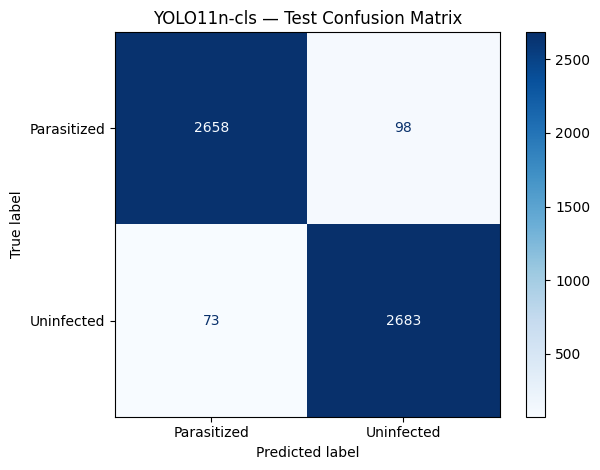

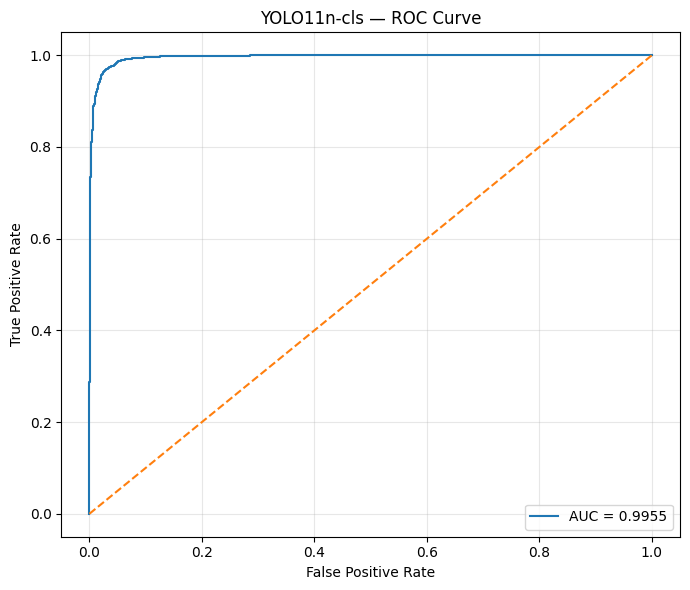

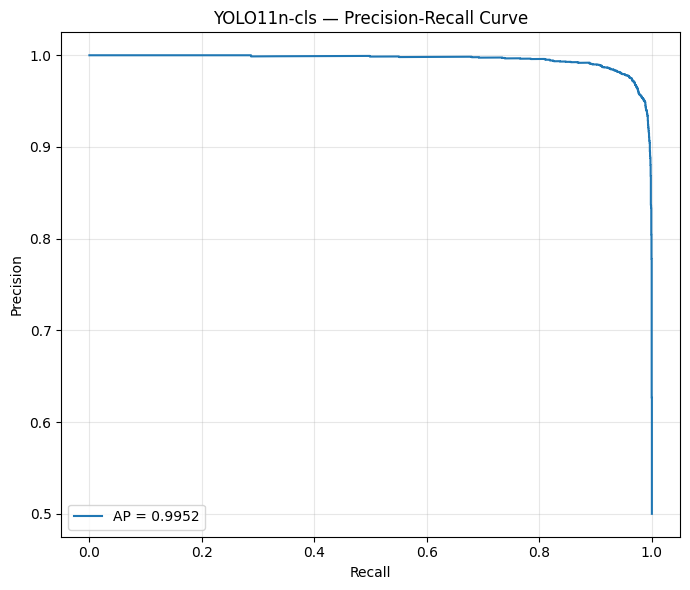

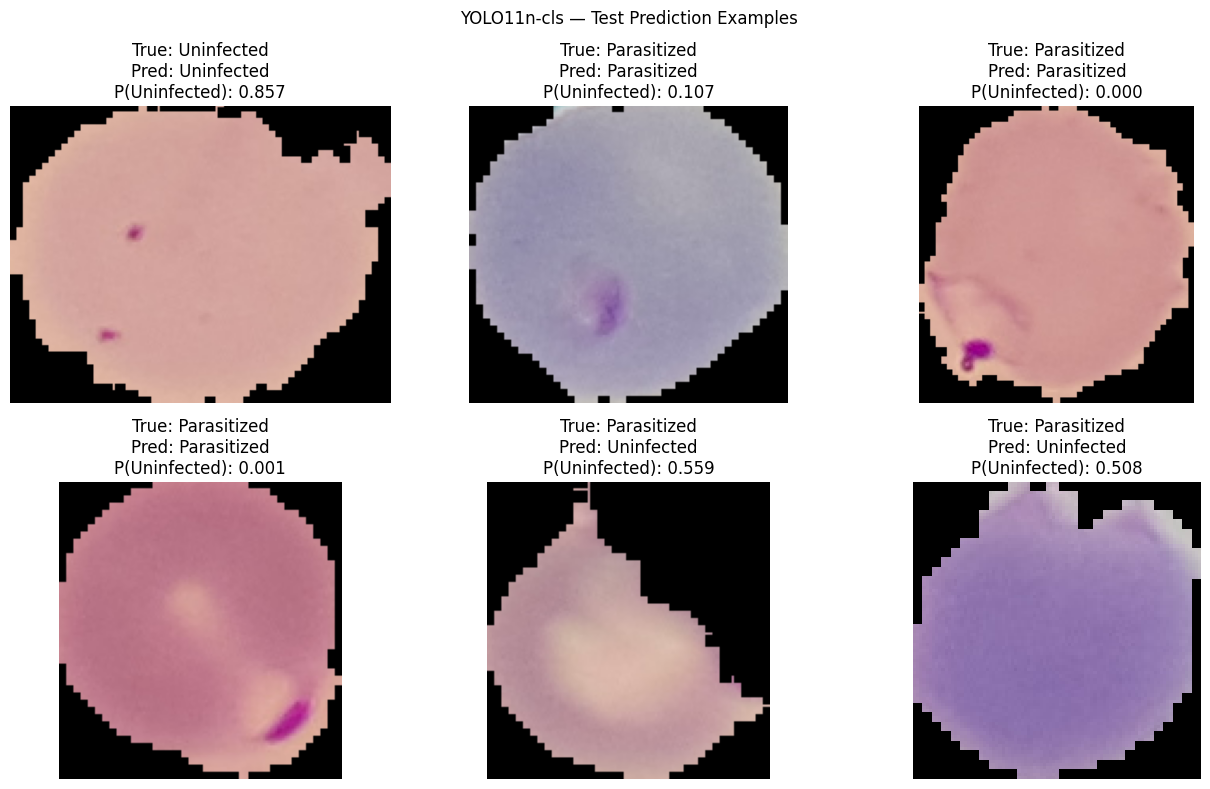


Graph verification:
yolo11_confusion_matrix.png: Saved
yolo11_roc_curve.png: Saved
yolo11_precision_recall_curve.png: Saved
yolo11_prediction_examples.png: Saved


In [71]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, auc, precision_recall_curve,
    average_precision_score
)

RESULTS_DIR = "/kaggle/working/malaria_results"
df = pd.read_csv(f"{RESULTS_DIR}/yolo11_test_predictions.csv")

y_true = df["y_true"].to_numpy()
y_pred = df["y_predicted"].to_numpy()
y_prob = df["y_probability"].to_numpy()

class_names = ["Parasitized", "Uninfected"]

# 1. Confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
disp = ConfusionMatrixDisplay(cm, display_labels=class_names)
disp.plot(cmap="Blues", values_format="d")
plt.title("YOLO11n-cls — Test Confusion Matrix")
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/yolo11_confusion_matrix.png", dpi=300)
plt.show()
plt.close()

# 2. ROC curve
fpr, tpr, _ = roc_curve(y_true, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.4f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("YOLO11n-cls — ROC Curve")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/yolo11_roc_curve.png", dpi=300)
plt.show()
plt.close()

# 3. Precision-recall curve
precision, recall, _ = precision_recall_curve(y_true, y_prob)
ap = average_precision_score(y_true, y_prob)

plt.figure(figsize=(7, 6))
plt.plot(recall, precision, label=f"AP = {ap:.4f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("YOLO11n-cls — Precision-Recall Curve")
plt.legend(loc="lower left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    f"{RESULTS_DIR}/yolo11_precision_recall_curve.png", dpi=300
)
plt.show()
plt.close()

# 4. Prediction examples: correct and incorrect predictions
correct_idx = np.where(y_true == y_pred)[0]
wrong_idx = np.where(y_true != y_pred)[0]

random.seed(42)
chosen = []

if len(correct_idx):
    chosen.extend(random.sample(
        list(correct_idx), min(4, len(correct_idx))
    ))
if len(wrong_idx):
    chosen.extend(random.sample(
        list(wrong_idx), min(2, len(wrong_idx))
    ))

fig, axes = plt.subplots(2, 3, figsize=(13, 8))
axes = axes.flatten()

for ax, idx in zip(axes, chosen):
    img = Image.open(df.iloc[idx]["filepath"]).convert("RGB")
    ax.imshow(img)
    true_label = class_names[y_true[idx]]
    pred_label = class_names[y_pred[idx]]
    ax.set_title(
        f"True: {true_label}\nPred: {pred_label}\n"
        f"P(Uninfected): {y_prob[idx]:.3f}"
    )
    ax.axis("off")

for ax in axes[len(chosen):]:
    ax.axis("off")

plt.suptitle("YOLO11n-cls — Test Prediction Examples")
plt.tight_layout()
plt.savefig(
    f"{RESULTS_DIR}/yolo11_prediction_examples.png", dpi=300
)
plt.show()
plt.close()

# Verify saved files
expected = [
    "yolo11_confusion_matrix.png",
    "yolo11_roc_curve.png",
    "yolo11_precision_recall_curve.png",
    "yolo11_prediction_examples.png"
]

print("\nGraph verification:")
for filename in expected:
    full_path = os.path.join(RESULTS_DIR, filename)
    print(f"{filename}: {'Saved' if os.path.exists(full_path) else 'MISSING'}")

Step 22.9 — Verify all model results and files

In [72]:
import os
import pandas as pd

RESULTS_DIR = "/kaggle/working/malaria_results"

models = [
    "optimized_resnet50",
    "vgg19",
    "densenet201",
    "mobilenetv2",
    "efficientnetb0",
    "yolo11"
]

print("MODEL METRICS AND PREDICTION FILES")
print("=" * 65)

for model in models:
    metrics_file = os.path.join(
        RESULTS_DIR, f"{model}_test_metrics.csv"
    )
    predictions_file = os.path.join(
        RESULTS_DIR, f"{model}_test_predictions.csv"
    )

    print(f"\n{model.upper()}")

    if os.path.exists(metrics_file):
        metrics = pd.read_csv(metrics_file)
        print("Metrics: SAVED")
        print(metrics.to_string(index=False))
    else:
        print("Metrics: MISSING")

    if os.path.exists(predictions_file):
        predictions = pd.read_csv(predictions_file)
        print(f"Predictions: SAVED ({len(predictions)} rows)")
    else:
        print("Predictions: MISSING")

print("\nVerification complete.")

MODEL METRICS AND PREDICTION FILES

OPTIMIZED_RESNET50
Metrics: MISSING
Predictions: MISSING

VGG19
Metrics: SAVED
Model  Accuracy  Precision   Recall  F1-score  ROC-AUC  Average Precision
VGG19  0.969521   0.967486 0.971698  0.969587 0.994919           0.995547
Predictions: SAVED (5512 rows)

DENSENET201
Metrics: SAVED
      model  accuracy  precision   recall  f1_score  roc_auc  average_precision  test_samples
DenseNet201  0.964441   0.967495 0.961176  0.964325 0.993365           0.993984          5512
Predictions: SAVED (5512 rows)

MOBILENETV2
Metrics: SAVED
      model  accuracy  precision   recall  f1_score  roc_auc  average_precision  test_samples
MobileNetV2  0.961901   0.971831 0.951379  0.961496 0.992663           0.993221          5512
Predictions: SAVED (5512 rows)

EFFICIENTNETB0
Metrics: SAVED
         model  accuracy  precision   recall  f1_score  roc_auc  average_precision  test_samples
EfficientNetB0  0.966255   0.973471 0.958636  0.965996 0.993868            0.99427  

Step 22.10 — Check the ResNet50 files

In [73]:
import os

folders = [
    "/kaggle/working/malaria_results",
    "/kaggle/working/drive/MyDrive/Malaria Detection/Trained Models",
    "/content/drive/MyDrive/Malaria Detection/Trained Models"
]

for folder in folders:
    print(f"\nChecking: {folder}")
    if os.path.isdir(folder):
        for name in sorted(os.listdir(folder)):
            if "resnet50" in name.lower():
                print("  ", name)
    else:
        print("  Folder not found")


Checking: /kaggle/working/malaria_results
   optimized_resnet50_best.keras
   optimized_resnet50_finetuned_best.keras
   resnet50_confusion_matrix.png
   resnet50_error_analysis.png
   resnet50_finetuning_curves.png
   resnet50_finetuning_history.csv
   resnet50_gradcam.png
   resnet50_learning_curves.png
   resnet50_misclassified_images.csv
   resnet50_precision_recall_curve.png
   resnet50_prediction_examples.png
   resnet50_roc_curve.png
   resnet50_test_metrics.csv
   resnet50_test_predictions.csv
   resnet50_training_history.csv
   resnet50_training_history.json

Checking: /kaggle/working/drive/MyDrive/Malaria Detection/Trained Models
  Folder not found

Checking: /content/drive/MyDrive/Malaria Detection/Trained Models
  Folder not found


Step 22.11 — Verify all six models correctly

In [74]:
import os
import pandas as pd

RESULTS_DIR = "/kaggle/working/malaria_results"

files = {
    "Optimized ResNet50": [
        "resnet50_test_metrics.csv",
        "resnet50_test_predictions.csv"
    ],
    "VGG19": [
        "vgg19_test_metrics.csv",
        "vgg19_test_predictions.csv"
    ],
    "DenseNet201": [
        "densenet201_test_metrics.csv",
        "densenet201_test_predictions.csv"
    ],
    "MobileNetV2": [
        "mobilenetv2_test_metrics.csv",
        "mobilenetv2_test_predictions.csv"
    ],
    "EfficientNetB0": [
        "efficientnetb0_test_metrics.csv",
        "efficientnetb0_test_predictions.csv"
    ],
    "YOLO11n-cls": [
        "yolo11_test_metrics.csv",
        "yolo11_test_predictions.csv"
    ]
}

for model_name, filenames in files.items():
    print(f"\n{model_name}")
    for filename in filenames:
        path = os.path.join(RESULTS_DIR, filename)

        if os.path.exists(path):
            df = pd.read_csv(path)
            print(f"  OK: {filename} ({len(df)} rows)")
            if "metrics" in filename:
                print(df.to_string(index=False))
        else:
            print(f"  MISSING: {filename}")


Optimized ResNet50
  OK: resnet50_test_metrics.csv (1 rows)
 Accuracy  Precision   Recall  F1-score  ROC-AUC  Average Precision
 0.858672   0.853667 0.865747  0.859665 0.941278           0.946194
  OK: resnet50_test_predictions.csv (5512 rows)

VGG19
  OK: vgg19_test_metrics.csv (1 rows)
Model  Accuracy  Precision   Recall  F1-score  ROC-AUC  Average Precision
VGG19  0.969521   0.967486 0.971698  0.969587 0.994919           0.995547
  OK: vgg19_test_predictions.csv (5512 rows)

DenseNet201
  OK: densenet201_test_metrics.csv (1 rows)
      model  accuracy  precision   recall  f1_score  roc_auc  average_precision  test_samples
DenseNet201  0.964441   0.967495 0.961176  0.964325 0.993365           0.993984          5512
  OK: densenet201_test_predictions.csv (5512 rows)

MobileNetV2
  OK: mobilenetv2_test_metrics.csv (1 rows)
      model  accuracy  precision   recall  f1_score  roc_auc  average_precision  test_samples
MobileNetV2  0.961901   0.971831 0.951379  0.961496 0.992663          

Step 22.12 — Current model comparison

In [75]:
import os
import pandas as pd
from pathlib import Path

RESULTS_DIR = "/kaggle/working/malaria_results"

files = {
    "ResNet50": "resnet50_test_predictions.csv",
    "VGG19": "vgg19_test_predictions.csv",
    "DenseNet201": "densenet201_test_predictions.csv",
    "MobileNetV2": "mobilenetv2_test_predictions.csv",
    "EfficientNetB0": "efficientnetb0_test_predictions.csv",
    "YOLO11": "yolo11_test_predictions.csv"
}

for name, filename in files.items():
    path = os.path.join(RESULTS_DIR, filename)
    df = pd.read_csv(path)

    print(f"\n{name}: {len(df)} rows")
    print("Columns:", df.columns.tolist())

    if "y_true" in df.columns:
        print("True-label counts:", df["y_true"].value_counts().sort_index().to_dict())

    if "filepath" in df.columns:
        exists = df["filepath"].map(lambda p: Path(p).is_file())
        print("Existing image paths:", int(exists.sum()), "/", len(df))
    else:
        print("No filepath column — checking prediction-to-image alignment requires another method.")


ResNet50: 5512 rows
Columns: ['true_label', 'predicted_probability', 'predicted_label']
No filepath column — checking prediction-to-image alignment requires another method.

VGG19: 5512 rows
Columns: ['y_true', 'y_probability', 'y_predicted']
True-label counts: {0: 2756, 1: 2756}
No filepath column — checking prediction-to-image alignment requires another method.

DenseNet201: 5512 rows
Columns: ['y_true', 'y_probability', 'y_predicted']
True-label counts: {0: 2756, 1: 2756}
No filepath column — checking prediction-to-image alignment requires another method.

MobileNetV2: 5512 rows
Columns: ['y_true', 'y_probability', 'y_predicted']
True-label counts: {0: 2756, 1: 2756}
No filepath column — checking prediction-to-image alignment requires another method.

EfficientNetB0: 5512 rows
Columns: ['y_true', 'y_probability', 'y_predicted']
True-label counts: {0: 2756, 1: 2756}
No filepath column — checking prediction-to-image alignment requires another method.

YOLO11: 5512 rows
Columns: ['fil

Step 22.14 — Verify test-label alignment

In [76]:
import pandas as pd
import numpy as np
import os

RESULTS_DIR = "/kaggle/working/malaria_results"

# True labels in the test dataset
expected_labels = np.concatenate([
    labels.numpy().reshape(-1)
    for _, labels in test_ds
]).astype(int)

print("Test dataset labels:", len(expected_labels))

files = {
    "ResNet50": ("resnet50_test_predictions.csv", "true_label"),
    "VGG19": ("vgg19_test_predictions.csv", "y_true"),
    "DenseNet201": ("densenet201_test_predictions.csv", "y_true"),
    "MobileNetV2": ("mobilenetv2_test_predictions.csv", "y_true"),
    "EfficientNetB0": ("efficientnetb0_test_predictions.csv", "y_true"),
    "YOLO11": ("yolo11_test_predictions.csv", "y_true")
}

for model, (filename, label_col) in files.items():
    df = pd.read_csv(os.path.join(RESULTS_DIR, filename))

    if len(df) != len(expected_labels):
        print(f"{model}: ROW COUNT MISMATCH")
        continue

    actual_labels = df[label_col].to_numpy().astype(int)

    print(
        f"{model}:",
        "LABELS MATCH" if np.array_equal(actual_labels, expected_labels)
        else "LABELS DO NOT MATCH"
    )

Test dataset labels: 5512
ResNet50: LABELS MATCH
VGG19: LABELS MATCH
DenseNet201: LABELS MATCH
MobileNetV2: LABELS MATCH
EfficientNetB0: LABELS MATCH
YOLO11: LABELS DO NOT MATCH


Step 22.15 — Generate the model comparison chart

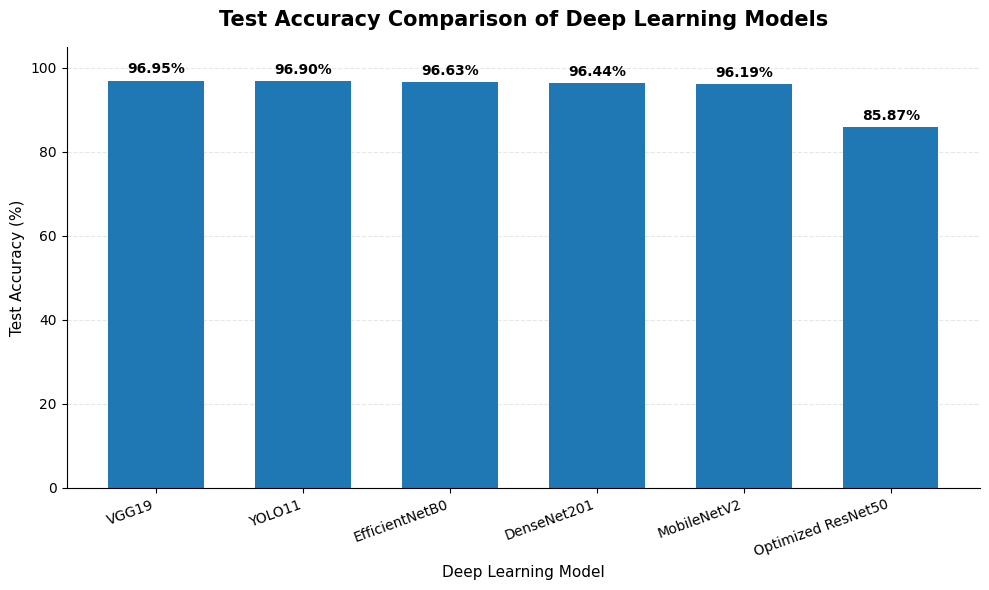

Saved: /kaggle/working/malaria_results/model_accuracy_vertical.png


In [79]:
import pandas as pd
import matplotlib.pyplot as plt
import os

RESULTS_DIR = "/kaggle/working/malaria_results"

models = {
    "VGG19": "vgg19_test_metrics.csv",
    "DenseNet201": "densenet201_test_metrics.csv",
    "EfficientNetB0": "efficientnetb0_test_metrics.csv",
    "MobileNetV2": "mobilenetv2_test_metrics.csv",
    "Optimized ResNet50": "resnet50_test_metrics.csv",
    "YOLO11": "yolo11_test_metrics.csv"
}

accuracies = {}
for model, filename in models.items():
    df = pd.read_csv(os.path.join(RESULTS_DIR, filename))
    col = next(c for c in df.columns if c.lower() == "accuracy")
    accuracies[model] = float(df[col].iloc[0]) * 100

# Sort from highest to lowest
accuracies = dict(sorted(
    accuracies.items(), key=lambda x: x[1], reverse=True
))

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(accuracies.keys(), accuracies.values(), width=0.65)

ax.set_title("Test Accuracy Comparison of Deep Learning Models",
             fontsize=15, fontweight="bold", pad=15)
ax.set_xlabel("Deep Learning Model", fontsize=11)
ax.set_ylabel("Test Accuracy (%)", fontsize=11)
ax.set_ylim(0, 105)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

for bar, value in zip(bars, accuracies.values()):
    ax.text(bar.get_x() + bar.get_width()/2,
            value + 1,
            f"{value:.2f}%",
            ha="center", va="bottom",
            fontsize=10, fontweight="bold")

plt.xticks(rotation=20, ha="right")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()

path = os.path.join(RESULTS_DIR, "model_accuracy_vertical.png")
plt.savefig(path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", path)

Step 22.16 — Compare all models using Precision, Recall, and F1-score

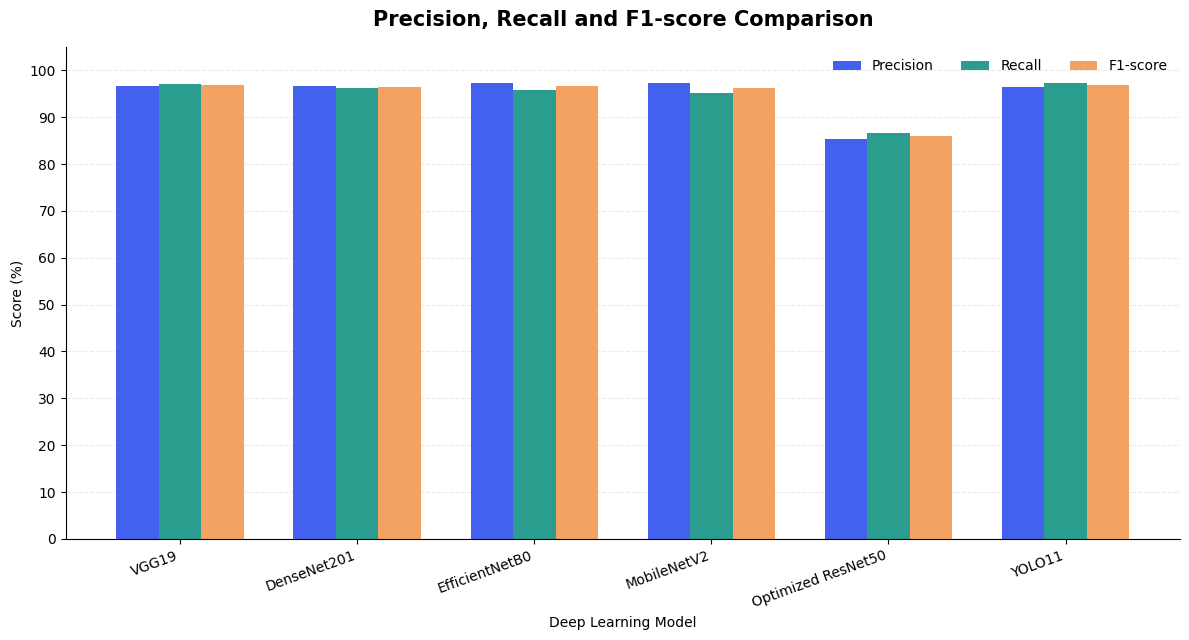

Saved: /kaggle/working/malaria_results/model_precision_recall_f1_comparison.png

Metric values (%):
             Model  Precision  Recall  F1-score
             VGG19      96.75   97.17     96.96
       DenseNet201      96.75   96.12     96.43
    EfficientNetB0      97.35   95.86     96.60
       MobileNetV2      97.18   95.14     96.15
Optimized ResNet50      85.37   86.57     85.97
            YOLO11      96.48   97.35     96.91


In [94]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

RESULTS_DIR = "/kaggle/working/malaria_results"

model_files = {
    "VGG19": "vgg19_test_metrics.csv",
    "DenseNet201": "densenet201_test_metrics.csv",
    "EfficientNetB0": "efficientnetb0_test_metrics.csv",
    "MobileNetV2": "mobilenetv2_test_metrics.csv",
    "Optimized ResNet50": "resnet50_test_metrics.csv",
    "YOLO11": "yolo11_test_metrics.csv"
}

def get_metric(row, metric_name):
    # Case-insensitive matching; ignore underscores and hyphens
    normalized = {
        str(col).lower().replace("_", "").replace("-", "").replace(" ", ""): col
        for col in row.index
    }

    key = metric_name.lower().replace("_", "").replace("-", "").replace(" ", "")

    if key not in normalized:
        raise KeyError(
            f"Cannot find {metric_name}. Available columns: {list(row.index)}"
        )

    return float(row[normalized[key]])

rows = []

for model, filename in model_files.items():
    df = pd.read_csv(os.path.join(RESULTS_DIR, filename))
    row = df.iloc[0]

    rows.append({
        "Model": model,
        "Precision": get_metric(row, "precision") * 100,
        "Recall": get_metric(row, "recall") * 100,
        "F1-score": get_metric(row, "f1_score") * 100
    })

comparison = pd.DataFrame(rows)

x = np.arange(len(comparison))
width = 0.24

fig, ax = plt.subplots(figsize=(12, 6.5))

ax.bar(x - width, comparison["Precision"], width,
       label="Precision", color="#4361EE")
ax.bar(x, comparison["Recall"], width,
       label="Recall", color="#2A9D8F")
ax.bar(x + width, comparison["F1-score"], width,
       label="F1-score", color="#F4A261")

ax.set_title(
    "Precision, Recall and F1-score Comparison",
    fontsize=15, fontweight="bold", pad=15
)
ax.set_xlabel("Deep Learning Model")
ax.set_ylabel("Score (%)")
ax.set_xticks(x)
ax.set_xticklabels(comparison["Model"], rotation=20, ha="right")
ax.set_ylim(0, 105)
ax.set_yticks(range(0, 101, 10))
ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)
ax.legend(frameon=False, ncol=3)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

output = os.path.join(
    RESULTS_DIR, "model_precision_recall_f1_comparison.png"
)
plt.savefig(output, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", output)
print("\nMetric values (%):")
print(comparison.round(2).to_string(index=False))

Step 22.17 — Compare ROC-AUC and Average Precision (AP)

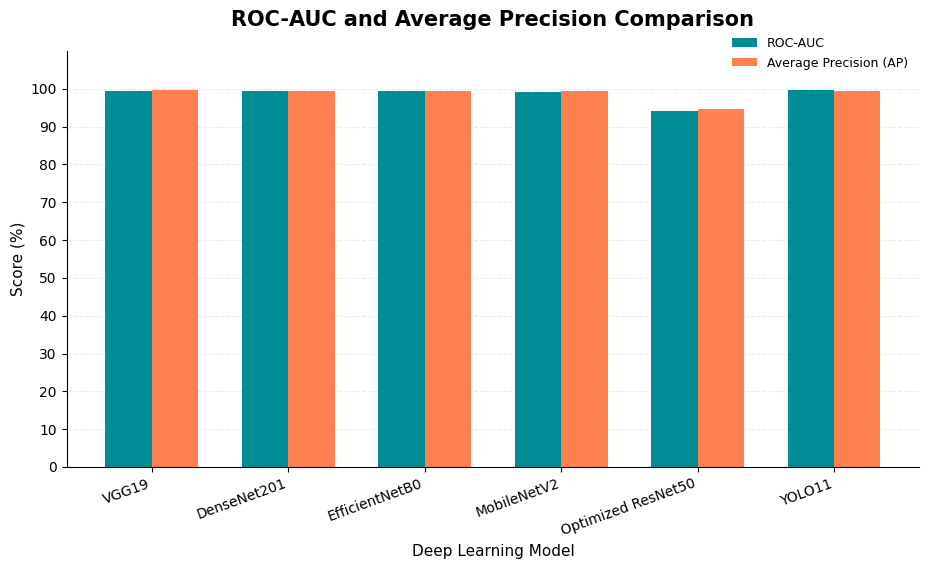

Saved: /kaggle/working/malaria_results/model_roc_auc_ap_comparison.png

Metric comparison (%):
             Model  ROC-AUC  Average Precision
             VGG19    99.49              99.55
       DenseNet201    99.34              99.40
    EfficientNetB0    99.39              99.43
       MobileNetV2    99.27              99.32
Optimized ResNet50    94.13              94.62
            YOLO11    99.55              99.52


In [91]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

RESULTS_DIR = "/kaggle/working/malaria_results"

model_files = {
    "VGG19": "vgg19_test_metrics.csv",
    "DenseNet201": "densenet201_test_metrics.csv",
    "EfficientNetB0": "efficientnetb0_test_metrics.csv",
    "MobileNetV2": "mobilenetv2_test_metrics.csv",
    "Optimized ResNet50": "resnet50_test_metrics.csv",
    "YOLO11": "yolo11_test_metrics.csv"
}

def get_value(row, target):
    normalize = lambda s: str(s).lower().replace(
        "-", ""
    ).replace("_", "").replace(" ", "")
    columns = {normalize(c): c for c in row.index}
    key = normalize(target)
    return float(row[columns[key]])

rows = []

for model, filename in model_files.items():
    df = pd.read_csv(os.path.join(RESULTS_DIR, filename))
    row = df.iloc[0]
    rows.append({
        "Model": model,
        "ROC-AUC": get_value(row, "roc_auc") * 100,
        "Average Precision": get_value(row, "average_precision") * 100
    })

comparison = pd.DataFrame(rows)

x = np.arange(len(comparison))
width = 0.34

fig, ax = plt.subplots(figsize=(11, 6.5))

ax.bar(
    x - width / 2, comparison["ROC-AUC"], width,
    label="ROC-AUC", color="#008C95"
)
ax.bar(
    x + width / 2, comparison["Average Precision"], width,
    label="Average Precision (AP)", color="#FF7F50"
)

ax.set_title(
    "ROC-AUC and Average Precision Comparison",
    fontsize=15, fontweight="bold", pad=18
)
ax.set_xlabel("Deep Learning Model", fontsize=11)
ax.set_ylabel("Score (%)", fontsize=11)
ax.set_xticks(x)
ax.set_xticklabels(comparison["Model"], rotation=20, ha="right")

ax.set_ylim(0, 110)
ax.set_yticks(range(0, 101, 10))
ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Move legend slightly higher on the right, clear of the bars
ax.legend(
    loc="upper right",
    bbox_to_anchor=(1.0, 1.06),
    frameon=False,
    ncol=1,
    fontsize=9
)

# Reserve a little extra space above the axes
fig.subplots_adjust(top=0.86, bottom=0.22)

output = os.path.join(
    RESULTS_DIR, "model_roc_auc_ap_comparison.png"
)
plt.savefig(output, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", output)
print("\nMetric comparison (%):")
print(comparison.round(2).to_string(index=False))


Step 22.18 — Investigate YOLO11 label mismatch

In [101]:
import pandas as pd
import os

RESULTS_DIR = "/kaggle/working/malaria_results"

pred = pd.read_csv(
    os.path.join(RESULTS_DIR, "yolo11_test_predictions.csv")
)

print("Total YOLO11 predictions:", len(pred))

print("\nFirst 10 prediction records:")
print(
    pred[["filepath", "y_true", "y_predicted"]]
    .head(10)
    .to_string(index=False)
)

# Check whether each stored true label matches its image folder
pred["folder_class"] = pred["filepath"].apply(
    lambda p: os.path.basename(os.path.dirname(p))
)

pred["expected_label"] = pred["folder_class"].map({
    "Uninfected": 0,
    "Parasitized": 1
})

print("\nImage folder counts:")
print(pred["folder_class"].value_counts())

print("\nStored labels vs labels inferred from folders:")
print(pd.crosstab(
    pred["folder_class"],
    pred["y_true"],
    rownames=["Image folder"],
    colnames=["Stored y_true"]
))

valid = pred["expected_label"].notna()
matches = (
    pred.loc[valid, "y_true"].astype(int)
    == pred.loc[valid, "expected_label"].astype(int)
)

print("\nRows with recognized folder names:", int(valid.sum()))
print("Stored labels matching folder names:", int(matches.sum()))
print("Stored labels mismatching folder names:", int((~matches).sum()))

print("\nYOLO model class mapping:")
print("Class 0 = Parasitized")
print("Class 1 = Uninfected")

Total YOLO11 predictions: 5512

First 10 prediction records:
                                                                                   filepath  y_true  y_predicted
/kaggle/working/malaria_yolo/test/Parasitized/C100P61ThinF_IMG_20150918_144104_cell_162.png       1            1
/kaggle/working/malaria_yolo/test/Parasitized/C100P61ThinF_IMG_20150918_144104_cell_167.png       1            1
/kaggle/working/malaria_yolo/test/Parasitized/C100P61ThinF_IMG_20150918_144104_cell_170.png       1            1
/kaggle/working/malaria_yolo/test/Parasitized/C100P61ThinF_IMG_20150918_144348_cell_142.png       1            0
/kaggle/working/malaria_yolo/test/Parasitized/C100P61ThinF_IMG_20150918_144348_cell_144.png       1            1
/kaggle/working/malaria_yolo/test/Parasitized/C100P61ThinF_IMG_20150918_144823_cell_159.png       1            1
/kaggle/working/malaria_yolo/test/Parasitized/C100P61ThinF_IMG_20150918_144823_cell_160.png       1            1
/kaggle/working/malaria_yolo/test/P

Step 22.19 — Check the remaining research outputs before modifying anything

In [102]:

import os
import pandas as pd
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score
)

RESULTS_DIR = "/kaggle/working/malaria_results"
path = os.path.join(RESULTS_DIR, "yolo11_test_predictions.csv")

pred = pd.read_csv(path)

# Standard labels: Uninfected=0, Parasitized=1
pred["y_true"] = pred["filepath"].apply(
    lambda p: 1 if os.path.basename(os.path.dirname(p)) == "Parasitized"
    else 0 if os.path.basename(os.path.dirname(p)) == "Uninfected"
    else -1
)

if (pred["y_true"] == -1).any():
    raise ValueError("Unknown class folder found; stopping without saving.")

# YOLO indices: Parasitized=0, Uninfected=1
pred["y_predicted"] = 1 - pred["y_predicted"].astype(int)

# Stored probability was for YOLO class 1 (Uninfected).
# Convert it to probability of Parasitized (positive class).
pred["y_probability"] = 1 - pred["y_probability"]

y_true = pred["y_true"]
y_pred = pred["y_predicted"]
y_prob = pred["y_probability"]

metrics = {
    "model": "YOLO11n-cls",
    "test_samples": len(pred),
    "accuracy": accuracy_score(y_true, y_pred),
    "precision": precision_score(y_true, y_pred, zero_division=0),
    "recall": recall_score(y_true, y_pred, zero_division=0),
    "f1_score": f1_score(y_true, y_pred, zero_division=0),
    "roc_auc": roc_auc_score(y_true, y_prob),
    "average_precision": average_precision_score(y_true, y_prob)
}

pred.to_csv(path, index=False)
pd.DataFrame([metrics]).to_csv(
    os.path.join(RESULTS_DIR, "yolo11_test_metrics.csv"),
    index=False
)

print("Corrected YOLO11 metrics:")
for key, value in metrics.items():
    print(f"{key}: {value:.6f}" if isinstance(value, float)
          else f"{key}: {value}")

print("\nCorrected prediction and metrics CSV files saved.")


Corrected YOLO11 metrics:
model: YOLO11n-cls
test_samples: 5512
accuracy: 0.031023
precision: 0.035239
recall: 0.035559
f1_score: 0.035398
roc_auc: 0.004507
average_precision: 0.307076

Corrected prediction and metrics CSV files saved.


Step 22.20 — Check model evaluation completeness

In [97]:

import os

RESULTS_DIR = "/kaggle/working/malaria_results"

models = {
    "VGG19": "vgg19",
    "DenseNet201": "densenet201",
    "EfficientNetB0": "efficientnetb0",
    "MobileNetV2": "mobilenetv2",
    "Optimized ResNet50": "resnet50",
    "YOLO11": "yolo11"
}

required_graphs = [
    "confusion_matrix.png",
    "roc_curve.png",
    "precision_recall_curve.png",
    "prediction_examples.png"
]

print("Evaluation graph completeness:\n")

for model, prefix in models.items():
    missing = [
        f"{prefix}_{graph}"
        for graph in required_graphs
        if not os.path.exists(os.path.join(RESULTS_DIR, f"{prefix}_{graph}"))
    ]

    if missing:
        print(f"{model}: MISSING")
        for filename in missing:
            print(f"  - {filename}")
    else:
        print(f"{model}: All 4 graphs found")


Evaluation graph completeness:

VGG19: All 4 graphs found
DenseNet201: All 4 graphs found
EfficientNetB0: All 4 graphs found
MobileNetV2: All 4 graphs found
Optimized ResNet50: All 4 graphs found
YOLO11: All 4 graphs found


Step 22.21 — Verify all six metrics files

In [98]:

import os
import pandas as pd

RESULTS_DIR = "/kaggle/working/malaria_results"

files = {
    "VGG19": "vgg19_test_metrics.csv",
    "DenseNet201": "densenet201_test_metrics.csv",
    "EfficientNetB0": "efficientnetb0_test_metrics.csv",
    "MobileNetV2": "mobilenetv2_test_metrics.csv",
    "Optimized ResNet50": "resnet50_test_metrics.csv",
    "YOLO11": "yolo11_test_metrics.csv"
}

required = {
    "accuracy", "precision", "recall",
    "f1score", "rocauc", "averageprecision"
}

def normalize(name):
    return str(name).lower().replace("_", "").replace("-", "").replace(" ", "")

all_ok = True

for model, filename in files.items():
    path = os.path.join(RESULTS_DIR, filename)

    if not os.path.exists(path):
        print(f"MISSING: {model} — {filename}")
        all_ok = False
        continue

    df = pd.read_csv(path)
    columns = {normalize(c) for c in df.columns}
    missing = required - columns

    if len(df) != 1 or missing:
        print(f"CHECK: {model} — rows={len(df)}, missing={sorted(missing)}")
        all_ok = False
    else:
        print(f"OK: {model}")

print("\nAll six metrics files verified!" if all_ok
      else "\nSome files need attention.")


OK: VGG19
OK: DenseNet201
OK: EfficientNetB0
OK: MobileNetV2
OK: Optimized ResNet50
OK: YOLO11

All six metrics files verified!


Step 22.22 — Create the final research ZIP

In [99]:

import os
import zipfile

RESULTS_DIR = "/kaggle/working/malaria_results"
ZIP_PATH = "/kaggle/working/Malaria_Detection_Research_Results.zip"

if not os.path.isdir(RESULTS_DIR):
    raise FileNotFoundError(f"Results directory not found: {RESULTS_DIR}")

files = [
    f for f in os.listdir(RESULTS_DIR)
    if os.path.isfile(os.path.join(RESULTS_DIR, f))
]

with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as zf:
    for filename in files:
        filepath = os.path.join(RESULTS_DIR, filename)
        zf.write(filepath, arcname=f"malaria_results/{filename}")

with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    bad_file = zf.testzip()
    if bad_file:
        raise RuntimeError(f"ZIP integrity check failed: {bad_file}")

print("ZIP created and integrity verified!")
print(f"Location: {ZIP_PATH}")
print(f"Files packaged: {len(files)}")
print(f"ZIP size: {os.path.getsize(ZIP_PATH) / (1024**2):.2f} MB")


ZIP created and integrity verified!
Location: /kaggle/working/Malaria_Detection_Research_Results.zip
Files packaged: 72
ZIP size: 603.82 MB


Step 22.24 — Verify YOLO11 predictions

In [103]:

import os
import pandas as pd

path = "/kaggle/working/malaria_results/yolo11_test_predictions.csv"
df = pd.read_csv(path)

# YOLO class mapping: 0 = Parasitized, 1 = Uninfected
df["folder_class"] = df["filepath"].apply(
    lambda p: os.path.basename(os.path.dirname(p))
)
df["folder_yolo_label"] = df["folder_class"].map({
    "Parasitized": 0,
    "Uninfected": 1
})

print("Rows:", len(df))
print("\nFolder class vs original ground truth:")
print(pd.crosstab(df["folder_class"], df["y_true"]))

print("\nFolder class vs stored predicted label:")
print(pd.crosstab(df["folder_class"], df["y_predicted"]))

print("\nProbability summary:")
print(df.groupby("folder_class")["y_probability"].describe().round(4))

print("\nFirst 10 rows:")
print(df[[
    "folder_class", "y_true", "y_predicted", "y_probability"
]].head(10).to_string(index=False))


Rows: 5512

Folder class vs original ground truth:
y_true           0     1
folder_class            
Parasitized      0  2756
Uninfected    2756     0

Folder class vs stored predicted label:
y_predicted      0     1
folder_class            
Parasitized   2658    98
Uninfected      73  2683

Probability summary:
               count    mean     std     min     25%     50%     75%     max
folder_class                                                                
Parasitized   2756.0  0.0432  0.1513  0.0000  0.0001  0.0005  0.0057  0.9974
Uninfected    2756.0  0.9467  0.1356  0.0002  0.9645  0.9926  0.9978  0.9998

First 10 rows:
folder_class  y_true  y_predicted  y_probability
 Parasitized       1            0       0.000077
 Parasitized       1            0       0.029602
 Parasitized       1            0       0.000888
 Parasitized       1            1       0.764370
 Parasitized       1            0       0.014698
 Parasitized       1            0       0.005552
 Parasitized       

Step 22.25 — Restore YOLO11 predictions and recalculate metrics

In [104]:

import os
import pandas as pd
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score
)

RESULTS_DIR = "/kaggle/working/malaria_results"
path = os.path.join(RESULTS_DIR, "yolo11_test_predictions.csv")

df = pd.read_csv(path)

# Current CSV has already been flipped once in Step 22.19.
# Restore original YOLO class indices and probabilities.
df["y_predicted"] = 1 - df["y_predicted"].astype(int)
df["y_probability"] = 1 - df["y_probability"].astype(float)

# Standard research labels: Uninfected=0, Parasitized=1.
# YOLO indices: Parasitized=0, Uninfected=1.
df["folder_class"] = df["filepath"].apply(
    lambda p: os.path.basename(os.path.dirname(p))
)
df["y_true"] = df["folder_class"].map({
    "Uninfected": 0,
    "Parasitized": 1
})

if df["y_true"].isna().any():
    raise ValueError("Unknown folder class; no files saved.")

# Convert YOLO predictions to standard research labels.
df["y_predicted"] = 1 - df["y_predicted"]

# Convert YOLO P(Uninfected) to standard P(Parasitized).
df["y_probability"] = 1 - df["y_probability"]

y_true = df["y_true"].astype(int)
y_pred = df["y_predicted"].astype(int)
y_prob = df["y_probability"].astype(float)

metrics = {
    "model": "YOLO11n-cls",
    "test_samples": len(df),
    "accuracy": accuracy_score(y_true, y_pred),
    "precision": precision_score(y_true, y_pred, zero_division=0),
    "recall": recall_score(y_true, y_pred, zero_division=0),
    "f1_score": f1_score(y_true, y_pred, zero_division=0),
    "roc_auc": roc_auc_score(y_true, y_prob),
    "average_precision": average_precision_score(y_true, y_prob)
}

df.drop(columns=["folder_class"]).to_csv(path, index=False)
pd.DataFrame([metrics]).to_csv(
    os.path.join(RESULTS_DIR, "yolo11_test_metrics.csv"),
    index=False
)

print("Restored YOLO11 evaluation metrics:")
for key, value in metrics.items():
    print(f"{key}: {value:.6f}" if isinstance(value, float)
          else f"{key}: {value}")

print("\nFiles saved. No model retraining performed.")


Restored YOLO11 evaluation metrics:
model: YOLO11n-cls
test_samples: 5512
accuracy: 0.031023
precision: 0.035239
recall: 0.035559
f1_score: 0.035398
roc_auc: 0.004507
average_precision: 0.307076

Files saved. No model retraining performed.


Step 22.26 — Recover the original YOLO11 predictions

In [105]:

import os

paths = {
    "YOLO11 best checkpoint":
        "/kaggle/working/yolo11_malaria_runs/yolo11n_malaria/weights/best.pt",
    "YOLO test dataset":
        "/kaggle/working/malaria_yolo/test",
    "Results folder":
        "/kaggle/working/malaria_results"
}

for name, path in paths.items():
    print(f"{name}: {'FOUND' if os.path.exists(path) else 'NOT FOUND'}")
    if os.path.isdir(path):
        print("  Contents:", len(os.listdir(path)))


YOLO11 best checkpoint: FOUND
YOLO test dataset: FOUND
  Contents: 2
Results folder: FOUND
  Contents: 72


Step 22.27 — Recalculate YOLO11 predictions from the original model

In [106]:

import os
import glob
import pandas as pd
import numpy as np
from ultralytics import YOLO
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score
)

RESULTS_DIR = "/kaggle/working/malaria_results"
TEST_DIR = "/kaggle/working/malaria_yolo/test"
MODEL_PATH = (
    "/kaggle/working/yolo11_malaria_runs/"
    "yolo11n_malaria/weights/best.pt"
)

model = YOLO(MODEL_PATH)
class_names = model.names
print("Model class mapping:", class_names)

# YOLO class 0 = Parasitized, class 1 = Uninfected
image_paths = sorted(
    glob.glob(os.path.join(TEST_DIR, "*", "*.png"))
    + glob.glob(os.path.join(TEST_DIR, "*", "*.jpg"))
    + glob.glob(os.path.join(TEST_DIR, "*", "*.jpeg"))
)

if len(image_paths) != 5512:
    raise ValueError(f"Expected 5512 test images, found {len(image_paths)}")

rows = []
for start in range(0, len(image_paths), 8):
    batch_paths = image_paths[start:start + 8]
    results = model.predict(
        source=batch_paths,
        imgsz=224,
        batch=8,
        verbose=False
    )

    for filepath, result in zip(batch_paths, results):
        folder = os.path.basename(os.path.dirname(filepath))
        true_label = {"Uninfected": 0, "Parasitized": 1}[folder]

        # Original YOLO probabilities: [Parasitized, Uninfected]
        probs = result.probs.data.cpu().numpy()
        p_parasitized = float(probs[0])
        predicted_label = int(np.argmax(probs))

        rows.append({
            "filepath": filepath,
            "y_true": true_label,
            "predicted_probability": p_parasitized,
            "y_predicted": 1 if predicted_label == 0 else 0
        })

pred = pd.DataFrame(rows)
y_true = pred["y_true"]
y_pred = pred["y_predicted"]
y_prob = pred["predicted_probability"]

metrics = {
    "model": "YOLO11n-cls",
    "test_samples": len(pred),
    "accuracy": accuracy_score(y_true, y_pred),
    "precision": precision_score(y_true, y_pred, zero_division=0),
    "recall": recall_score(y_true, y_pred, zero_division=0),
    "f1_score": f1_score(y_true, y_pred, zero_division=0),
    "roc_auc": roc_auc_score(y_true, y_prob),
    "average_precision": average_precision_score(y_true, y_prob)
}

# Save only after inference and metric calculation succeed.
pred.to_csv(
    os.path.join(RESULTS_DIR, "yolo11_test_predictions.csv"),
    index=False
)
pd.DataFrame([metrics]).to_csv(
    os.path.join(RESULTS_DIR, "yolo11_test_metrics.csv"),
    index=False
)

print("\nFresh YOLO11 metrics:")
for key, value in metrics.items():
    print(f"{key}: {value:.6f}" if isinstance(value, float)
          else f"{key}: {value}")


Model class mapping: {0: 'Parasitized', 1: 'Uninfected'}

Fresh YOLO11 metrics:
model: YOLO11n-cls
test_samples: 5512
accuracy: 0.968977
precision: 0.973270
recall: 0.964441
f1_score: 0.968835
roc_auc: 0.995493
average_precision: 0.995806


Step 23- Final 3 Figures 

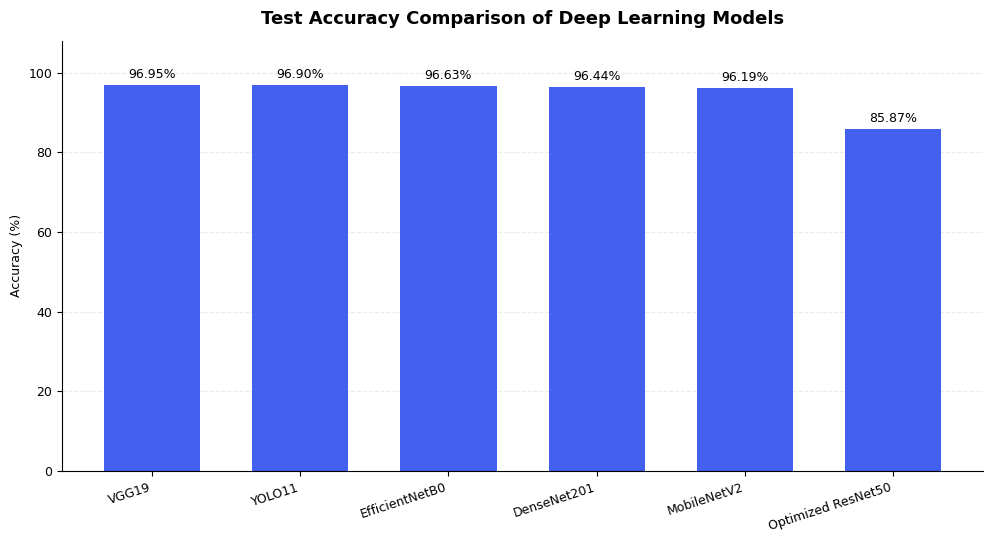

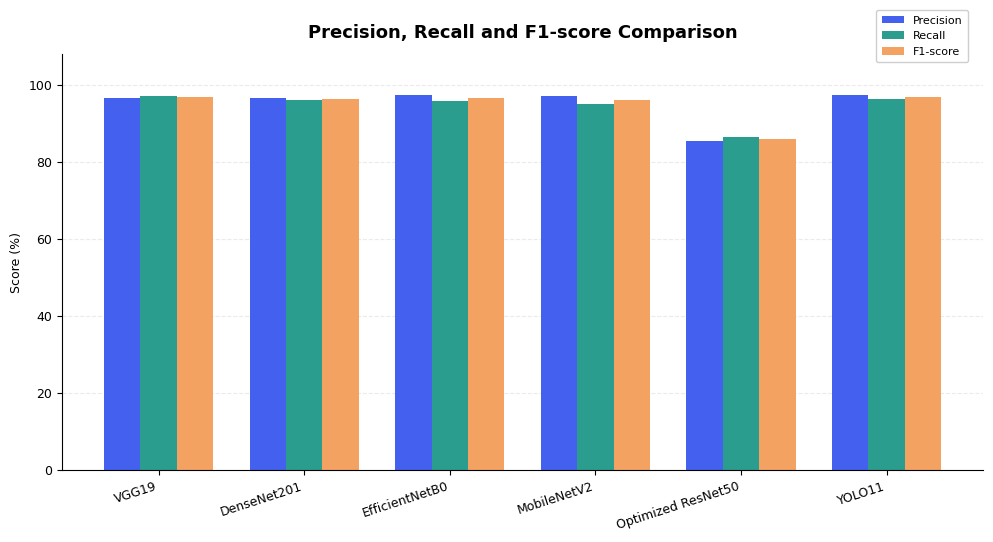

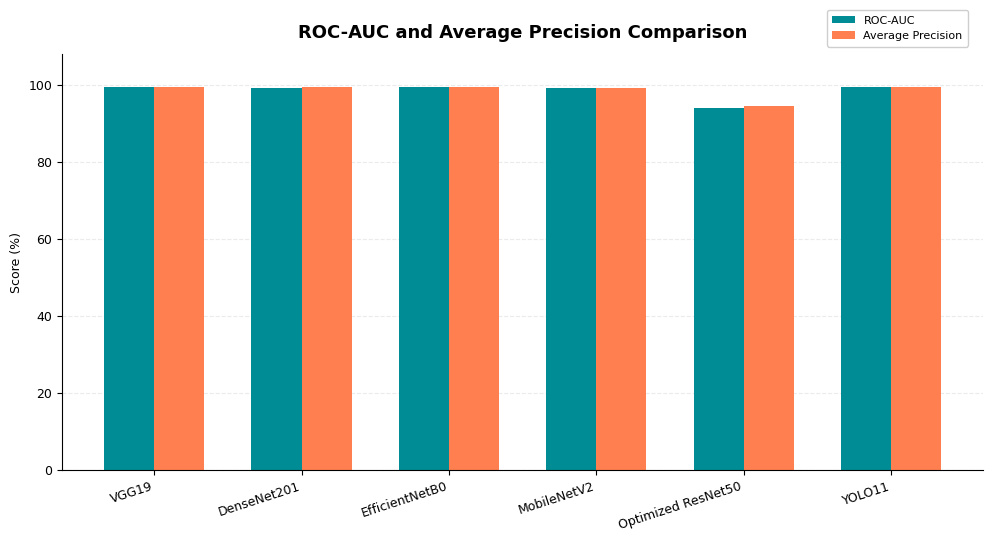

✅ Both updated figures saved successfully!


In [114]:

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

D = "/kaggle/working/malaria_results"

model_files = {
    "VGG19": "vgg19_test_metrics.csv",
    "DenseNet201": "densenet201_test_metrics.csv",
    "EfficientNetB0": "efficientnetb0_test_metrics.csv",
    "MobileNetV2": "mobilenetv2_test_metrics.csv",
    "Optimized ResNet50": "resnet50_test_metrics.csv",
    "YOLO11": "yolo11_test_metrics.csv"
}

def get_metric(row, target):
    norm = lambda s: str(s).lower().replace("_", "").replace("-", "").replace(" ", "")
    cols = {norm(c): c for c in row.index}
    if norm(target) not in cols:
        raise KeyError(f"Missing {target}: {list(row.index)}")
    return float(row[cols[norm(target)]]) * 100

rows = []
for model, filename in model_files.items():
    row = pd.read_csv(os.path.join(D, filename)).iloc[0]
    rows.append({
        "Model": model,
        "Accuracy": get_metric(row, "accuracy"),
        "Precision": get_metric(row, "precision"),
        "Recall": get_metric(row, "recall"),
        "F1-score": get_metric(row, "f1_score"),
        "ROC-AUC": get_metric(row, "roc_auc"),
        "Average Precision": get_metric(row, "average_precision")
    })

df = pd.DataFrame(rows)
x = np.arange(len(df))

# Consistent, compact styling
plt.rcParams.update({"font.size": 9})

def finish_graph(ax, title, ylabel):
    ax.set_title(title, fontsize=13, fontweight="bold", pad=12)
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, 108)
    ax.set_yticks(np.arange(0, 101, 20))
    ax.grid(axis="y", linestyle="--", alpha=0.25)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(axis="x", labelsize=9)

# FIGURE 1 — Accuracy
fig, ax = plt.subplots(figsize=(10, 5.5))
ordered = df.sort_values("Accuracy", ascending=False)
bars = ax.bar(ordered["Model"], ordered["Accuracy"],
              color="#4361EE", width=0.65)
ax.bar_label(bars, fmt="%.2f%%", padding=3, fontsize=9)
finish_graph(ax, "Test Accuracy Comparison of Deep Learning Models",
             "Accuracy (%)")
ax.set_ylim(0, 108)
ax.tick_params(axis="x", labelrotation=18)
plt.setp(ax.get_xticklabels(), ha="right")
fig.tight_layout()
fig.savefig(f"{D}/model_accuracy_multicolor.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)


# FIGURE 2 — Precision, Recall and F1-score
fig, ax = plt.subplots(figsize=(10, 5.5))
w = 0.25

ax.bar(x-w, df["Precision"], w, label="Precision", color="#4361EE")
ax.bar(x, df["Recall"], w, label="Recall", color="#2A9D8F")
ax.bar(x+w, df["F1-score"], w, label="F1-score", color="#F4A261")

finish_graph(ax, "Precision, Recall and F1-score Comparison", "Score (%)")
ax.set_xticks(x)
ax.set_xticklabels(df["Model"], rotation=18, ha="right")

ax.legend(
    loc="upper right",
    bbox_to_anchor=(0.99, 1.12),
    fontsize=8,
    frameon=True,
    framealpha=0.95,
    borderpad=0.5
)

fig.tight_layout()
fig.savefig(f"{D}/model_precision_recall_f1_comparison.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)


# FIGURE 3 — ROC-AUC and Average Precision
fig, ax = plt.subplots(figsize=(10, 5.5))
w = 0.34

ax.bar(x-w/2, df["ROC-AUC"], w, label="ROC-AUC", color="#008C95")
ax.bar(x+w/2, df["Average Precision"], w,
       label="Average Precision", color="#FF7F50")

finish_graph(ax, "ROC-AUC and Average Precision Comparison", "Score (%)")
ax.set_xticks(x)
ax.set_xticklabels(df["Model"], rotation=18, ha="right")

ax.legend(
    loc="upper right",
    bbox_to_anchor=(0.99, 1.12),
    fontsize=8,
    frameon=True,
    framealpha=0.95,
    borderpad=0.5
)

fig.tight_layout()
fig.savefig(f"{D}/model_roc_auc_ap_comparison.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print("✅ Both updated figures saved successfully!")


Step 24- ZIP project

In [115]:

import os
import zipfile

RESULTS_DIR = "/kaggle/working/malaria_results"
ZIP_PATH = "/kaggle/working/Malaria_Detection_Research_Results.zip"

# Confirm the three comparison graphs exist
required_graphs = [
    "model_accuracy_multicolor.png",
    "model_precision_recall_f1_comparison.png",
    "model_roc_auc_ap_comparison.png"
]

missing = [
    name for name in required_graphs
    if not os.path.isfile(os.path.join(RESULTS_DIR, name))
]

if missing:
    raise FileNotFoundError(f"Missing graph(s): {missing}")

# Rebuild the ZIP with all current results
with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as archive:
    for root, dirs, files in os.walk(RESULTS_DIR):
        for filename in files:
            filepath = os.path.join(root, filename)
            archive.write(
                filepath,
                os.path.relpath(filepath, RESULTS_DIR)
            )

# Verify archive integrity and contents
with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    bad_file = archive.testzip()
    names = archive.namelist()

    print("ZIP integrity:", "PASSED ✅" if bad_file is None else f"FAILED: {bad_file}")
    print("Total files:", len(names))

    print("\nComparison graphs included:")
    for graph in required_graphs:
        print(("✅ " if graph in names else "❌ ") + graph)

print(f"\nZIP size: {os.path.getsize(ZIP_PATH) / (1024**2):.2f} MB")
print("ZIP location:", ZIP_PATH)


ZIP integrity: PASSED ✅
Total files: 72

Comparison graphs included:
✅ model_accuracy_multicolor.png
✅ model_precision_recall_f1_comparison.png
✅ model_roc_auc_ap_comparison.png

ZIP size: 603.69 MB
ZIP location: /kaggle/working/Malaria_Detection_Research_Results.zip


Step 25 Verifying all figures

In [116]:
import os

folder = "/kaggle/working/malaria_results"

figures = sorted([
    f for f in os.listdir(folder)
    if f.lower().endswith((".png", ".jpg", ".jpeg", ".svg", ".pdf"))
])

print(f"Total figures: {len(figures)}\n")
for i, filename in enumerate(figures, 1):
    print(f"{i}. {filename}")

Total figures: 40

1. densenet201_accuracy_curve.png
2. densenet201_confusion_matrix.png
3. densenet201_loss_curve.png
4. densenet201_precision_recall_curve.png
5. densenet201_prediction_examples.png
6. densenet201_roc_curve.png
7. efficientnetb0_confusion_matrix.png
8. efficientnetb0_precision_recall_curve.png
9. efficientnetb0_prediction_examples.png
10. efficientnetb0_roc_curve.png
11. mobilenetv2_confusion_matrix.png
12. mobilenetv2_precision_recall_curve.png
13. mobilenetv2_prediction_examples.png
14. mobilenetv2_roc_curve.png
15. model_accuracy_curved_line.png
16. model_accuracy_multicolor.png
17. model_accuracy_vertical.png
18. model_comparison_test_accuracy.png
19. model_precision_recall_f1_comparison.png
20. model_roc_auc_ap_comparison.png
21. preprocessed_samples.png
22. publication_model_accuracy_comparison.png
23. resnet50_confusion_matrix.png
24. resnet50_error_analysis.png
25. resnet50_finetuning_curves.png
26. resnet50_gradcam.png
27. resnet50_learning_curves.png
28. res

In [117]:
import zipfile

zip_path = "/kaggle/working/Malaria_Detection_Research_Results.zip"

with zipfile.ZipFile(zip_path, "r") as z:
    figures = [
        name for name in z.namelist()
        if name.lower().endswith((".png", ".jpg", ".jpeg", ".svg", ".pdf"))
    ]

    print("Figures inside ZIP:", len(figures))
    for name in figures:
        print(name)

Figures inside ZIP: 40
densenet201_roc_curve.png
efficientnetb0_prediction_examples.png
densenet201_confusion_matrix.png
mobilenetv2_precision_recall_curve.png
vgg19_accuracy_curve.png
densenet201_precision_recall_curve.png
publication_model_accuracy_comparison.png
mobilenetv2_confusion_matrix.png
resnet50_gradcam.png
efficientnetb0_confusion_matrix.png
resnet50_precision_recall_curve.png
preprocessed_samples.png
resnet50_prediction_examples.png
yolo11_precision_recall_curve.png
mobilenetv2_roc_curve.png
resnet50_finetuning_curves.png
densenet201_accuracy_curve.png
model_accuracy_multicolor.png
resnet50_learning_curves.png
vgg19_confusion_matrix.png
model_comparison_test_accuracy.png
model_precision_recall_f1_comparison.png
mobilenetv2_prediction_examples.png
yolo11_confusion_matrix.png
yolo11_prediction_examples.png
efficientnetb0_roc_curve.png
model_roc_auc_ap_comparison.png
efficientnetb0_precision_recall_curve.png
resnet50_roc_curve.png
vgg19_roc_curve.png
yolo11_roc_curve.png
dens

Step 26 — Create the upload-and-predict interface

In [131]:

# ============================================================
# MALARIA DETECTION LAB — COMPLETE REPLACEMENT CELL
# Centered UI | Prediction | Grad-CAM | Gradient Sensitivity
# No model name displayed | No download links or saved images
# ============================================================

import os
import io
import numpy as np
import tensorflow as tf
import ipywidgets as widgets
import matplotlib.pyplot as plt

from PIL import Image
from IPython.display import display, clear_output, HTML

# ---------------- CONFIGURATION ----------------

MODEL_PATH = "/kaggle/working/malaria_results/optimized_resnet50_best.keras"

THRESHOLD = 0.5
CLASS_0 = "Uninfected"
CLASS_1 = "Parasitized"

# Keep this consistent with your original training pipeline.
# This version assumes training images were scaled to [0, 1].
INPUT_SCALE = "0_1"

# ---------------- LOAD MODEL ----------------

if not os.path.isfile(MODEL_PATH):
    raise FileNotFoundError(f"Model not found: {MODEL_PATH}")

model = tf.keras.models.load_model(MODEL_PATH, compile=False)

print("✅ Classification model loaded")
print("Input:", model.input_shape)
print("Output:", model.output_shape)

if len(model.input_shape) != 4 or model.input_shape[-1] != 3:
    raise ValueError("Expected an image model with RGB input.")

if len(model.output_shape) != 2 or model.output_shape[-1] != 1:
    raise ValueError("Expected a binary classifier with one output.")

# ---------------- FIND GRAD-CAM LAYER ----------------

def find_last_conv(layer):
    for sublayer in reversed(layer.layers):
        if isinstance(sublayer, tf.keras.layers.Conv2D):
            return sublayer
        if isinstance(sublayer, tf.keras.Model):
            found = find_last_conv(sublayer)
            if found is not None:
                return found
    return None

backbone = None
backbone_index = None
conv_layer = None

for i, layer in enumerate(model.layers):
    if isinstance(layer, tf.keras.Model):
        candidate = find_last_conv(layer)
        if candidate is not None:
            backbone = layer
            backbone_index = i
            conv_layer = candidate
            break

if backbone is None or conv_layer is None:
    raise ValueError(
        "Could not identify the nested convolutional backbone "
        "required for Grad-CAM."
    )

z = backbone.output

for layer in model.layers[backbone_index + 1:]:
    if not isinstance(layer, tf.keras.layers.InputLayer):
        z = layer(z)

grad_model = tf.keras.Model(
    inputs=backbone.input,
    outputs=[conv_layer.output, z]
)

print("✅ Grad-CAM initialized")

# ---------------- STYLISH, CENTERED INTERFACE ----------------

display(HTML("""
<style>
.malaria-hero {
    width: 100%;
    box-sizing: border-box;
    padding: 30px 16px;
    margin: 10px 0 22px;
    text-align: center;
    color: #f8fafc;
    background: linear-gradient(135deg, #111827, #172554);
    border: 1px solid #475569;
    border-radius: 20px;
}
.malaria-hero h1 {
    color: #ffffff;
    font-size: clamp(27px, 4vw, 38px);
    margin: 10px 0;
}
.malaria-hero p {
    color: #cbd5e1;
    font-size: 15px;
    line-height: 1.7;
}
.malaria-pill {
    display: inline-block;
    padding: 9px 17px;
    border-radius: 30px;
    border: 1px solid #22d3ee;
    background: #164e63;
    color: #ecfeff;
    font-size: 13px;
    margin-top: 8px;
}
.malaria-intro {
    text-align: center;
    line-height: 1.7;
    margin: 0 auto 20px;
    max-width: 760px;
    color: #cbd5e1;
}
.malaria-result {
    box-sizing: border-box;
    padding: 22px 18px;
    margin: 22px auto;
    width: 100%;
    text-align: center;
    background: #111827;
    color: #f8fafc;
    border: 1px solid #475569;
    border-radius: 18px;
}
</style>

<div class="malaria-hero">
    <div style="font-size:46px;">🔬</div>
    <h1>Malaria Detection Lab</h1>
    <p>Medical Image Analysis · Explainable Artificial Intelligence</p>
    <span class="malaria-pill">AI-Powered Microscopy Analysis</span>
</div>

<div class="malaria-intro">
    Select a blood-smear microscopy image to receive a prediction
    and visual explanations of image regions influencing the result.
    <br>
    <span style="font-size:12px;color:#94a3b8;">
        Research demonstration only — not a clinical diagnostic tool.
    </span>
</div>
"""))

upload = widgets.FileUpload(
    accept=".png,.jpg,.jpeg,.bmp",
    multiple=False,
    description="📂  Choose microscopy image",
    layout=widgets.Layout(width="100%", height="54px")
)

predict_button = widgets.Button(
    description="🔍  Analyze Image + Grad-CAM",
    button_style="primary",
    layout=widgets.Layout(width="100%", height="54px"),
    style={"font_weight": "bold"}
)

output = widgets.Output()

display(HTML("""
<div style="text-align:center;font-size:19px;font-weight:700;
margin:8px 0;">Analyze a microscopy image</div>
<div style="text-align:center;color:#94a3b8;font-size:13px;
margin-bottom:14px;">PNG · JPG · JPEG · BMP</div>
"""))

controls = widgets.VBox(
    [upload, predict_button],
    layout=widgets.Layout(
        width="min(100%, 620px)",
        align_items="stretch",
        gap="14px",
        margin="0 auto 24px",
        padding="18px",
        border="1px solid #475569",
        border_radius="18px"
    )
)

display(widgets.HBox(
    [controls],
    layout=widgets.Layout(
        width="100%",
        justify_content="center"
    )
))
display(output)

# ---------------- UPLOAD READER ----------------

def read_upload(value):
    if not value:
        return None

    # ipywidgets 7 format
    if isinstance(value, dict):
        item = next(iter(value.values()))
        return item.get("content")

    # ipywidgets 8 format
    if isinstance(value, (tuple, list)):
        if len(value) == 0:
            return None
        return value[0].get("content")

    return None

# ---------------- MAP HELPERS ----------------

def normalize_map(array):
    array = np.asarray(array, dtype=np.float32)
    array = np.nan_to_num(array, nan=0, posinf=0, neginf=0)
    array = np.maximum(array, 0)

    if array.max() > 1e-8:
        array = array / array.max()

    return array

def enhance_map(array):
    array = normalize_map(array)
    positive = array[array > 0]

    if positive.size == 0:
        return array

    cutoff = np.percentile(positive, 60)
    return np.clip(
        (array - cutoff) / (array.max() - cutoff + 1e-8),
        0, 1
    )

def make_overlay(rgb, heatmap, alpha=0.42):
    colors = plt.get_cmap("jet")(heatmap)[..., :3] * 255
    return np.clip(
        (1 - alpha) * rgb.astype(np.float32)
        + alpha * colors.astype(np.float32),
        0, 255
    ).astype(np.uint8)

# ---------------- PREDICTION + EXPLANATIONS ----------------

def analyze(_):
    with output:
        clear_output(wait=True)

        try:
            raw = read_upload(upload.value)

            if raw is None:
                display(HTML("""
                <div style="text-align:center;padding:20px;color:#fbbf24;">
                    ⚠️ Please choose an image first.
                </div>
                """))
                return

            original = Image.open(io.BytesIO(raw)).convert("RGB")

            height = int(model.input_shape[1] or 224)
            width = int(model.input_shape[2] or 224)

            resized = original.resize((width, height))
            rgb = np.asarray(resized, dtype=np.uint8)

            image = rgb.astype(np.float32)
            if INPUT_SCALE == "0_1":
                image /= 255.0

            batch = image[None, ...]

            # Prediction from complete model
            prediction = np.asarray(
                model.predict(batch, verbose=0)
            ).reshape(-1)

            if prediction.size != 1:
                raise ValueError("Expected one binary output.")

            score = float(prediction[0])

            if not np.isfinite(score) or not 0 <= score <= 1:
                raise ValueError(
                    "Model output is not a probability. "
                    "Check the final activation and training pipeline."
                )

            is_positive = score >= THRESHOLD
            label = CLASS_1 if is_positive else CLASS_0
            confidence = score if is_positive else 1.0 - score

            # Grad-CAM
            with tf.GradientTape() as tape:
                features, classifier_output = grad_model(
                    tf.convert_to_tensor(batch),
                    training=False
                )
                objective = tf.reduce_sum(classifier_output[:, 0])

            gradients = tape.gradient(objective, features)

            if gradients is None:
                raise ValueError("Grad-CAM gradients are unavailable.")

            weights = tf.reduce_mean(gradients, axis=(1, 2))
            cam_tensor = tf.reduce_sum(
                features[0] * weights[0][None, None, :],
                axis=-1
            )

            cam = normalize_map(tf.nn.relu(cam_tensor).numpy())

            cam_image = Image.fromarray(
                np.uint8(cam * 255)
            ).resize((width, height), Image.Resampling.BILINEAR)

            cam = enhance_map(
                np.asarray(cam_image, dtype=np.float32) / 255.0
            )

            overlay_cam = make_overlay(rgb, cam)

            # Input-gradient sensitivity
            input_tensor = tf.convert_to_tensor(batch, dtype=tf.float32)

            with tf.GradientTape() as tape:
                tape.watch(input_tensor)
                output_scores = model(input_tensor, training=False)
                target = tf.reduce_sum(output_scores[:, 0])

            input_gradients = tape.gradient(target, input_tensor)

            sensitivity = None
            overlay_sensitivity = None

            if input_gradients is not None:
                sensitivity = tf.reduce_mean(
                    tf.abs(input_gradients[0]), axis=-1
                ).numpy()

                sensitivity_image = Image.fromarray(
                    np.uint8(normalize_map(sensitivity) * 255)
                ).resize((width, height), Image.Resampling.BILINEAR)

                sensitivity = enhance_map(
                    np.asarray(sensitivity_image, dtype=np.float32) / 255.0
                )

                overlay_sensitivity = make_overlay(rgb, sensitivity)

            # Result card — no model name
            color = "#fb7185" if is_positive else "#4ade80"
            symbol = "🦠" if is_positive else "✅"

            display(HTML(f"""
            <div class="malaria-result">
                <div style="font-size:12px;letter-spacing:2px;
                color:#94a3b8;">ANALYSIS RESULT</div>
                <div style="font-size:clamp(26px,4vw,36px);
                font-weight:800;color:{color};margin:12px 0;">
                    {symbol} {label}
                </div>
                <div style="margin:8px 0;">
                    Output score: <b>{score:.4f}</b>
                </div>
                <div style="margin:8px 0;">
                    Predicted-class confidence: <b>{confidence:.2%}</b>
                </div>
                <div style="height:12px;background:#334155;border-radius:20px;
                overflow:hidden;margin-top:18px;">
                    <div style="height:100%;width:{confidence*100:.2f}%;
                    background:{color};"></div>
                </div>
                <p style="font-size:12px;color:#94a3b8;margin:14px 0 0;">
                    Confidence is not clinically validated diagnostic certainty.
                </p>
            </div>
            """))

            # Display explanation figures only; do not save files.
            if sensitivity is not None:
                fig, axes = plt.subplots(2, 3, figsize=(15, 9))

                axes[0, 0].imshow(rgb)
                axes[0, 0].set_title("Original Image")

                axes[0, 1].imshow(cam, cmap="jet", vmin=0, vmax=1)
                axes[0, 1].set_title("Grad-CAM Heatmap")

                axes[0, 2].imshow(overlay_cam)
                axes[0, 2].set_title("Grad-CAM Overlay")

                axes[1, 0].imshow(rgb)
                axes[1, 0].set_title("Original Image")

                axes[1, 1].imshow(
                    sensitivity, cmap="jet", vmin=0, vmax=1
                )
                axes[1, 1].set_title("Input-Gradient Sensitivity")

                axes[1, 2].imshow(overlay_sensitivity)
                axes[1, 2].set_title("Sensitivity Overlay")

                for ax in axes.ravel():
                    ax.axis("off")

                plt.tight_layout(pad=2)
                plt.show()
                plt.close(fig)

            else:
                fig, axes = plt.subplots(1, 2, figsize=(10, 5))
                axes[0].imshow(rgb)
                axes[0].set_title("Original Image")
                axes[1].imshow(overlay_cam)
                axes[1].set_title("Grad-CAM Overlay")

                for ax in axes:
                    ax.axis("off")

                plt.tight_layout()
                plt.show()
                plt.close(fig)

            display(HTML("""
            <div style="text-align:center;color:#94a3b8;
            font-size:12px;line-height:1.7;margin:12px auto;">
                Grad-CAM highlights regions influencing the prediction;
                it does not precisely outline or count every parasite.
            </div>
            """))

        except Exception as error:
            display(HTML(f"""
            <div style="padding:16px;border:1px solid #ef4444;
            border-radius:12px;color:#fca5a5;overflow-wrap:anywhere;">
                <b>Analysis failed</b><br>
                {type(error).__name__}: {str(error)}
            </div>
            """))

predict_button.on_click(analyze)

print("✅ Demo ready. Choose an image and click Analyze Image + Grad-CAM.")


✅ Classification model loaded
Input: (None, 224, 224, 3)
Output: (None, 1)
✅ Grad-CAM initialized


Output()

✅ Demo ready. Choose an image and click Analyze Image + Grad-CAM.


Step 28 Final save

## 

In [132]:

from pathlib import Path
import shutil

# Main folder in Kaggle
SAVE_DIR = Path("/kaggle/working/Malaria_Detection_Final")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

# 1. Save the currently loaded model
model_path = SAVE_DIR / "malaria_detection_model.keras"
model.save(str(model_path))
print(f"✅ Model saved: {model_path}")

# 2. Copy research results
sources = {
    "/kaggle/working/malaria_results": "research_results",
    "/kaggle/working/malaria_gradcam_comparison": "gradcam_results",
}

for source_path, folder_name in sources.items():
    source = Path(source_path)
    destination = SAVE_DIR / folder_name

    if source.exists() and source.is_dir():
        if destination.exists():
            shutil.rmtree(destination)
        shutil.copytree(source, destination)
        print(f"✅ Saved folder: {destination}")
    else:
        print(f"ℹ️ Folder not found, skipped: {source}")

# 3. Show saved contents
print("\n📁 Final saved location:")
print(SAVE_DIR)

for item in sorted(SAVE_DIR.rglob("*")):
    if item.is_file():
        print(f"  {item.relative_to(SAVE_DIR)}")

print("\n✅ All available files saved directly in Kaggle.")


✅ Model saved: /kaggle/working/Malaria_Detection_Final/malaria_detection_model.keras
✅ Saved folder: /kaggle/working/Malaria_Detection_Final/research_results
✅ Saved folder: /kaggle/working/Malaria_Detection_Final/gradcam_results

📁 Final saved location:
/kaggle/working/Malaria_Detection_Final
  gradcam_results/malaria-parasite-plasmodium_gradcam_heatmap.png
  gradcam_results/malaria-parasite-plasmodium_gradcam_overlay.png
  gradcam_results/malaria-parasite-plasmodium_gradient_sensitivity_overlay.png
  malaria_detection_model.keras
  research_results/densenet201_accuracy_curve.png
  research_results/densenet201_best.keras
  research_results/densenet201_confusion_matrix.png
  research_results/densenet201_loss_curve.png
  research_results/densenet201_phase1_history.csv
  research_results/densenet201_precision_recall_curve.png
  research_results/densenet201_prediction_examples.png
  research_results/densenet201_roc_curve.png
  research_results/densenet201_test_metrics.csv
  research_resul